<!-- [PASSO 5.1 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Apresentação, enunciado, arquitetura da equipe e convenção de cores. -->

# Relatório Interativo e Demonstração ao Vivo: Detector de Impasses (*Deadlock*) com Grafo de Alocação de Recursos via Busca em Profundidade (*DFS*)

**Instituição:** Universidade Federal do Pará (UFPA) — *Campus* Universitário de Tucuruí (CAMTUC)  
**Faculdade:** Faculdade de Engenharia de Computação (FECOMP)  
**Disciplina:** Sistemas Operacionais — **Docente:** Prof. Dr. Iago Medeiros  
**Trabalho Escolhido:** Trabalho 2 — Detector de *Deadlock* com Grafo de Alocação de Recursos (1 recurso de cada tipo) por Busca em Profundidade (*DFS*)  
**Repositório:** [github.com/prfs91/rag-deadlock-dfs-detector](https://github.com/prfs91/rag-deadlock-dfs-detector)

---

## 0. Enunciado do Trabalho 2 — O que foi pedido

**Objetivo:** implementar um **detector de deadlock por busca em profundidade (*DFS*)** e testá-lo com os exemplos da aula (Aula 07 — Impasses).

* **Detecção por *DFS* (um recurso de cada tipo):** ler um grafo dirigido com processos e recursos e detectar ciclos usando busca em profundidade, seguindo o algoritmo da aula: **lista *L***, **arcos marcados** e **retrocesso (*backtracking*) em beco sem saída**.
* **Saída:** `Há deadlock` e o ciclo encontrado (ex.: `D -> T -> E -> V -> G -> U -> D`) ou `Sem deadlock`.
* **Formato de entrada escolhido (Opção 1 — Lista de arestas):** os tipos dos nós são declarados antes (`PROCESSOS ...` e `RECURSOS ...`), depois a palavra `ARESTAS` e uma aresta `origem destino` por linha. **Convenção:** aresta *recurso → processo* significa que o processo **possui** o recurso; *processo → recurso* significa que o processo está **solicitando** o recurso.
* **Casos de teste obrigatórios (3):**

| Teste | Entrada | Resultado esperado |
| :---: | :--- | :--- |
| **T1** | Grafo da aula (*Slide* 40) — `tests/caso_slide40_multiplos_nos.txt` | Deadlock, ciclo `D, T, E, V, G, U` |
| **T2** | Grafo 1 do enunciado — `tests/caso_grafo1_concorrente_seguro.txt` | Com deadlock |
| **T3** | Grafo 2 do enunciado — `tests/caso_grafo2_espera_circular.txt` | Sem deadlock |

Além dos 3 obrigatórios, a equipe acrescentou 4 casos **opcionais**, para mostrar que o detector e o desenho funcionam em qualquer grafo no formato da Opção 1:

| Teste | Entrada | Resultado esperado |
| :---: | :--- | :--- |
| **T4** | Dois ciclos disjuntos (*Slides* 30(c) e 36) — `tests/caso_extra_multiplos_ciclos.txt` | Dois impasses ao mesmo tempo |
| **T5** | Ciclo com processo esperando de fora — `tests/caso_ciclo_com_processo_em_espera.txt` | Com deadlock |
| **T6** | Cadeia longa de espera — `tests/caso_cadeia_sem_ciclo.txt` | Sem deadlock |
| **T7** | Dois impasses com ramo livre — `tests/caso_dois_impasses_com_ramo_livre.txt` | Dois impasses ao mesmo tempo |

Para acrescentar um oitavo caso basta criar o `.txt` em `tests/` e incluir um `CasoDeTeste` em `src/etapa6_testes_validacao_nauan.py`: o caso aparece sozinho na Seção 8 deste notebook e na bateria do `main.py`, e os títulos, nomes de arquivo das imagens e textos do cartão saem prontos a partir do próprio grafo.

---

## 0.1 Imagens geradas e convenção de cores

Cada caso gera **três imagens separadas** em `output/figures/`, nomeadas com a sigla do caso, a situação do grafo e o tipo da imagem (por exemplo `T2_grafo_1_do_enunciado_com_deadlock_grafo_alocacao.png`):

| Imagem | O que mostra |
| :--- | :--- |
| `..._cartao.png` | Relatório do caso: processos, recursos, arcos de posse e de solicitação, o veredito e a explicação do resultado |
| `..._grafo_alocacao.png` | O grafo de alocação de recursos como foi lido do arquivo |
| `..._grafo_deteccao_dfs.png` | O mesmo grafo, na mesma disposição, depois da busca, com o impasse destacado |

As cores não são decorativas: cada uma indica um estado e vem de uma constante da paleta em `src/etapa1_infra_e_estilo_visual_pamella.py`.

| Cor | Constante (Etapa 1) | Onde aparece | O que significa |
| :--- | :--- | :--- | :--- |
| 🔵 Azul (círculo) | `COR_PROCESSO_CIRCULO` | Grafo de alocação | **Processo** — quem pede e usa recursos |
| 🟦 Ciano (quadrado) | `COR_RECURSO_QUADRADO` | Grafo de alocação | **Recurso** — uma única instância de cada tipo |
| ⬛ Grafite (seta) | `COR_ARESTA_NORMAL` | Grafo de alocação | Arco do grafo original, sem julgamento: posse ou solicitação |
| 🔴 Vermelho (nó) | `COR_NO_DEADLOCK` | Grafo da detecção | Processo ou recurso **preso no ciclo** de espera circular |
| 🟢 Verde (nó) | `COR_NO_SEGURO` | Grafo da detecção | Nó **fora do impasse**: a busca passou por ele e retrocedeu |
| 🔴 Vermelho sólido (seta) | `COR_ARESTA_CICLO` | Grafo da detecção | Arco que **pertence ao ciclo** detectado |
| ⚪ Cinza tracejado (seta) | `COR_ARESTA_SEGURA` | Grafo da detecção | Arco percorrido pela busca que **não** faz parte do ciclo |
| 🟥 Borda vermelha / fundo salmão | `COR_NO_DEADLOCK` (borda) | Cartão | O caso **tem** deadlock |
| 🟩 Borda verde / fundo verde-claro | `COR_NO_SEGURO` (borda) | Cartão | O caso **não tem** deadlock |

A resolução das três imagens é definida por uma única constante, `DPI_FIGURAS`, no mesmo arquivo: mudando lá, mudam todas.

---

## 1. Arquitetura Modular do Projeto e Divisão da Equipe

Todo o código-fonte foi modularizado em arquivos `.py` independentes dentro do pacote `src/`, com comentários delimitando a autoria de cada função. Cada integrante trabalhou numa *branch* própria, e cada etapa entrou na `main` por um *Pull Request* revisado. Este notebook atua como **painel interativo de apresentação**: ele importa e chama os módulos, sem copiar o código deles.

| Etapa | Integrante | Arquivo `.py` | Responsabilidade técnica | *Pull Request* |
| :---: | :--- | :--- | :--- | :---: |
| **Etapa 1** | **Pamella Roberta Ferreira da Silva** | `src/etapa1_infra_e_estilo_visual_pamella.py` | **Infraestrutura e desenho:** estrutura do repositório, `requirements.txt` e `.gitignore`; caminhos portáveis (`obter_caminhos_portaveis_repositorio()`); paleta de cores e `DPI_FIGURAS`; recorte e ponta das setas (`desenhar_aresta_estilizada()`); as três imagens de cada caso (`salvar_grafo_alocacao()`, `salvar_grafo_deteccao_dfs()` e `salvar_cartao_diagnostico()`), com a explicação dinâmica de `descrever_diagnostico()`. | [#71](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/71), [#72](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/72), [#79](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/79) |
| **Etapa 2** | **Cinara Oliveira da Silva** | `src/etapa2_leitura_validacao_cinara.py` | **Leitura (Opção 1) e validação:** `carregar_e_validar_grafo()` lê o `.txt` e rejeita linha mal formada, vértice não declarado, nome que é processo e recurso ao mesmo tempo, aresta processo–processo ou recurso–recurso e recurso alocado a dois processos. | [#76](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/76) |
| **Etapa 3** | **Nicolas Martins Sousa** | `src/etapa3_motor_dfs_nicolas.py` | **Motor de busca em profundidade:** `detectar_impasses_dfs()` e a sub-rotina recursiva `percorrer_ramo_dfs_recursivo()`, com a lista *L*, a marcação de arcos, o retrocesso em beco sem saída e a repetição da busca a partir de cada nó. | [#78](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/78) |
| **Etapa 4** | **Leandro Nascimento Vitório** | `src/etapa4_ciclos_e_saida_leandro.py` | **Ciclo e saída oficial:** `isolar_ciclo_elementar()` (poda do prefixo e rotação do ciclo), `normalizar_ciclo()` (assinatura para não repetir ciclos) e `formatar_resultado()`, única fonte do texto de resposta. | [#75](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/75) |
| **Etapa 5** | **Raony Olivio Dias Capela** | `src/etapa5_geometria_anticolisao_raony.py` | **Disposição e roteamento anticolisão:** `calcular_layout_e_rotas()` (posição de cada nó e rota de cada seta), `rotear_arestas_na_grade()`, `distancia_ponto_segmento()` e a auditoria `contar_colisoes_desenho()` (setas sobre nós e setas em conflito). | [#77](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/77) |
| **Etapa 6** | **Nauan Christo de Aquino** | `src/etapa6_testes_validacao_nauan.py` e `tests/*.txt` | **Casos de teste e gabarito:** os 7 arquivos de entrada, a estrutura `CasoDeTeste`, a lista `CASOS_DE_TESTE_OFICIAIS` (3 obrigatórios e 4 opcionais) e `validar_gabarito_caso()`. | [#73](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/73), [#74](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/74) |
| **Integração** | **Pamella Roberta**, com **Raony** e **Nauan** | `src/detector_integrado_equipe.py` e `main.py` | **Integração e linha de comando:** `executar_analise_completa_caso()` leva um caso de ponta a ponta; `gerar_figuras_do_caso()` e `montar_nome_figura()` (com Raony) geram e nomeiam as imagens; `executar_bateria_completa_cli()` (com Nauan) roda e valida todos os casos; `main.py` oferece `--arquivo`, `--rastreamento`, `--todos` e `--obrigatorios`. | [#80](https://github.com/prfs91/rag-deadlock-dfs-detector/pull/80) |

### 1.1 Como as etapas se encadeiam

Para cada caso, o integrador chama as etapas nesta ordem:

1. **Etapa 2** lê o arquivo de `tests/` e devolve processos, recursos, lista de adjacência e arestas, já validados.
2. **Etapa 3** percorre o grafo em profundidade a partir de cada nó; quando um nó se repete na lista *L*, chama a **Etapa 4** para isolar o ciclo e descartar repetições.
3. **Etapa 4** transforma os ciclos encontrados no texto oficial (`Há deadlock (...)` ou `Sem deadlock`).
4. **Etapa 5** calcula onde cada nó fica e por onde passa cada seta, e audita o desenho.
5. **Etapa 1** desenha as três imagens com essas posições e rotas.
6. **Etapa 6** compara o texto obtido com o gabarito do caso.


<!-- [PASSO 5.1 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Fundamentação teórica e fórmulas. -->

---

## 2. Fundamentação Teórica e Formulação dos Algoritmos

### 2.1 Condições de Coffman e o grafo de alocação de recursos

Um impasse (*deadlock*) só ocorre quando as **4 condições de Coffman, Elphick e Shoshani (1971)** valem ao mesmo tempo: **(1) exclusão mútua**, **(2) posse e espera** (*hold and wait*), **(3) não preempção** e **(4) espera circular**.

Seguindo a modelagem de **Holt (1972)**, o estado do sistema é um **grafo dirigido bipartido** $G = (V, E)$, com $V = P \cup R$ e $P \cap R = \emptyset$:

* **Processos ($P$):** desenhados como **círculos**.
* **Recursos ($R$):** desenhados como **quadrados**.
* **Arco de posse ($r \to p$):** o recurso $r$ está alocado ao processo $p$.
* **Arco de solicitação ($p \to r$):** o processo $p$ está bloqueado esperando o recurso $r$.

Como cada tipo de recurso tem **uma única instância**, há impasse **se e somente se** o grafo tiver um ciclo: o ciclo é a própria espera circular. Por isso, detectar *deadlock* aqui é detectar ciclo num grafo dirigido.

### 2.2 Leitura e validação da entrada (Etapa 2)

O arquivo segue a Opção 1 (`PROCESSOS`, `RECURSOS`, `ARESTAS`). Antes da busca, `carregar_e_validar_grafo()` garante que o grafo é um grafo de alocação válido:

* nenhum nome é processo e recurso ao mesmo tempo ($P \cap R = \emptyset$);
* toda aresta liga um processo a um recurso ou um recurso a um processo (bipartição);
* todo vértice usado numa aresta foi declarado;
* para todo recurso $r$, existe no máximo um processo $p$ com $(r, p) \in E$ (instância única).

### 2.3 Algoritmo de detecção por busca em profundidade (Aula 07, Etapa 3)

O motor segue os passos do algoritmo da aula. Em `detectar_impasses_dfs()`, cada passo corresponde a um trecho de `percorrer_ramo_dfs_recursivo()`:

1. **Para cada nó $N$ do grafo**, repita a busca tomando $N$ como raiz (laço `for raiz in todos_nos`, primeiro os processos, depois os recursos).
2. **Inicialize** a lista $L$ vazia e todos os arcos como não marcados (cada raiz começa com `[]` e `set()`).
3. **Acrescente o nó atual ao fim de $L$.** Se ele já estava em $L$, o grafo tem um ciclo, formado pelos nós de $L$ a partir da primeira ocorrência dele.
4. **Procure um arco de saída ainda não marcado** a partir do nó atual.
5. Se houver, **marque o arco**, siga por ele até o próximo nó e volte ao passo 3.
6. Se não houver, é um **beco sem saída**: remova o nó do fim de $L$ (`pop`) e volte ao nó anterior. Se o nó era a raiz, a busca a partir dela termina sem ciclo.

Com `buscar_todos=False`, a busca para no primeiro ciclo; com `True`, continua até varrer o grafo todo (casos T4 e T7). Cada raiz percorre cada arco no máximo uma vez, então o custo total é da ordem de $O\big(|V| \cdot (|V| + |E|)\big)$.

### 2.4 Isolamento do ciclo e saída oficial (Etapa 4)

Quando o nó repetido aparece, a lista tem a forma $L = (n_0, n_1, \dots, n_k)$ com $n_k = n_j$ para algum $j < k$. Os nós $n_0, \dots, n_{j-1}$ só levaram até o ciclo (no *Slide* 40, o `B`) e são descartados:

$$C = (n_j, n_{j+1}, \dots, n_{k-1}, n_j)$$

Em seguida o ciclo é girado para começar pelo nó de menor ordem de declaração no arquivo, e `normalizar_ciclo()` gera uma assinatura que não depende do ponto de partida. Assim o mesmo ciclo, encontrado a partir de raízes diferentes, é contado uma vez só. `formatar_resultado()` produz `Sem deadlock`, `Há deadlock (D -> T -> ... -> D)` ou, com mais de um ciclo, `Há deadlock (N ciclos encontrados):` e uma linha por ciclo.

### 2.5 Fórmulas usadas no desenho (Etapa 5)

1. **Círculo trigonométrico autoajustável:** quando o grafo é formado só por ciclos disjuntos (caso T4), cada ciclo de $K$ nós é desenhado num círculo próprio, em sentido horário a partir do topo, com raio adaptativo:

$$\rho(K) = \max\big(1{,}45 \enspace ; \enspace 0{,}36 \cdot K\big) \qquad \theta_i = \frac{\pi}{2} - \frac{2\pi i}{K} \qquad (x_i, y_i) = \big(x_c + \rho(K)\cos\theta_i \enspace ; \enspace \rho(K)\sin\theta_i\big)$$

2. **Arcos do ciclo circular:** cada seta do ciclo é um arco da circunferência de centro $(x_c, 0)$ que sai do nó $i$ e chega ao nó $i+1$.

3. **Distância de um nó a uma seta (projeção ponto–segmento):** para um nó $W = (p_x, p_y)$ e um trecho de seta de $U = (x_1, y_1)$ até $V = (x_2, y_2)$:

$$t = \max\left(0, \min\left(1, \frac{(p_x - x_1)(x_2 - x_1) + (p_y - y_1)(y_2 - y_1)}{(x_2 - x_1)^2 + (y_2 - y_1)^2}\right)\right)$$

$$d(W, \overline{UV}) = \sqrt{\big(p_x - x_1 - t(x_2 - x_1)\big)^2 + \big(p_y - y_1 - t(y_2 - y_1)\big)^2}$$

Se $d < \delta$, com $\delta = 0{,}42$ célula de grade (`RAIO_EXCLUSAO_NO`), a seta passaria por cima do nó, e essa rota é proibida.

4. **Disposição e roteamento em grade:** nos demais casos, os nós ocupam células de uma grade e cada seta $u \to v$ segue uma rota reta, em "L" ou com desvio por uma faixa livre. A melhor disposição é a de menor custo, encontrada por construção gulosa, recozimento simulado e descida exaustiva, sempre com semente fixa (a mesma entrada gera sempre o mesmo desenho):

$$\mathrm{custo} = \sum \mathrm{comprimento} + \sum \mathrm{dobras} + 1000 \cdot N_{\mathrm{proib}} + 250 \cdot N_{\times} + 0{,}5 \cdot (l \cdot a) + 0{,}6 \cdot \max(l, a)^2$$

* $N_{\mathrm{proib}}$: situações proibidas (seta sobre um nó, setas sobrepostas ou duas setas chegando pelo mesmo lado de um nó);
* $N_{\times}$: cruzamentos em "X" entre setas;
* dobras: 3 por rota em "L", 9 por rota diagonal (último recurso) e 12 por desvio;
* $l$ e $a$: largura e altura do desenho, em células.

A seta sempre aponta para o segundo nome da linha do arquivo: $p \to r$ é solicitação e $r \to p$ é posse.


<!-- [PASSO 5.1 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto da seção de importação dos módulos. -->

---

## 3. Importação dos Módulos `.py` de Cada Integrante (`src/`)

A célula abaixo importa de cada módulo da pasta `src/` só as funções que este notebook usa, confere as pastas `tests/` e `output/figures/` e mostra a resolução das imagens (`DPI_FIGURAS`). Ela também monta o dicionário `CASOS`, que dá acesso a cada caso pela sigla (`CASOS["T1"]`), para que título, arquivo e modo de busca venham sempre de `CASOS_DE_TESTE_OFICIAIS` e nunca sejam digitados à mão.

O mesmo detector também roda fora do notebook, pelo terminal, na raiz do repositório:

| Comando | O que faz |
| :--- | :--- |
| `python main.py` | Roda e valida todos os casos (T1 a T7) e gera as imagens |
| `python main.py --obrigatorios` | Roda só os casos obrigatórios T1, T2 e T3 |
| `python main.py --arquivo tests/caso_slide40_multiplos_nos.txt --rastreamento` | Analisa um arquivo e mostra a lista *L* passo a passo |
| `python main.py --arquivo tests/caso_extra_multiplos_ciclos.txt --todos` | Analisa um arquivo procurando todos os ciclos |


In [1]:
# [PASSO 5.1 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Importação dos módulos dos 6 integrantes.
import os

# Etapa 1: Infraestrutura, paleta e desenho das imagens (Pamella Roberta Ferreira da Silva)
from src.etapa1_infra_e_estilo_visual_pamella import (
    DIRETORIO_RAIZ,
    PASTA_TESTES,
    PASTA_FIGURAS,
    DPI_FIGURAS
)

# Etapa 2: Leitura do formato Opção 1 e validação do grafo (Cinara Oliveira da Silva)
from src.etapa2_leitura_validacao_cinara import carregar_e_validar_grafo

# Etapa 3: Motor recursivo de busca em profundidade - DFS (Nicolas Martins Sousa)
from src.etapa3_motor_dfs_nicolas import detectar_impasses_dfs

# Etapa 4: Isolamento do ciclo e saída oficial (Leandro Nascimento Vitório)
from src.etapa4_ciclos_e_saida_leandro import formatar_resultado

# Etapa 5: Disposição em grade e roteamento anticolisão (Raony Olivio Dias Capela)
from src.etapa5_geometria_anticolisao_raony import (
    calcular_layout_e_rotas,
    contar_colisoes_desenho
)

# Etapa 6: Casos de teste e gabarito (Nauan Christo de Aquino)
from src.etapa6_testes_validacao_nauan import (
    CASOS_DE_TESTE_OFICIAIS,
    validar_gabarito_caso
)

# Integração da equipe (Pamella Roberta Ferreira da Silva, com Raony e Nauan)
from src.detector_integrado_equipe import executar_analise_completa_caso

# Acesso a cada caso pela sigla: título, arquivo e modo de busca vêm do gabarito.
CASOS = {caso.sigla: caso for caso in CASOS_DE_TESTE_OFICIAIS}

obrigatorios = [c.sigla for c in CASOS_DE_TESTE_OFICIAIS if c.obrigatorio]
opcionais = [c.sigla for c in CASOS_DE_TESTE_OFICIAIS if not c.obrigatorio]
print("[OK] Módulos Python de todos os 6 integrantes importados com sucesso a partir de 'src/'!")
print("[OK] Diretório de entradas (.txt):", os.path.relpath(PASTA_TESTES, DIRETORIO_RAIZ))
print("[OK] Diretório de figuras (.png):", os.path.relpath(PASTA_FIGURAS, DIRETORIO_RAIZ))
print("[OK] Resolução das imagens exportadas:", DPI_FIGURAS, "DPI")
print("[OK] Casos obrigatórios:", obrigatorios, "| Casos opcionais:", opcionais)


[OK] Módulos Python de todos os 6 integrantes importados com sucesso a partir de 'src/'!
[OK] Diretório de entradas (.txt): tests
[OK] Diretório de figuras (.png): output/figures
[OK] Resolução das imagens exportadas: 300 DPI
[OK] Casos obrigatórios: ['T1', 'T2', 'T3'] | Casos opcionais: ['T4', 'T5', 'T6', 'T7']


<!-- [PASSO 5.2 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto da demonstração encadeada. -->

---

## 4. Inspeção das Etapas Antes da Geração das Imagens

Antes de gerar as imagens, a célula abaixo chama cada módulo separadamente sobre o Grafo 2 do enunciado (caso T3, `caso_grafo2_espera_circular.txt`), mostrando o que cada etapa recebe e devolve:

1. **Etapa 2 — Cinara:** processos, recursos e arestas lidos e validados;
2. **Etapa 3 — Nicolas:** a lista de ciclos encontrados pela busca (vazia, porque este grafo não tem impasse);
3. **Etapa 4 — Leandro:** o texto oficial da resposta;
4. **Etapa 5 — Raony:** a auditoria do desenho, que precisa dar zero setas sobre nós e zero pares de setas em conflito.


In [2]:
# [PASSO 5.2 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Chamada individual das Etapas 2 a 5.
# Chamando individualmente cada módulo .py para demonstrar o encadeamento das etapas
arq_exemplo = os.path.join(PASTA_TESTES, "caso_grafo2_espera_circular.txt")
p_ex, r_ex, adj_ex, ar_ex = carregar_e_validar_grafo(arq_exemplo)
ciclos_ex, logs_ex = detectar_impasses_dfs(p_ex, r_ex, adj_ex)
pos_ex, rotas_ex = calcular_layout_e_rotas(p_ex, r_ex, ar_ex)
colisoes_ex = contar_colisoes_desenho(pos_ex, rotas_ex)

print(f"1. [Etapa 2 - Cinara] Processos lidos: {p_ex} | Recursos lidos: {r_ex}")
print(f"   Arestas validadas (bipartidas e de instância única): {ar_ex}")
print(f"2. [Etapa 3 - Nicolas] Ciclos encontrados pela busca: {ciclos_ex} ({len(logs_ex)} linhas de rastreamento)")
print(f"3. [Etapa 4 - Leandro] Saída oficial formatada: {formatar_resultado(ciclos_ex)}")
print(f"4. [Etapa 5 - Raony] Auditoria anticolisão do desenho (setas sobre nós / pares de setas em conflito): {colisoes_ex}")


1. [Etapa 2 - Cinara] Processos lidos: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Z'] | Recursos lidos: ['R', 'S', 'T', 'U', 'V', 'W']
   Arestas validadas (bipartidas e de instância única): [('R', 'A'), ('W', 'F'), ('S', 'D'), ('U', 'D'), ('T', 'E'), ('V', 'E'), ('A', 'S'), ('C', 'S'), ('F', 'S'), ('G', 'U'), ('D', 'T'), ('B', 'T'), ('Z', 'V')]
2. [Etapa 3 - Nicolas] Ciclos encontrados pela busca: [] (162 linhas de rastreamento)
3. [Etapa 4 - Leandro] Saída oficial formatada: Sem deadlock
4. [Etapa 5 - Raony] Auditoria anticolisão do desenho (setas sobre nós / pares de setas em conflito): {'arestas_sobre_nos': 0, 'pares_de_arestas_em_conflito': 0}


<!-- [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto do caso obrigatório T1. -->

---

## 5. Caso de Teste Obrigatório T1 — Grafo da Aula com Beco Sem Saída e Ciclo

**Arquivo:** `tests/caso_slide40_multiplos_nos.txt`  
**Resultado esperado:** `Há deadlock (D -> T -> E -> V -> G -> U -> D)`

Grafo do *Slide* 40 (7 processos e 6 recursos). A busca começa em `A`, chega a `S`, que é um beco sem saída, e retrocede até a raiz. Ao partir de `B`, ela avança por `T, E, V, G, U, D`; em `D` tenta primeiro `S` (outro beco sem saída) e depois `T`, que já está na lista *L*: o ciclo fecha. O `B` é só o caminho até o ciclo e é descartado pela Etapa 4. A chamada abaixo imprime o rastreamento da lista *L* e grava as três imagens do caso em `output/figures/`.


--- Iniciando busca DFS com raiz em 'A' ---
  [Avanço] Visitando 'A' | Lista L: ['A']
    -> Marcando arco (A -> S)
  [Avanço] Visitando 'S' | Lista L: ['A', 'S']
  [Retrocesso] Beco sem saída em 'S' | Lista L: ['A']
  [Retrocesso] Beco sem saída em 'A' | Lista L: []
--- Iniciando busca DFS com raiz em 'B' ---
  [Avanço] Visitando 'B' | Lista L: ['B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['B', 'T']
    -> Marcando arco (T -> E)
  [Avanço] Visitando 'E' | Lista L: ['B', 'T', 'E']
    -> Marcando arco (E -> V)
  [Avanço] Visitando 'V' | Lista L: ['B', 'T', 'E', 'V']
    -> Marcando arco (V -> G)
  [Avanço] Visitando 'G' | Lista L: ['B', 'T', 'E', 'V', 'G']
    -> Marcando arco (G -> U)
  [Avanço] Visitando 'U' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U']
    -> Marcando arco (U -> D)
  [Avanço] Visitando 'D' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U', 'D']
    -> Marcando arco (D -> S)
  [Avanço] Visitando 'S' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U', 'D', 'S']
  

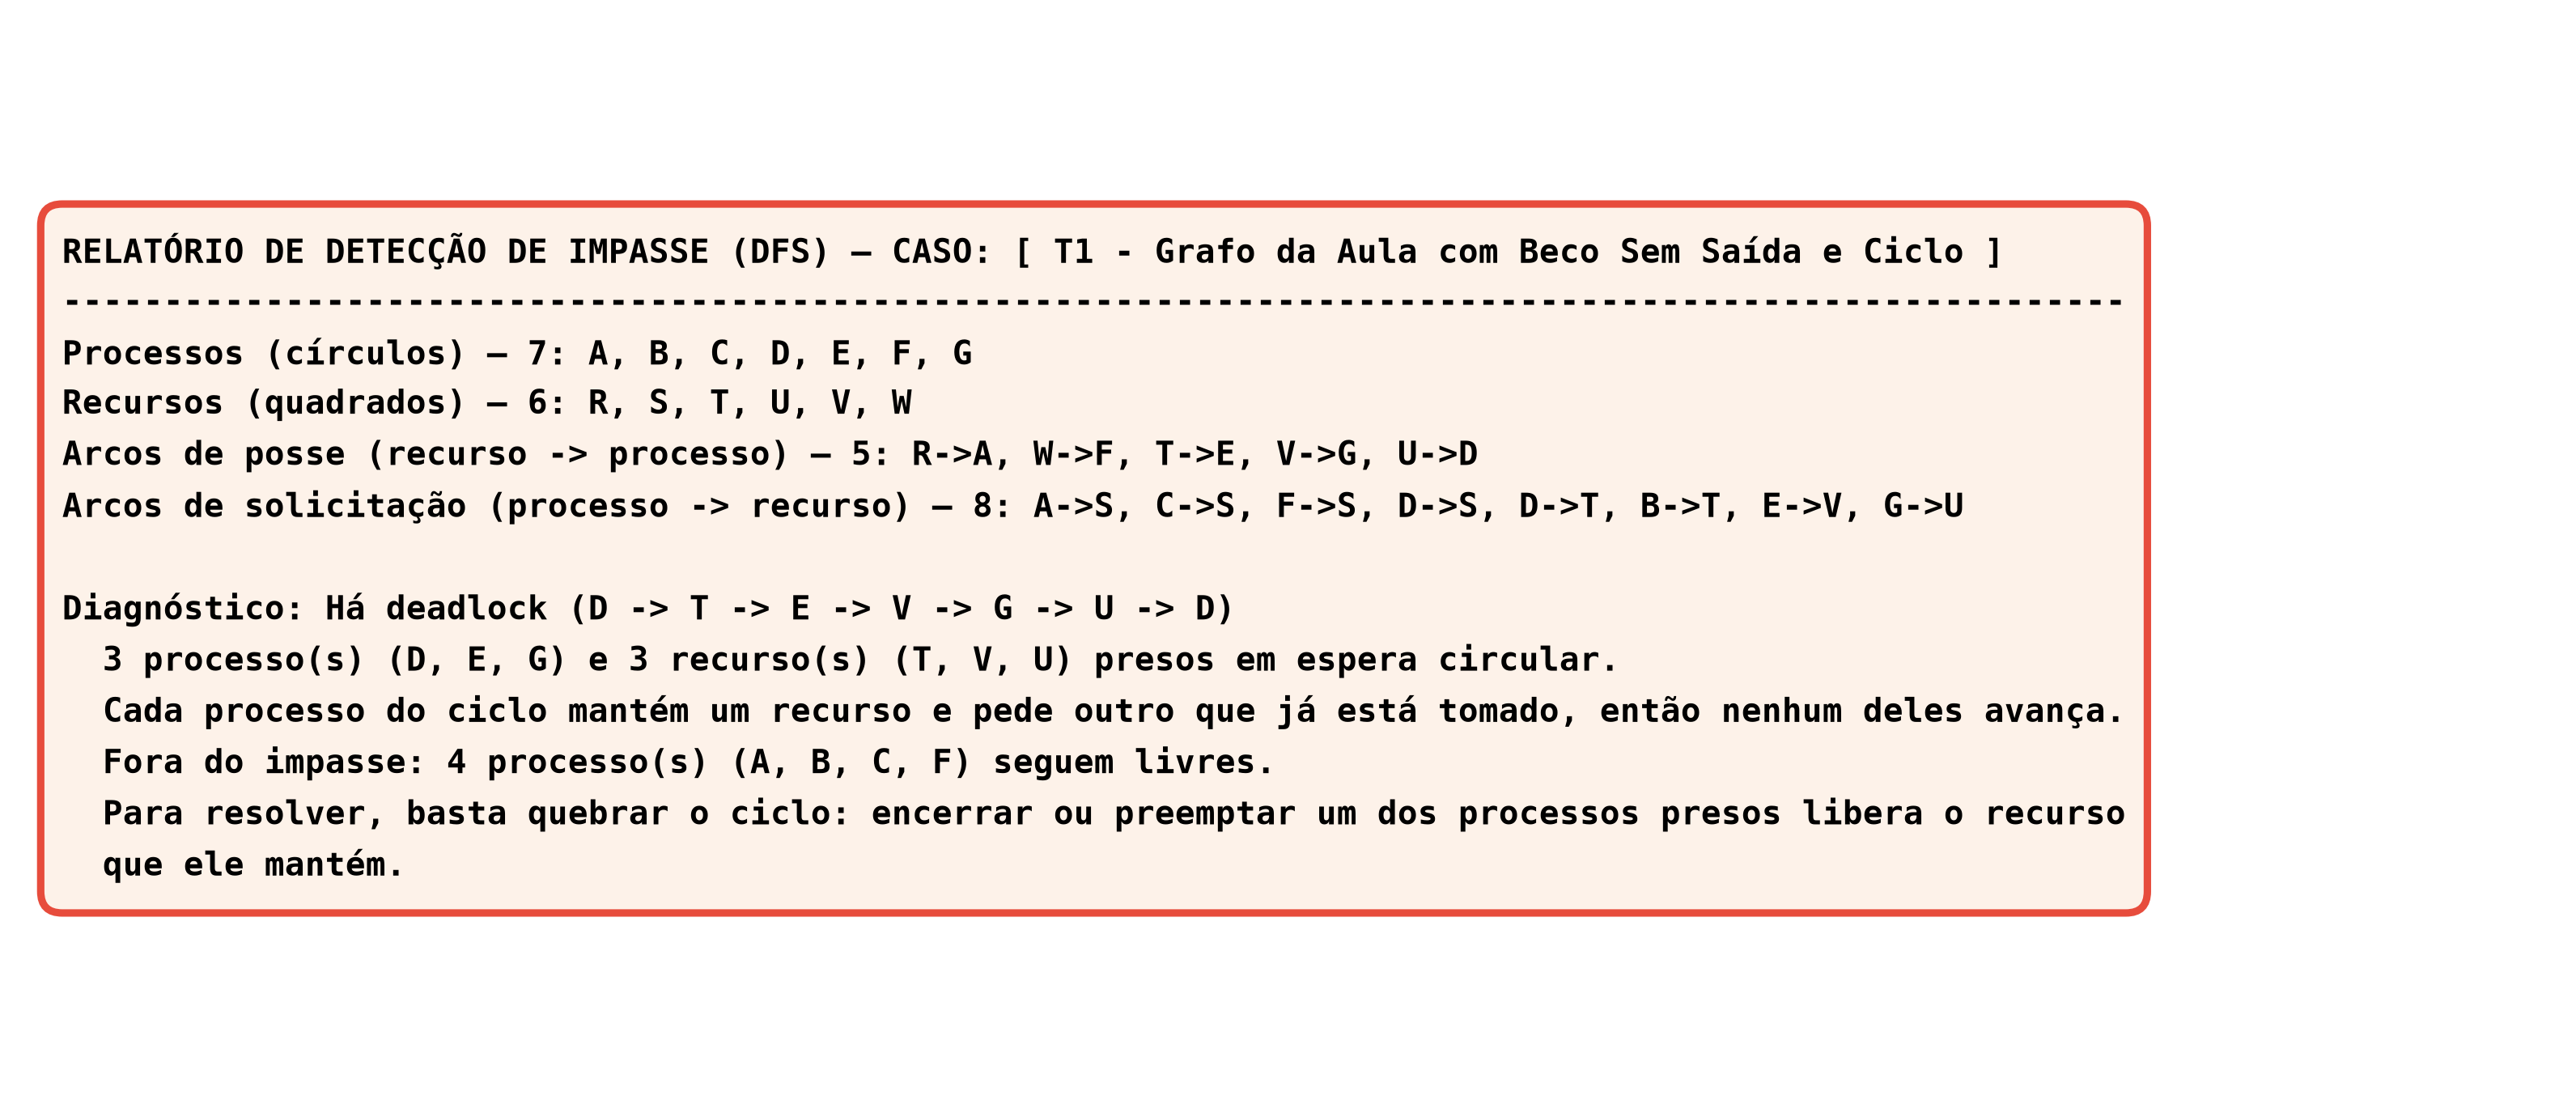

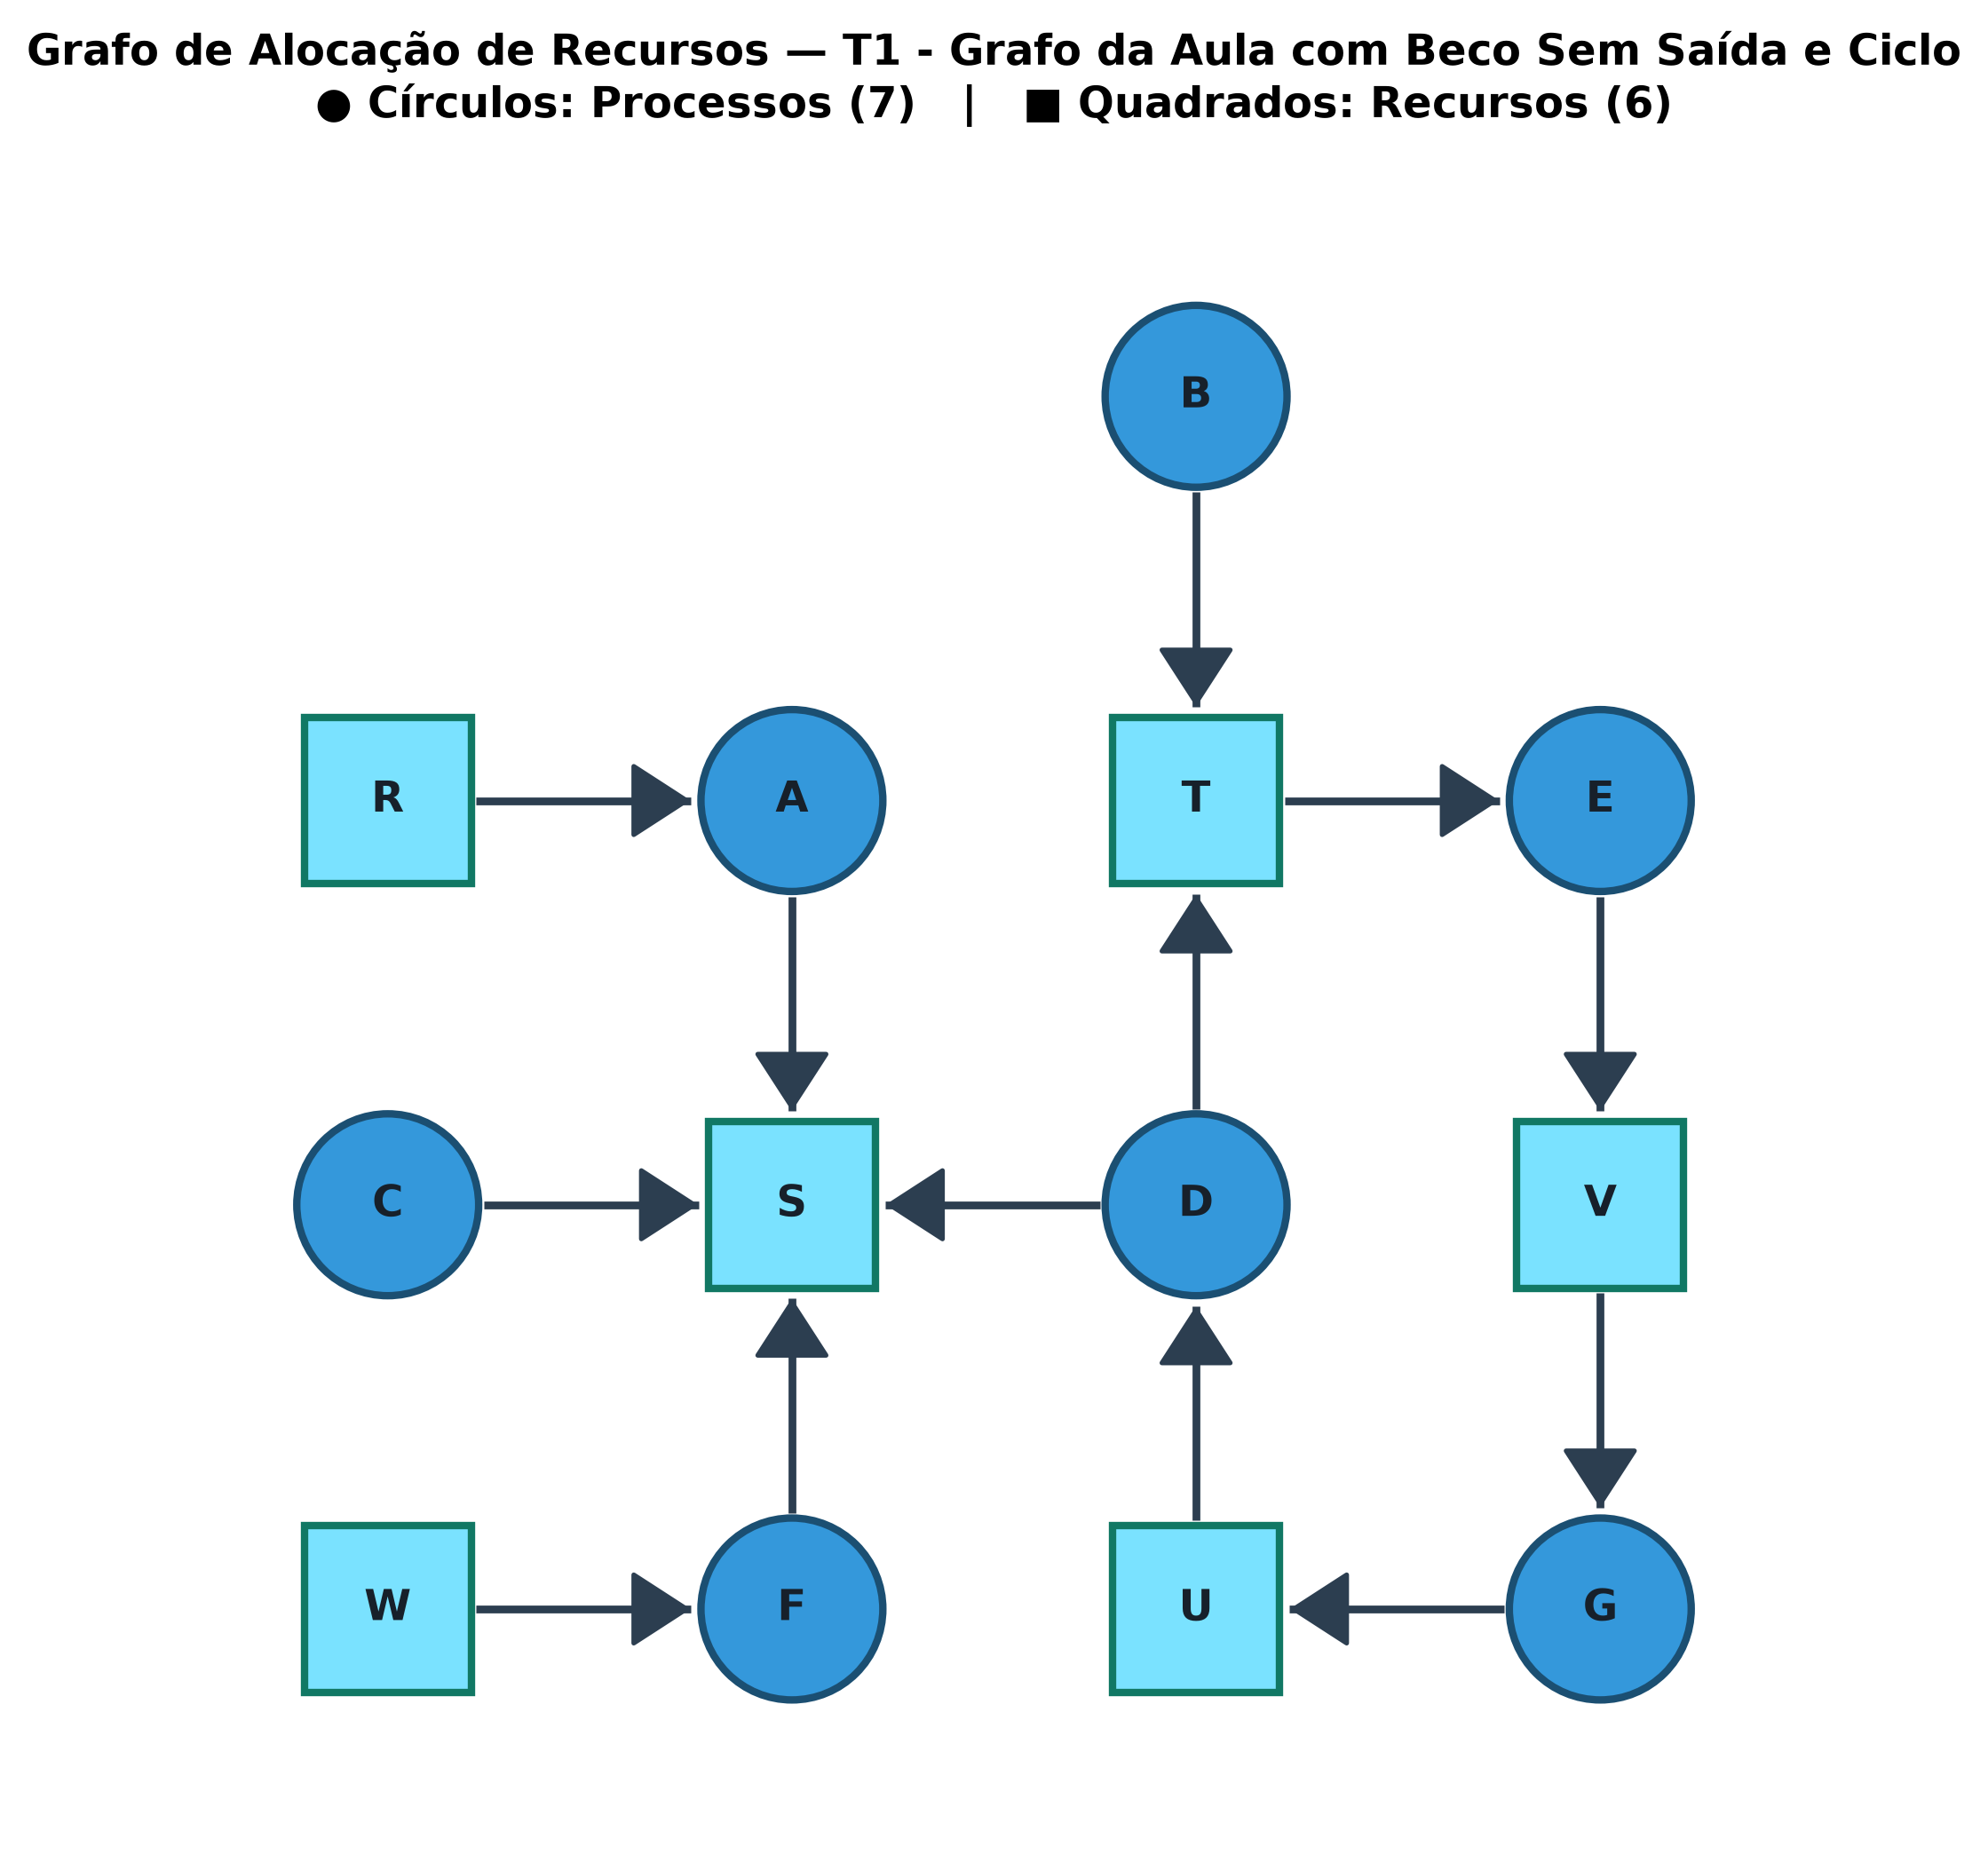

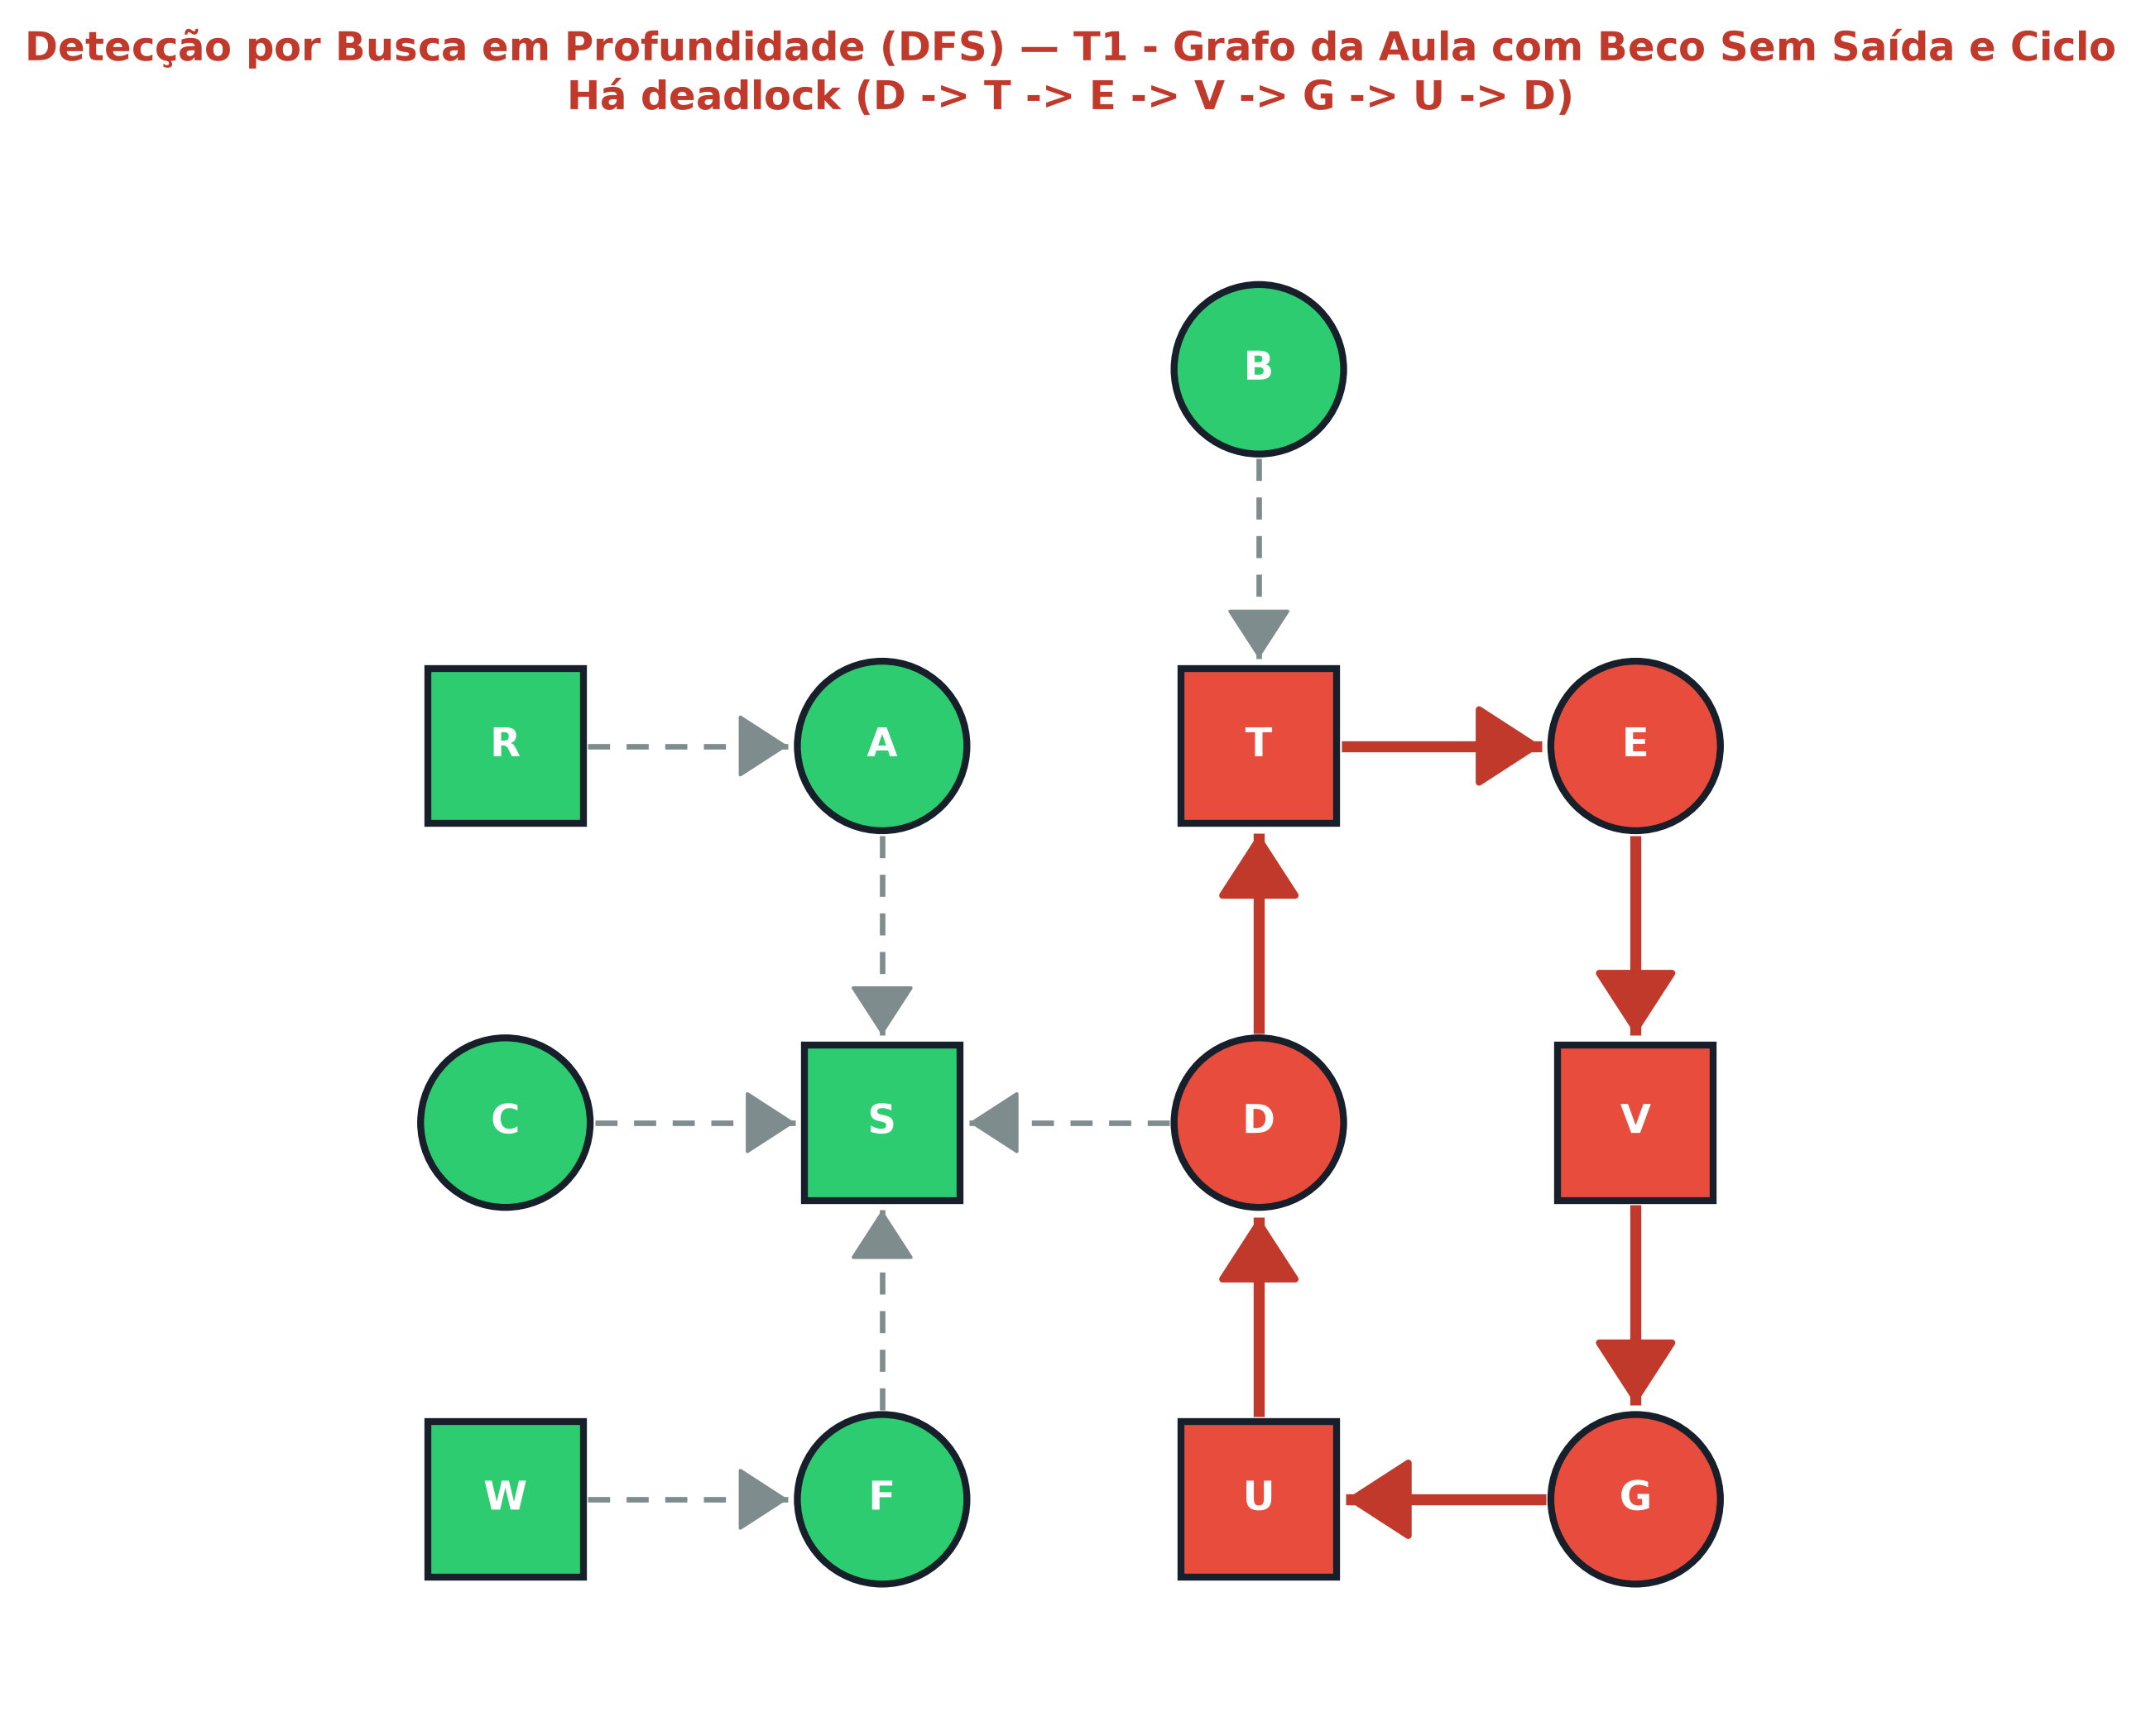

In [3]:
# [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Execução do caso T1.
caso = CASOS["T1"]
res_T1 = executar_analise_completa_caso(
    sigla=caso.sigla,
    titulo=caso.titulo,
    nome_arquivo_txt=caso.arquivo,
    buscar_todos=caso.buscar_todos,
    exibir_rastreamento_dfs=True
)


<!-- [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto do caso obrigatório T2. -->

---

## 6. Caso de Teste Obrigatório T2 — Grafo 1 do Enunciado com Deadlock

**Arquivo:** `tests/caso_grafo1_concorrente_seguro.txt`  
**Resultado esperado:** `Há deadlock (D -> T -> E -> V -> Z -> U -> D)`

Grafo 1 do enunciado (processos `B, D, E, Z, F` e recursos `T, U, V, W, S`). Os processos `D, E, Z` e os recursos `T, V, U` formam a espera circular. Ficam fora do ciclo o processo `B`, que tem o recurso `S` e espera por `T` (`S -> B -> T`), e o processo `F`, que tem o recurso `W` (`W -> F`). A chamada abaixo imprime o rastreamento da lista *L* e grava as três imagens do caso em `output/figures/`.


--- Iniciando busca DFS com raiz em 'B' ---
  [Avanço] Visitando 'B' | Lista L: ['B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['B', 'T']
    -> Marcando arco (T -> E)
  [Avanço] Visitando 'E' | Lista L: ['B', 'T', 'E']
    -> Marcando arco (E -> V)
  [Avanço] Visitando 'V' | Lista L: ['B', 'T', 'E', 'V']
    -> Marcando arco (V -> Z)
  [Avanço] Visitando 'Z' | Lista L: ['B', 'T', 'E', 'V', 'Z']
    -> Marcando arco (Z -> U)
  [Avanço] Visitando 'U' | Lista L: ['B', 'T', 'E', 'V', 'Z', 'U']
    -> Marcando arco (U -> D)
  [Avanço] Visitando 'D' | Lista L: ['B', 'T', 'E', 'V', 'Z', 'U', 'D']
    -> Marcando arco (D -> T)
  [CICLO DETECTADO!] Nó 'T' repetido em L=['B', 'T', 'E', 'V', 'Z', 'U', 'D', 'T'] -> Ciclo extraído: D -> T -> E -> V -> Z -> U -> D

Resultado Oficial: Há deadlock (D -> T -> E -> V -> Z -> U -> D)
[Imagens salvas em:]
  - output/figures/T2_grafo_1_do_enunciado_com_deadlock_cartao.png
  - output/figures/T2_grafo_1_do_enunciado_com_deadlock_gra

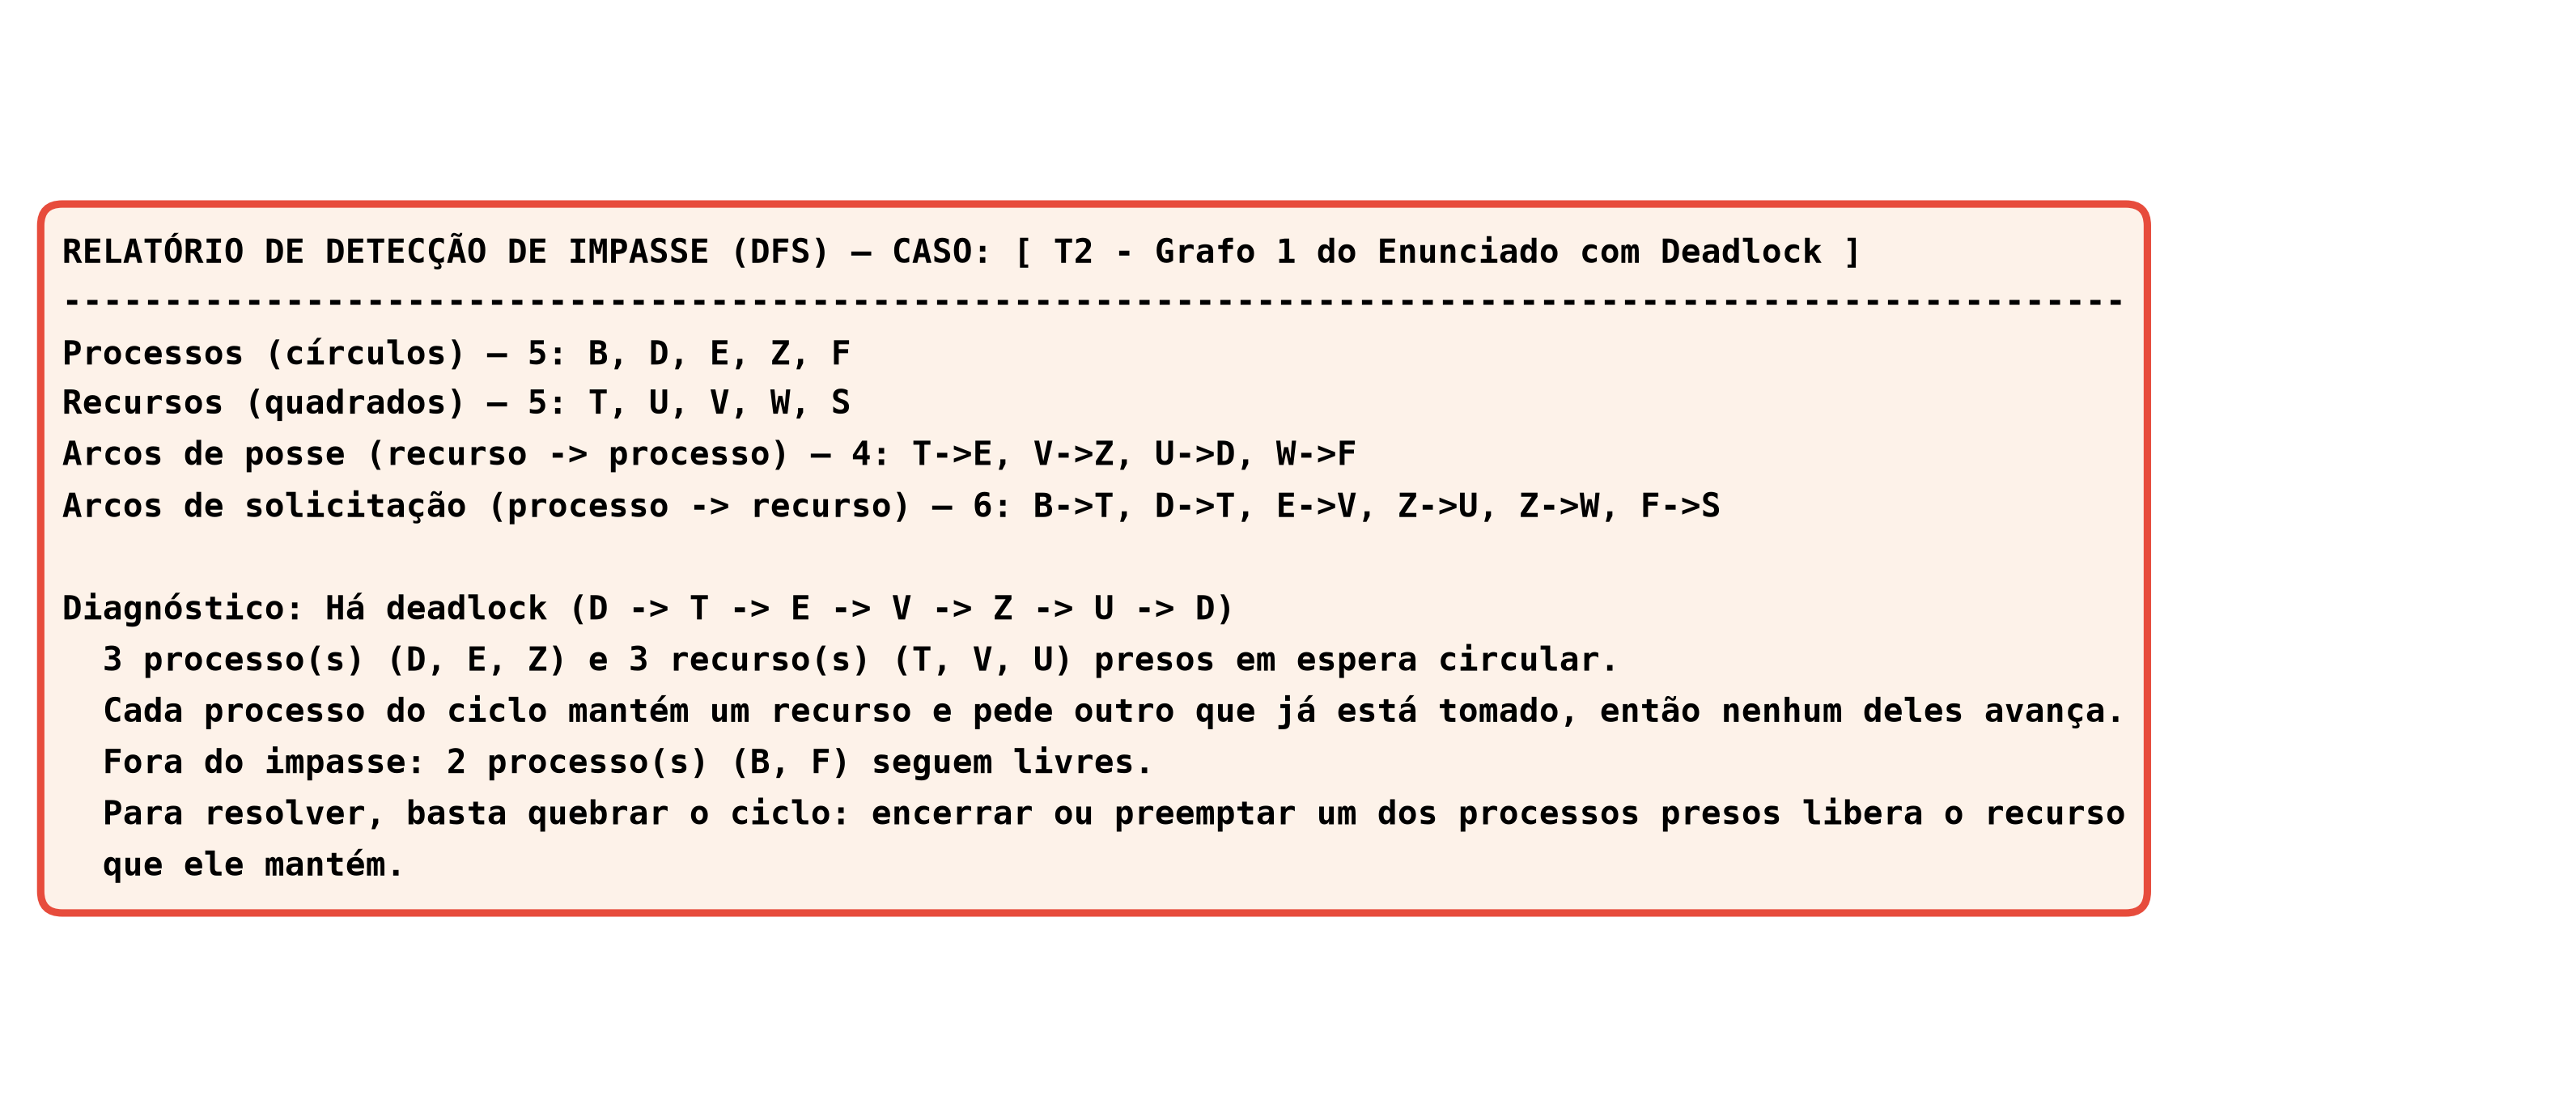

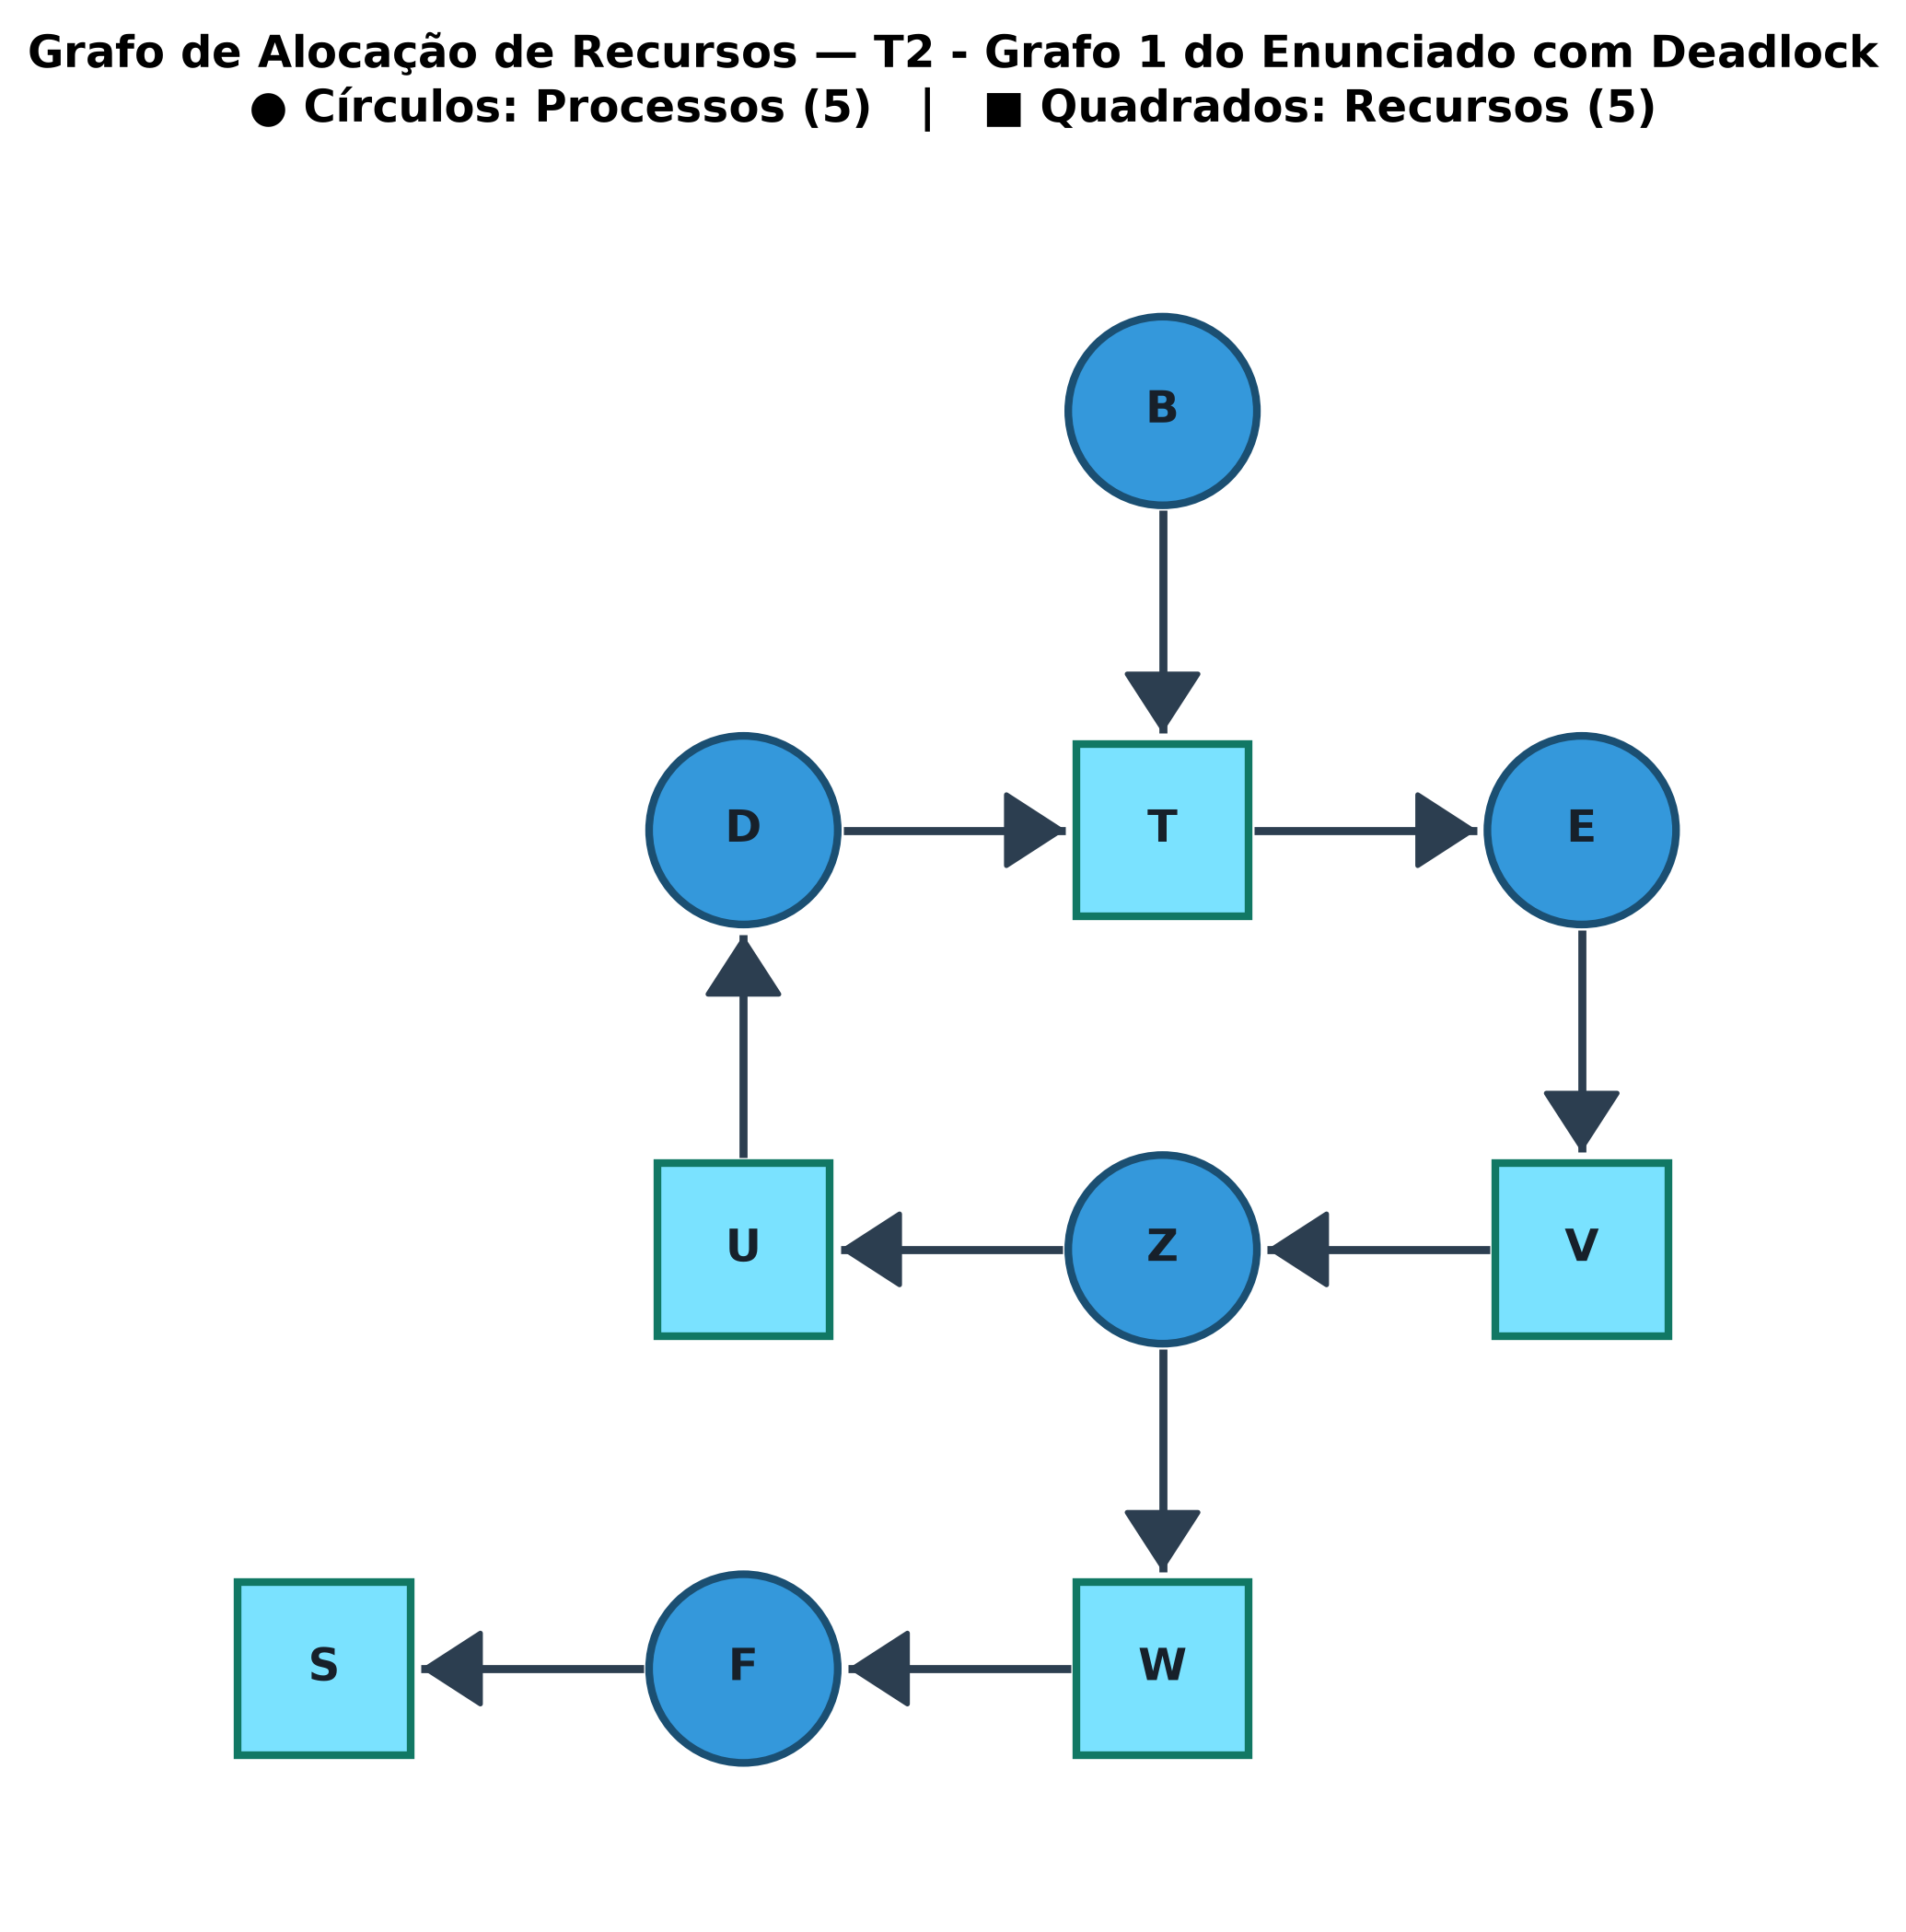

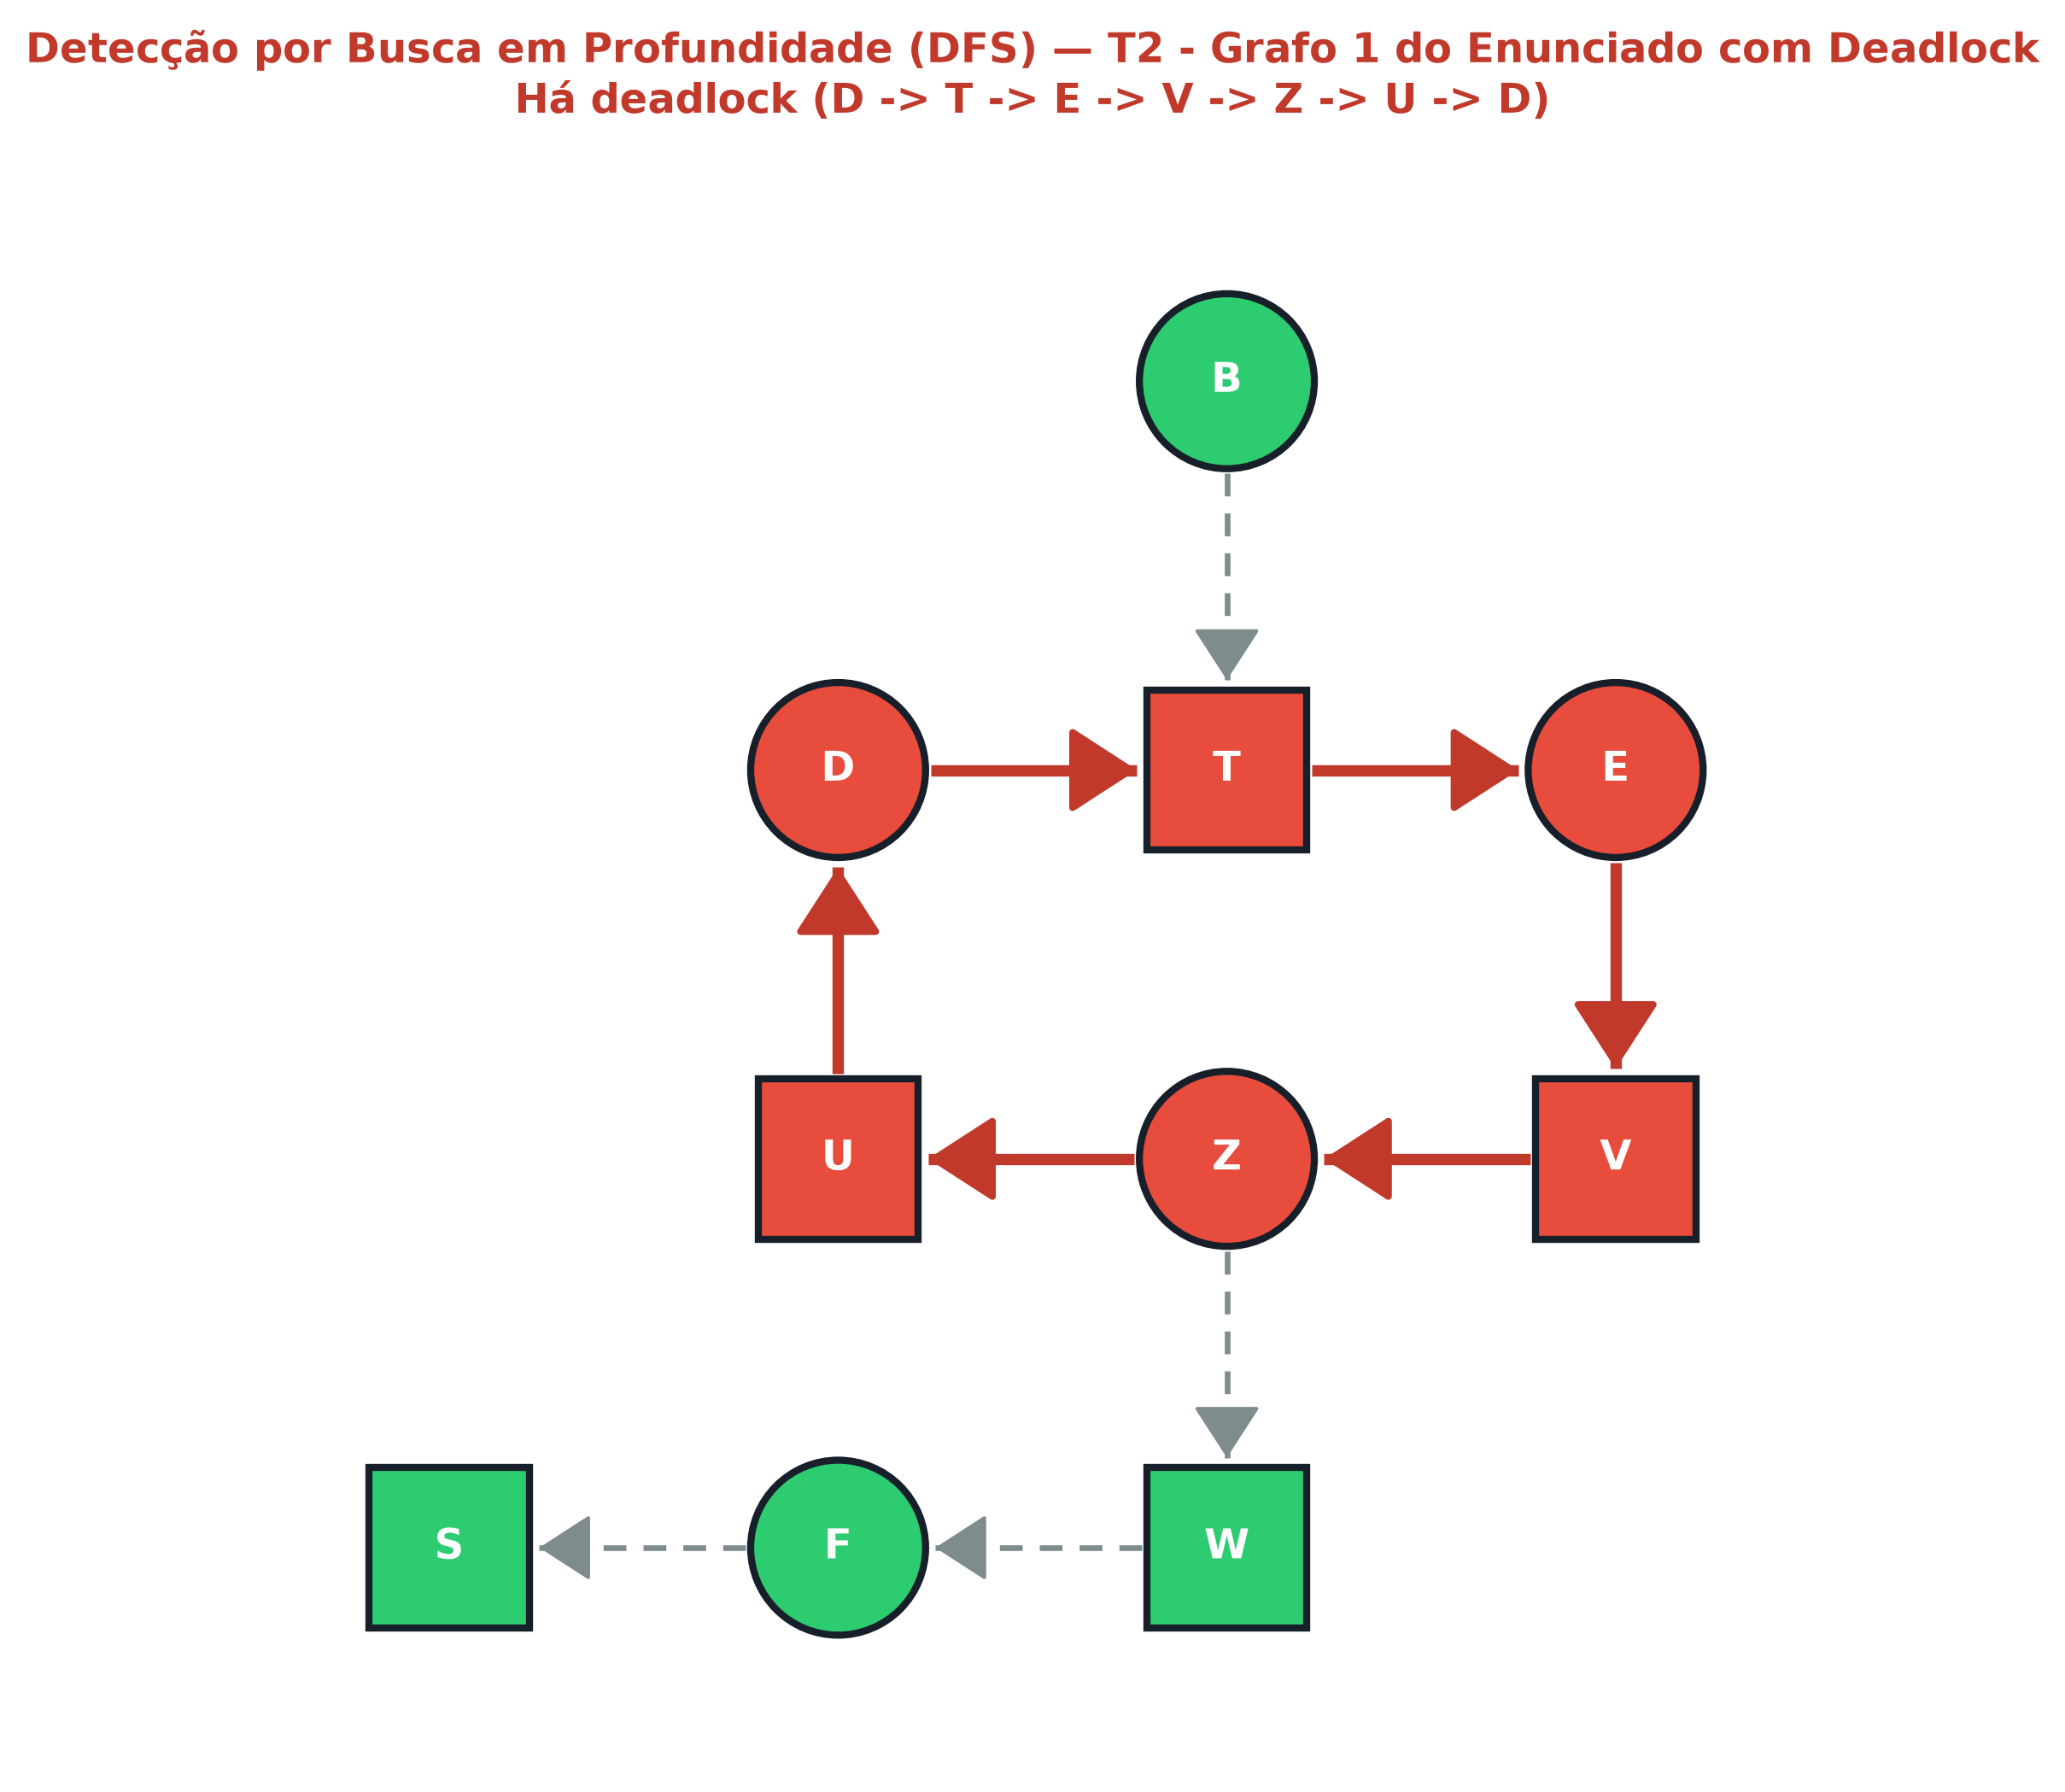

In [4]:
# [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Execução do caso T2.
caso = CASOS["T2"]
res_T2 = executar_analise_completa_caso(
    sigla=caso.sigla,
    titulo=caso.titulo,
    nome_arquivo_txt=caso.arquivo,
    buscar_todos=caso.buscar_todos,
    exibir_rastreamento_dfs=True
)


<!-- [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto do caso obrigatório T3. -->

---

## 7. Caso de Teste Obrigatório T3 — Grafo 2 do Enunciado sem Deadlock

**Arquivo:** `tests/caso_grafo2_espera_circular.txt`  
**Resultado esperado:** `Sem deadlock`

Grafo 2 do enunciado (8 processos e 6 recursos). Há várias esperas encadeadas, mas toda busca termina num beco sem saída e retrocede até a raiz sem repetir nó na lista *L*: não existe espera circular, logo não há impasse. A chamada abaixo imprime o rastreamento da lista *L* e grava as três imagens do caso em `output/figures/`.


--- Iniciando busca DFS com raiz em 'A' ---
  [Avanço] Visitando 'A' | Lista L: ['A']
    -> Marcando arco (A -> S)
  [Avanço] Visitando 'S' | Lista L: ['A', 'S']
    -> Marcando arco (S -> D)
  [Avanço] Visitando 'D' | Lista L: ['A', 'S', 'D']
    -> Marcando arco (D -> T)
  [Avanço] Visitando 'T' | Lista L: ['A', 'S', 'D', 'T']
    -> Marcando arco (T -> E)
  [Avanço] Visitando 'E' | Lista L: ['A', 'S', 'D', 'T', 'E']
  [Retrocesso] Beco sem saída em 'E' | Lista L: ['A', 'S', 'D', 'T']
  [Retrocesso] Beco sem saída em 'T' | Lista L: ['A', 'S', 'D']
  [Retrocesso] Beco sem saída em 'D' | Lista L: ['A', 'S']
  [Retrocesso] Beco sem saída em 'S' | Lista L: ['A']
  [Retrocesso] Beco sem saída em 'A' | Lista L: []
--- Iniciando busca DFS com raiz em 'B' ---
  [Avanço] Visitando 'B' | Lista L: ['B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['B', 'T']
    -> Marcando arco (T -> E)
  [Avanço] Visitando 'E' | Lista L: ['B', 'T', 'E']
  [Retrocesso] Beco sem saída em '

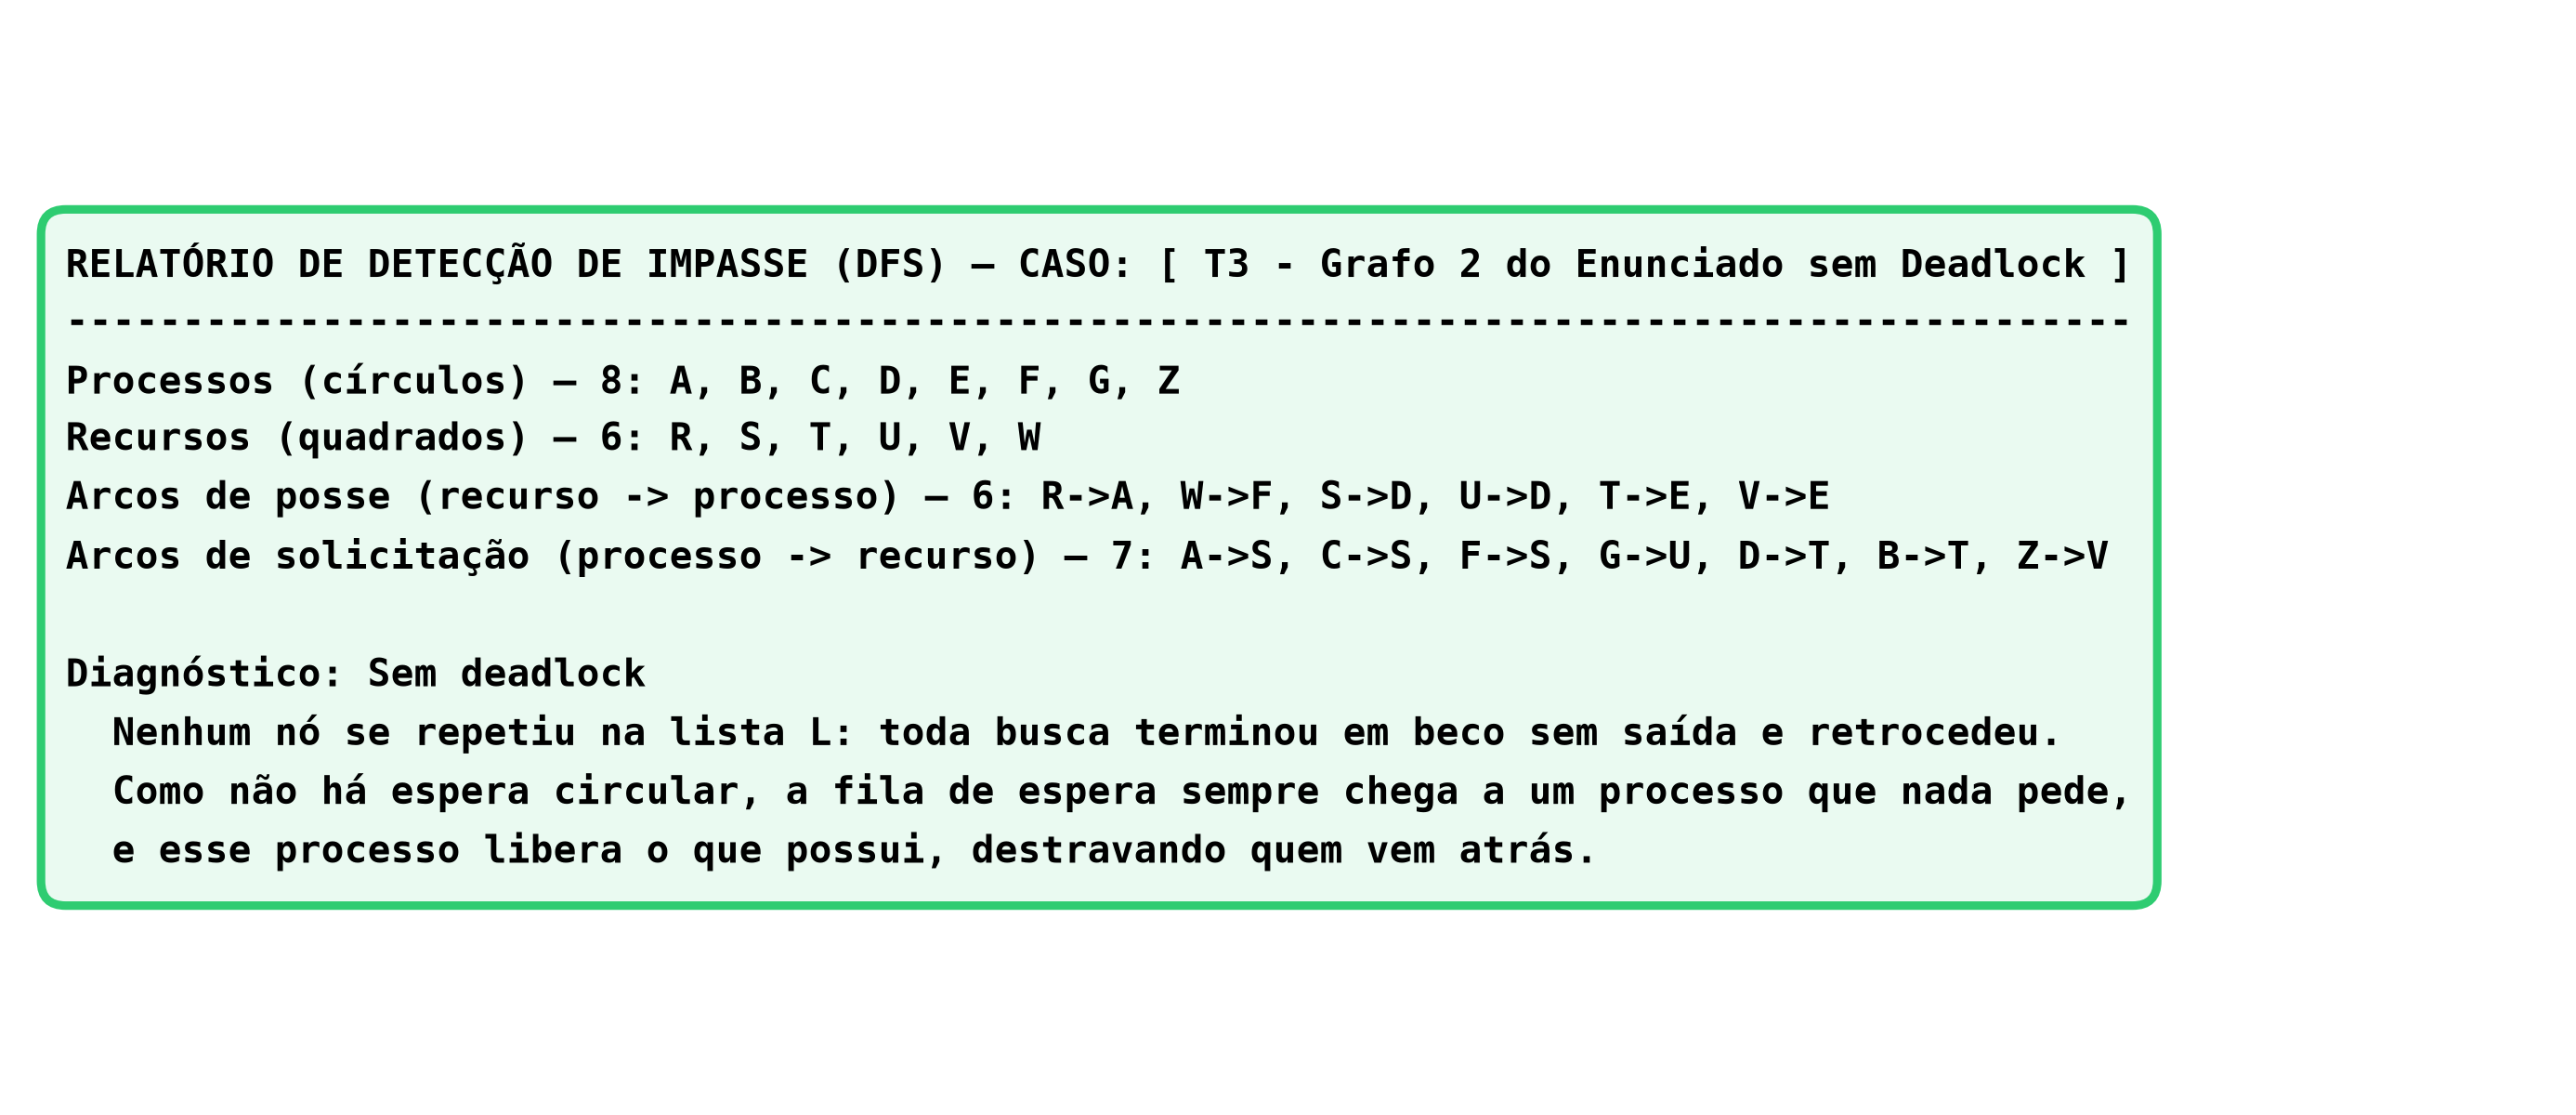

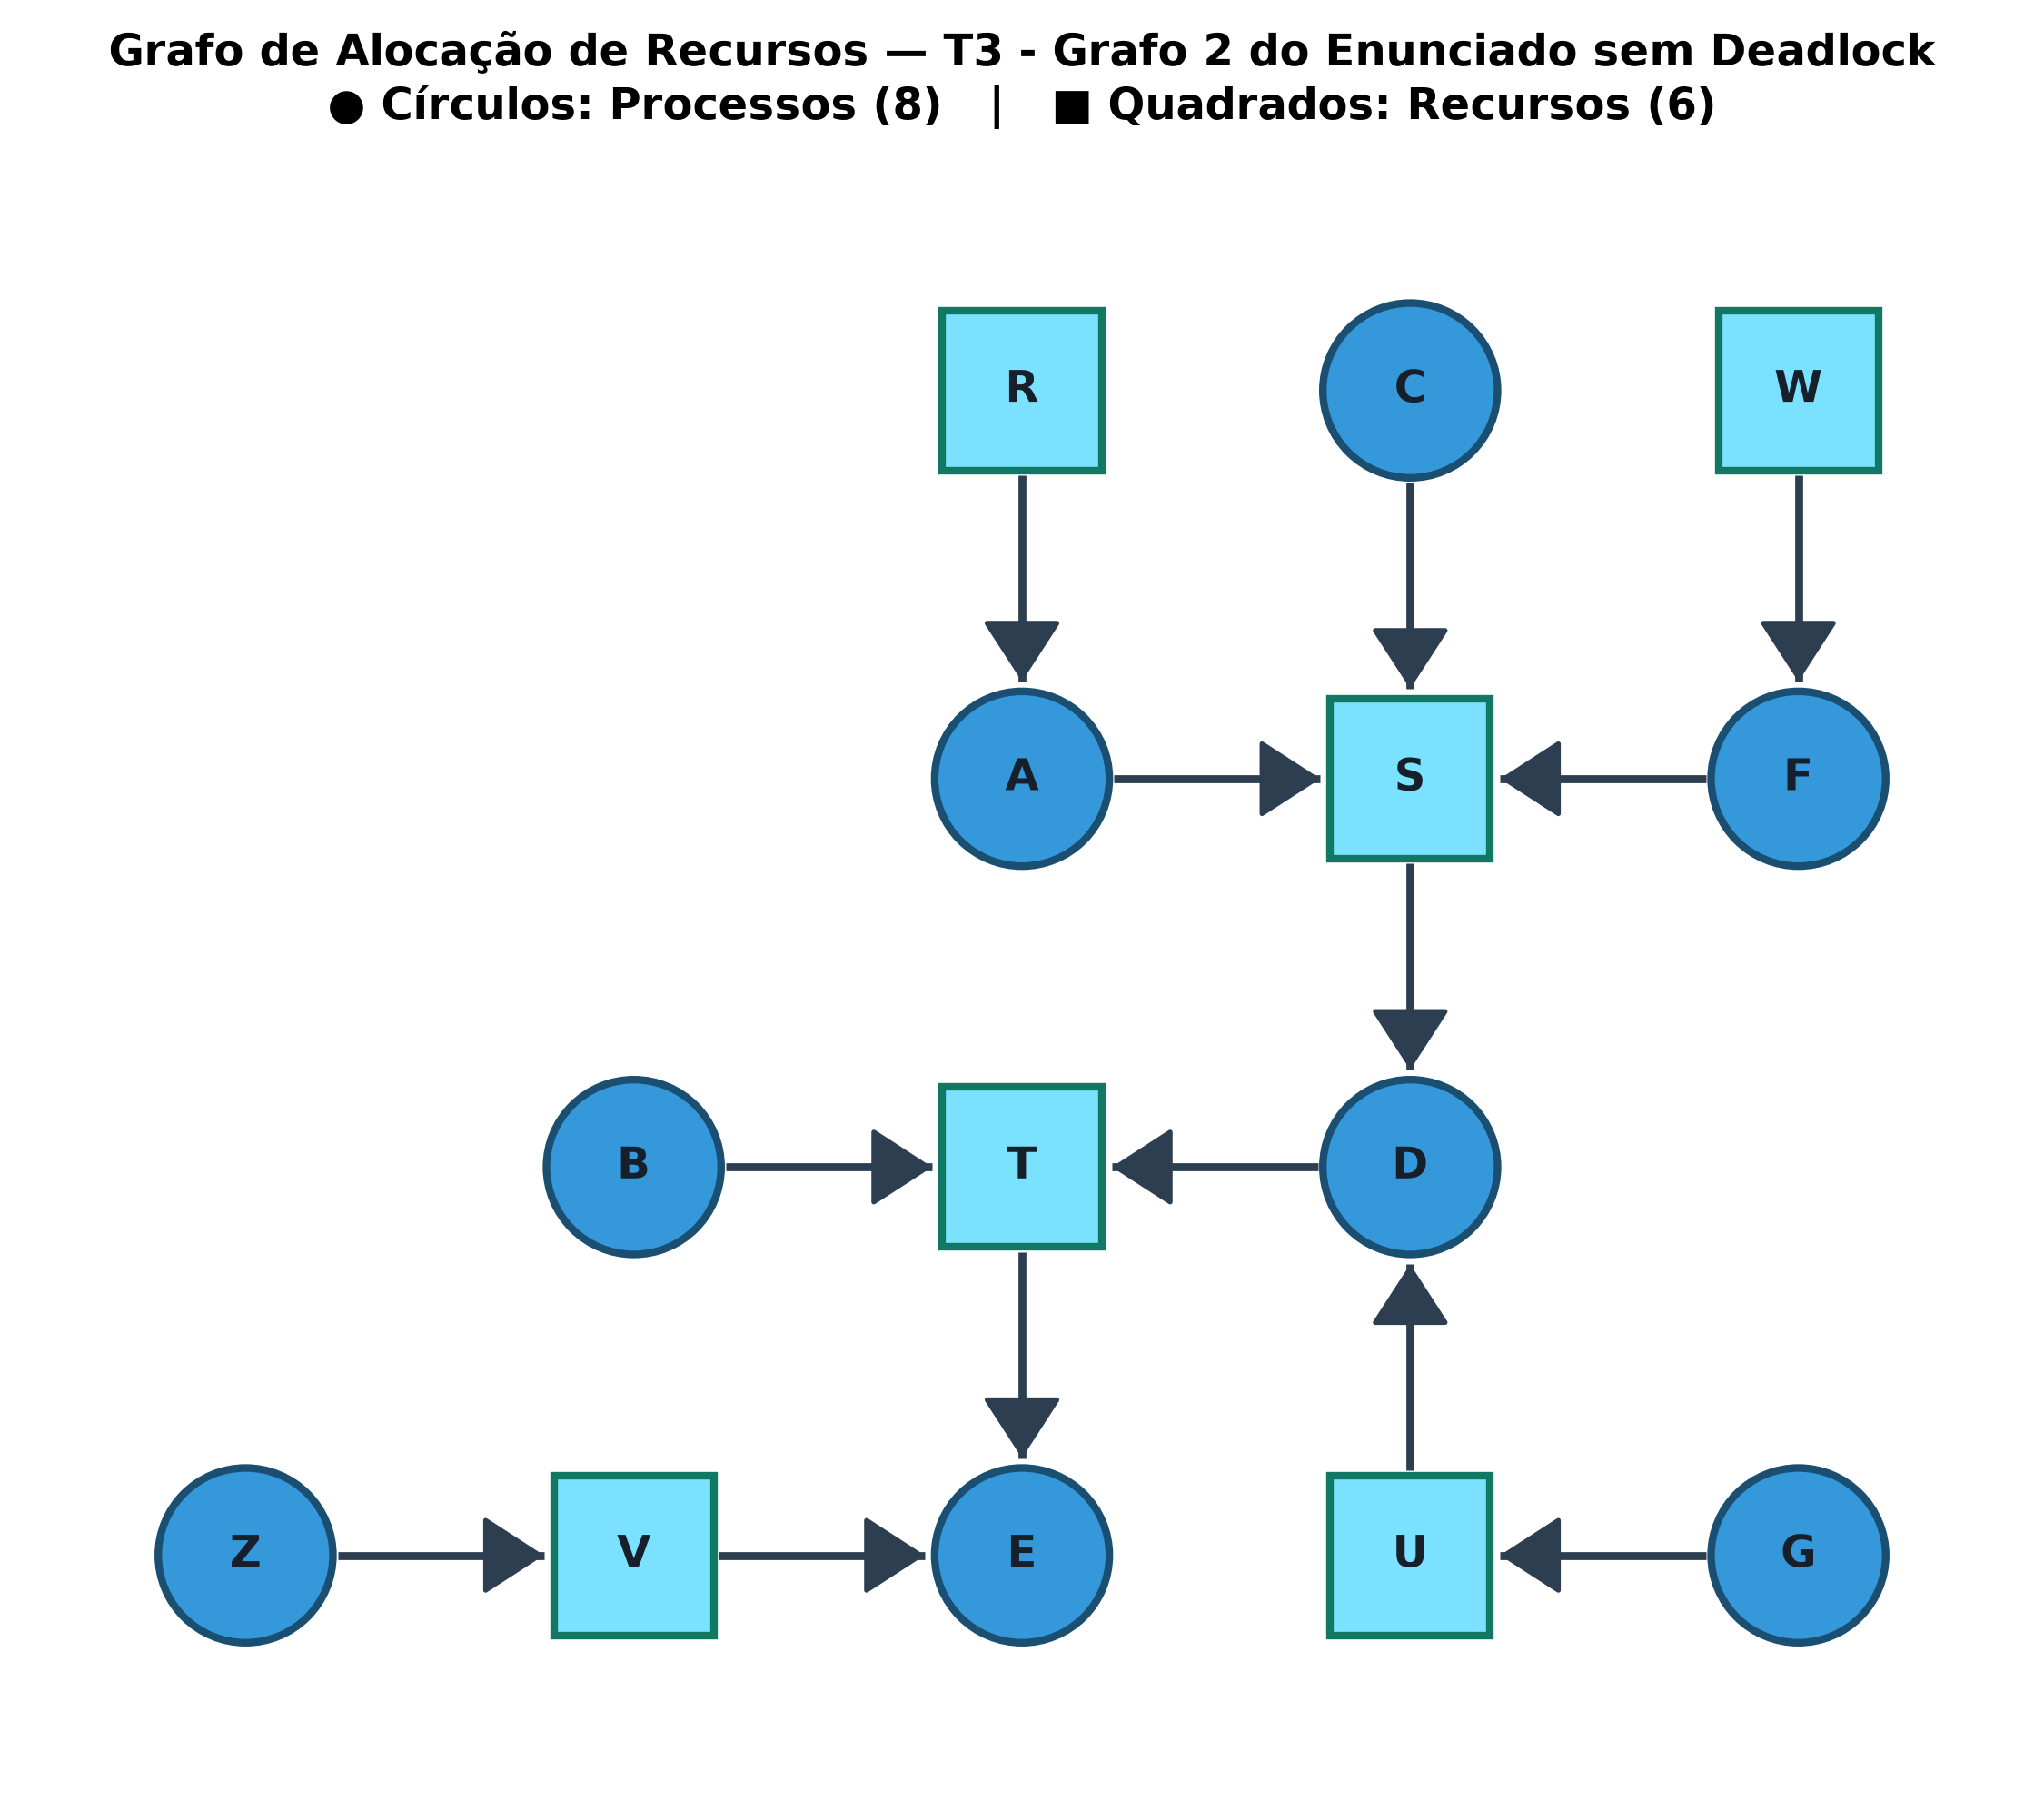

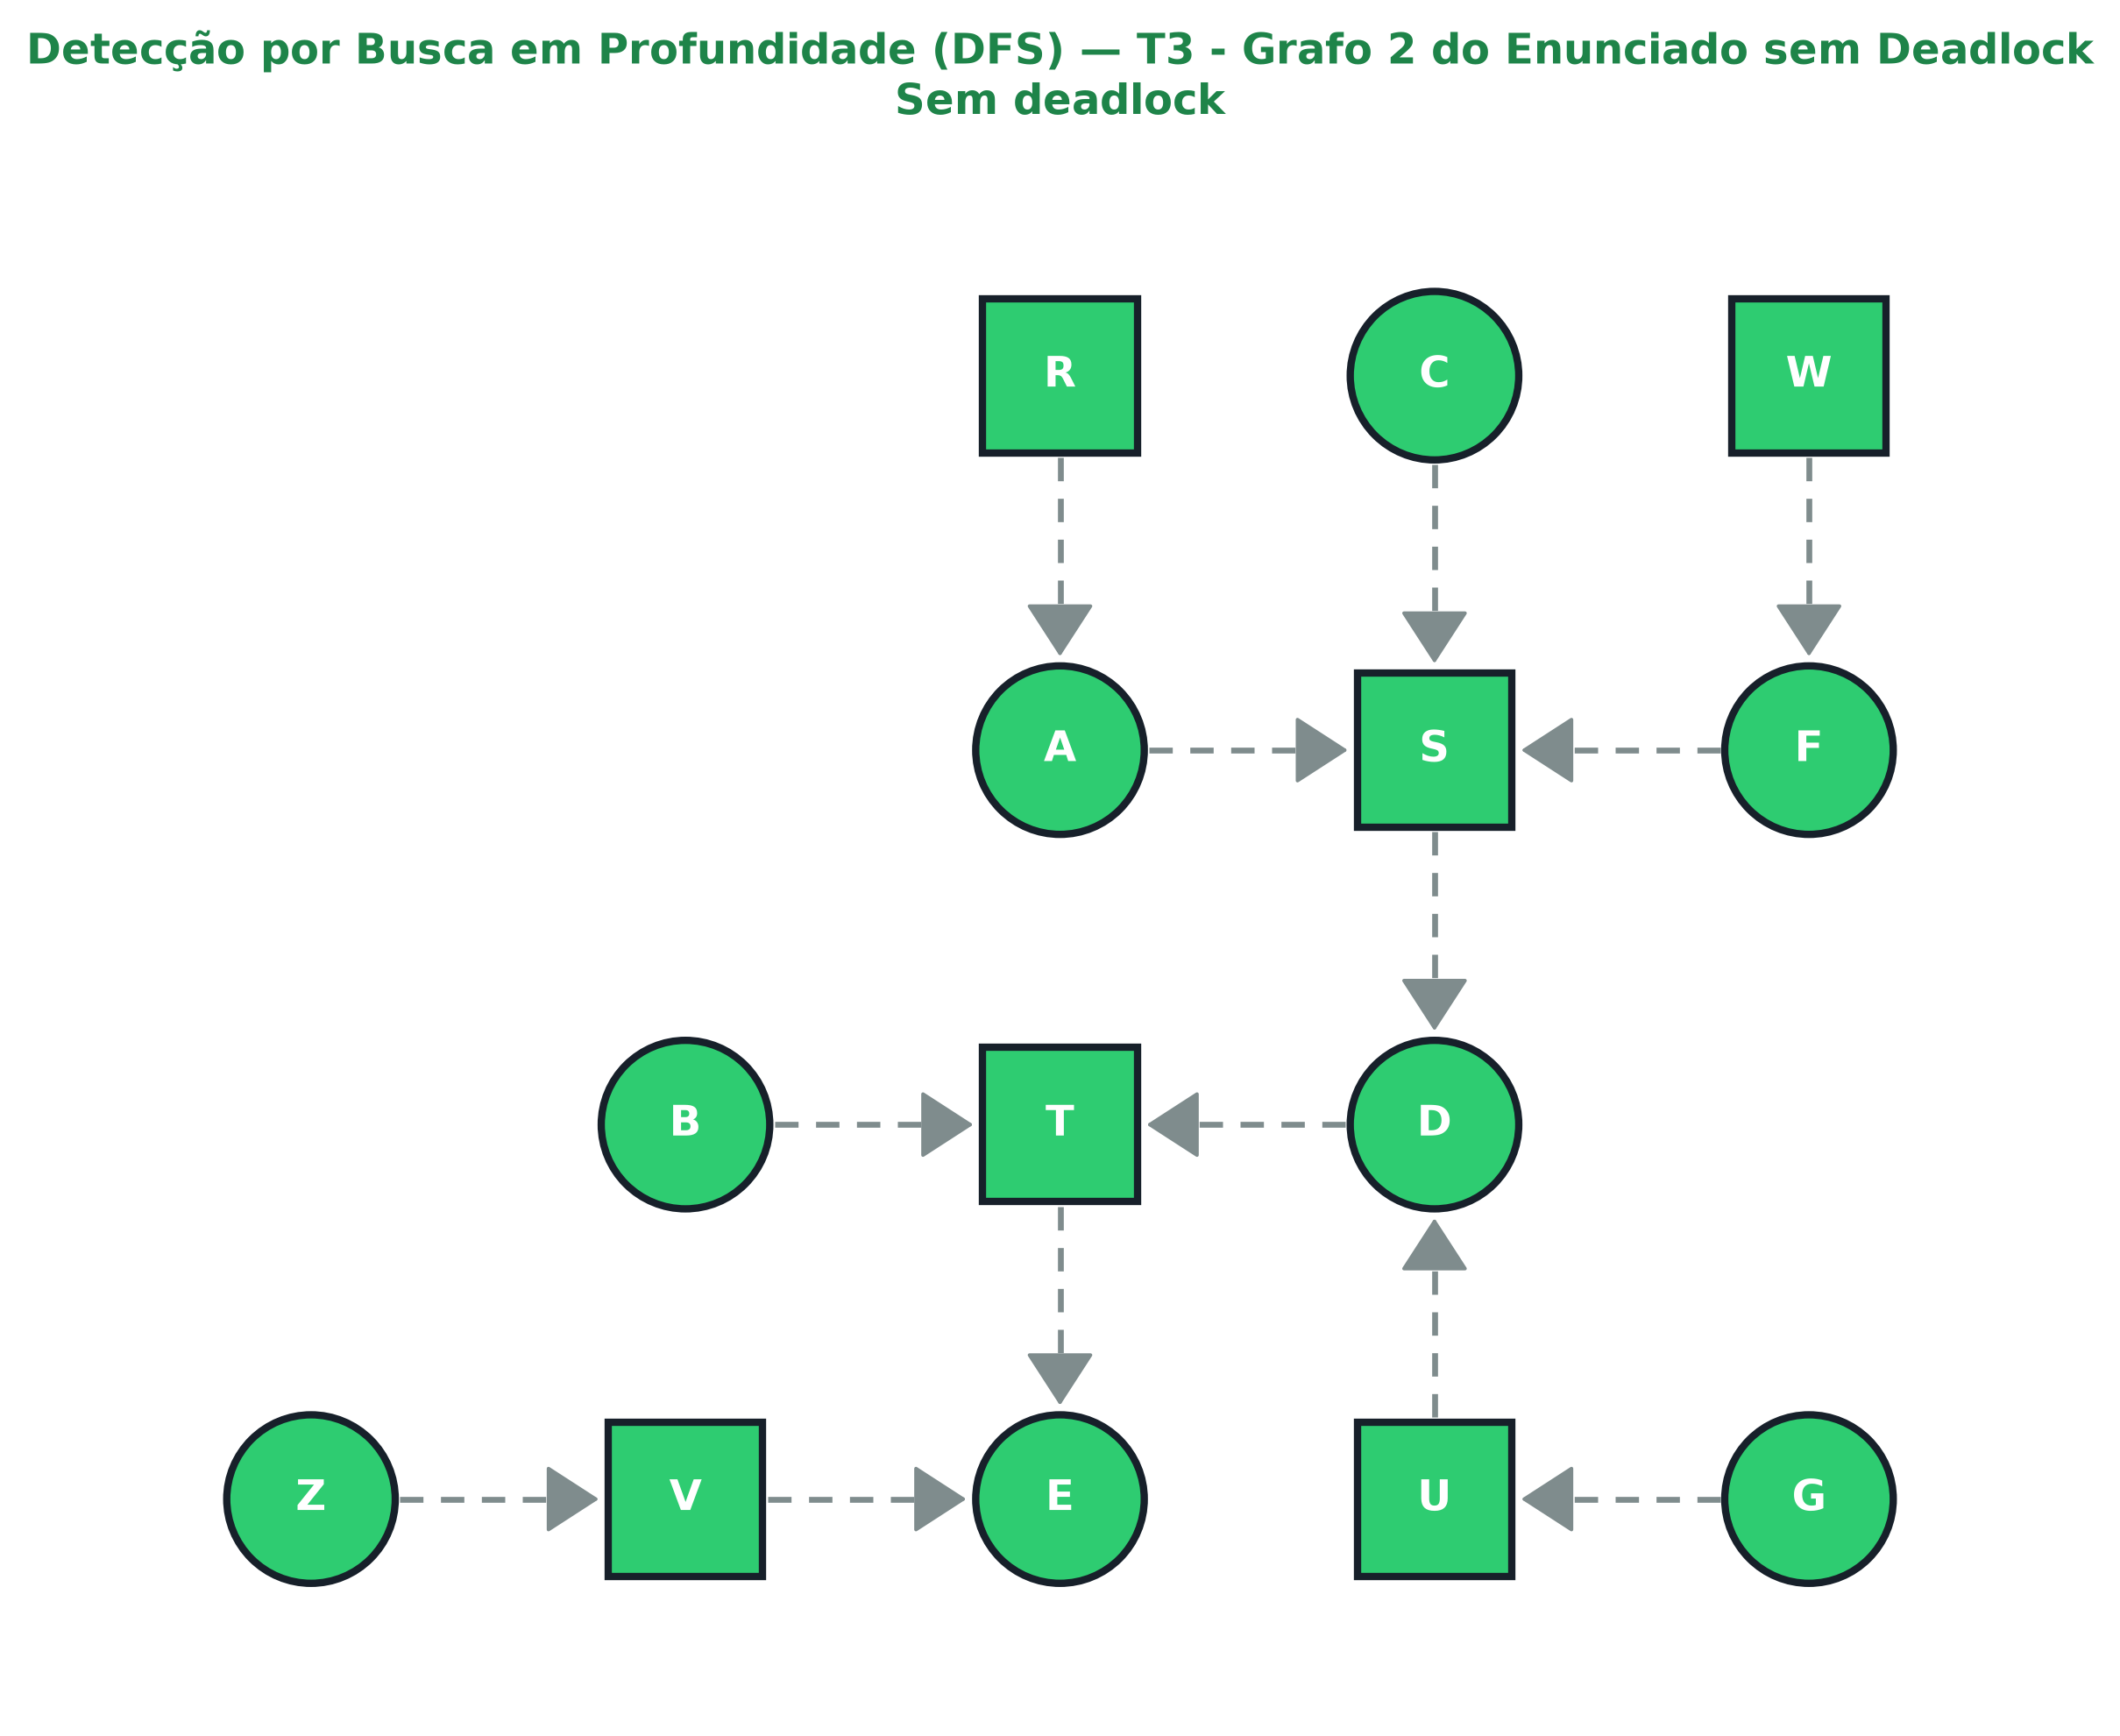

In [5]:
# [PASSO 5.3 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Execução do caso T3.
caso = CASOS["T3"]
res_T3 = executar_analise_completa_caso(
    sigla=caso.sigla,
    titulo=caso.titulo,
    nome_arquivo_txt=caso.arquivo,
    buscar_todos=caso.buscar_todos,
    exibir_rastreamento_dfs=True
)


<!-- [PASSO 5.4 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto dos casos opcionais T4 a T7. -->

---

## 8. Casos de Teste Opcionais (T4 a T7)

Os casos opcionais rodam em um laço sobre `CASOS_DE_TESTE_OFICIAIS`, sem nada escrito à mão: quem acrescentar um novo `CasoDeTeste` na Etapa 6 vê o caso aparecer aqui automaticamente, com as suas três imagens.

* **T4** — dois ciclos disjuntos (*Slides* 30(c) e 36), desenhados pelo círculo trigonométrico autoajustável, um círculo por ciclo;
* **T5** — um ciclo de três processos com um quarto processo esperando de fora, que fica fora do impasse;
* **T6** — cadeia longa de espera que termina em um processo livre, sem deadlock;
* **T7** — dois impasses simultâneos convivendo com um ramo livre (`R5 -> P5`).

Nos casos com mais de um ciclo (T4 e T7), o gabarito usa `buscar_todos=True`, e a saída lista cada ciclo numa linha.



=== T4 - Dois Ciclos Disjuntos com Impasse Duplo ===
Resultado Oficial: Há deadlock (2 ciclos encontrados):
  Ciclo 1: A -> S -> B -> R -> A
  Ciclo 2: C -> U -> D -> T -> C
[Imagens salvas em:]
  - output/figures/T4_dois_ciclos_disjuntos_com_impasse_duplo_cartao.png
  - output/figures/T4_dois_ciclos_disjuntos_com_impasse_duplo_grafo_alocacao.png
  - output/figures/T4_dois_ciclos_disjuntos_com_impasse_duplo_grafo_deteccao_dfs.png


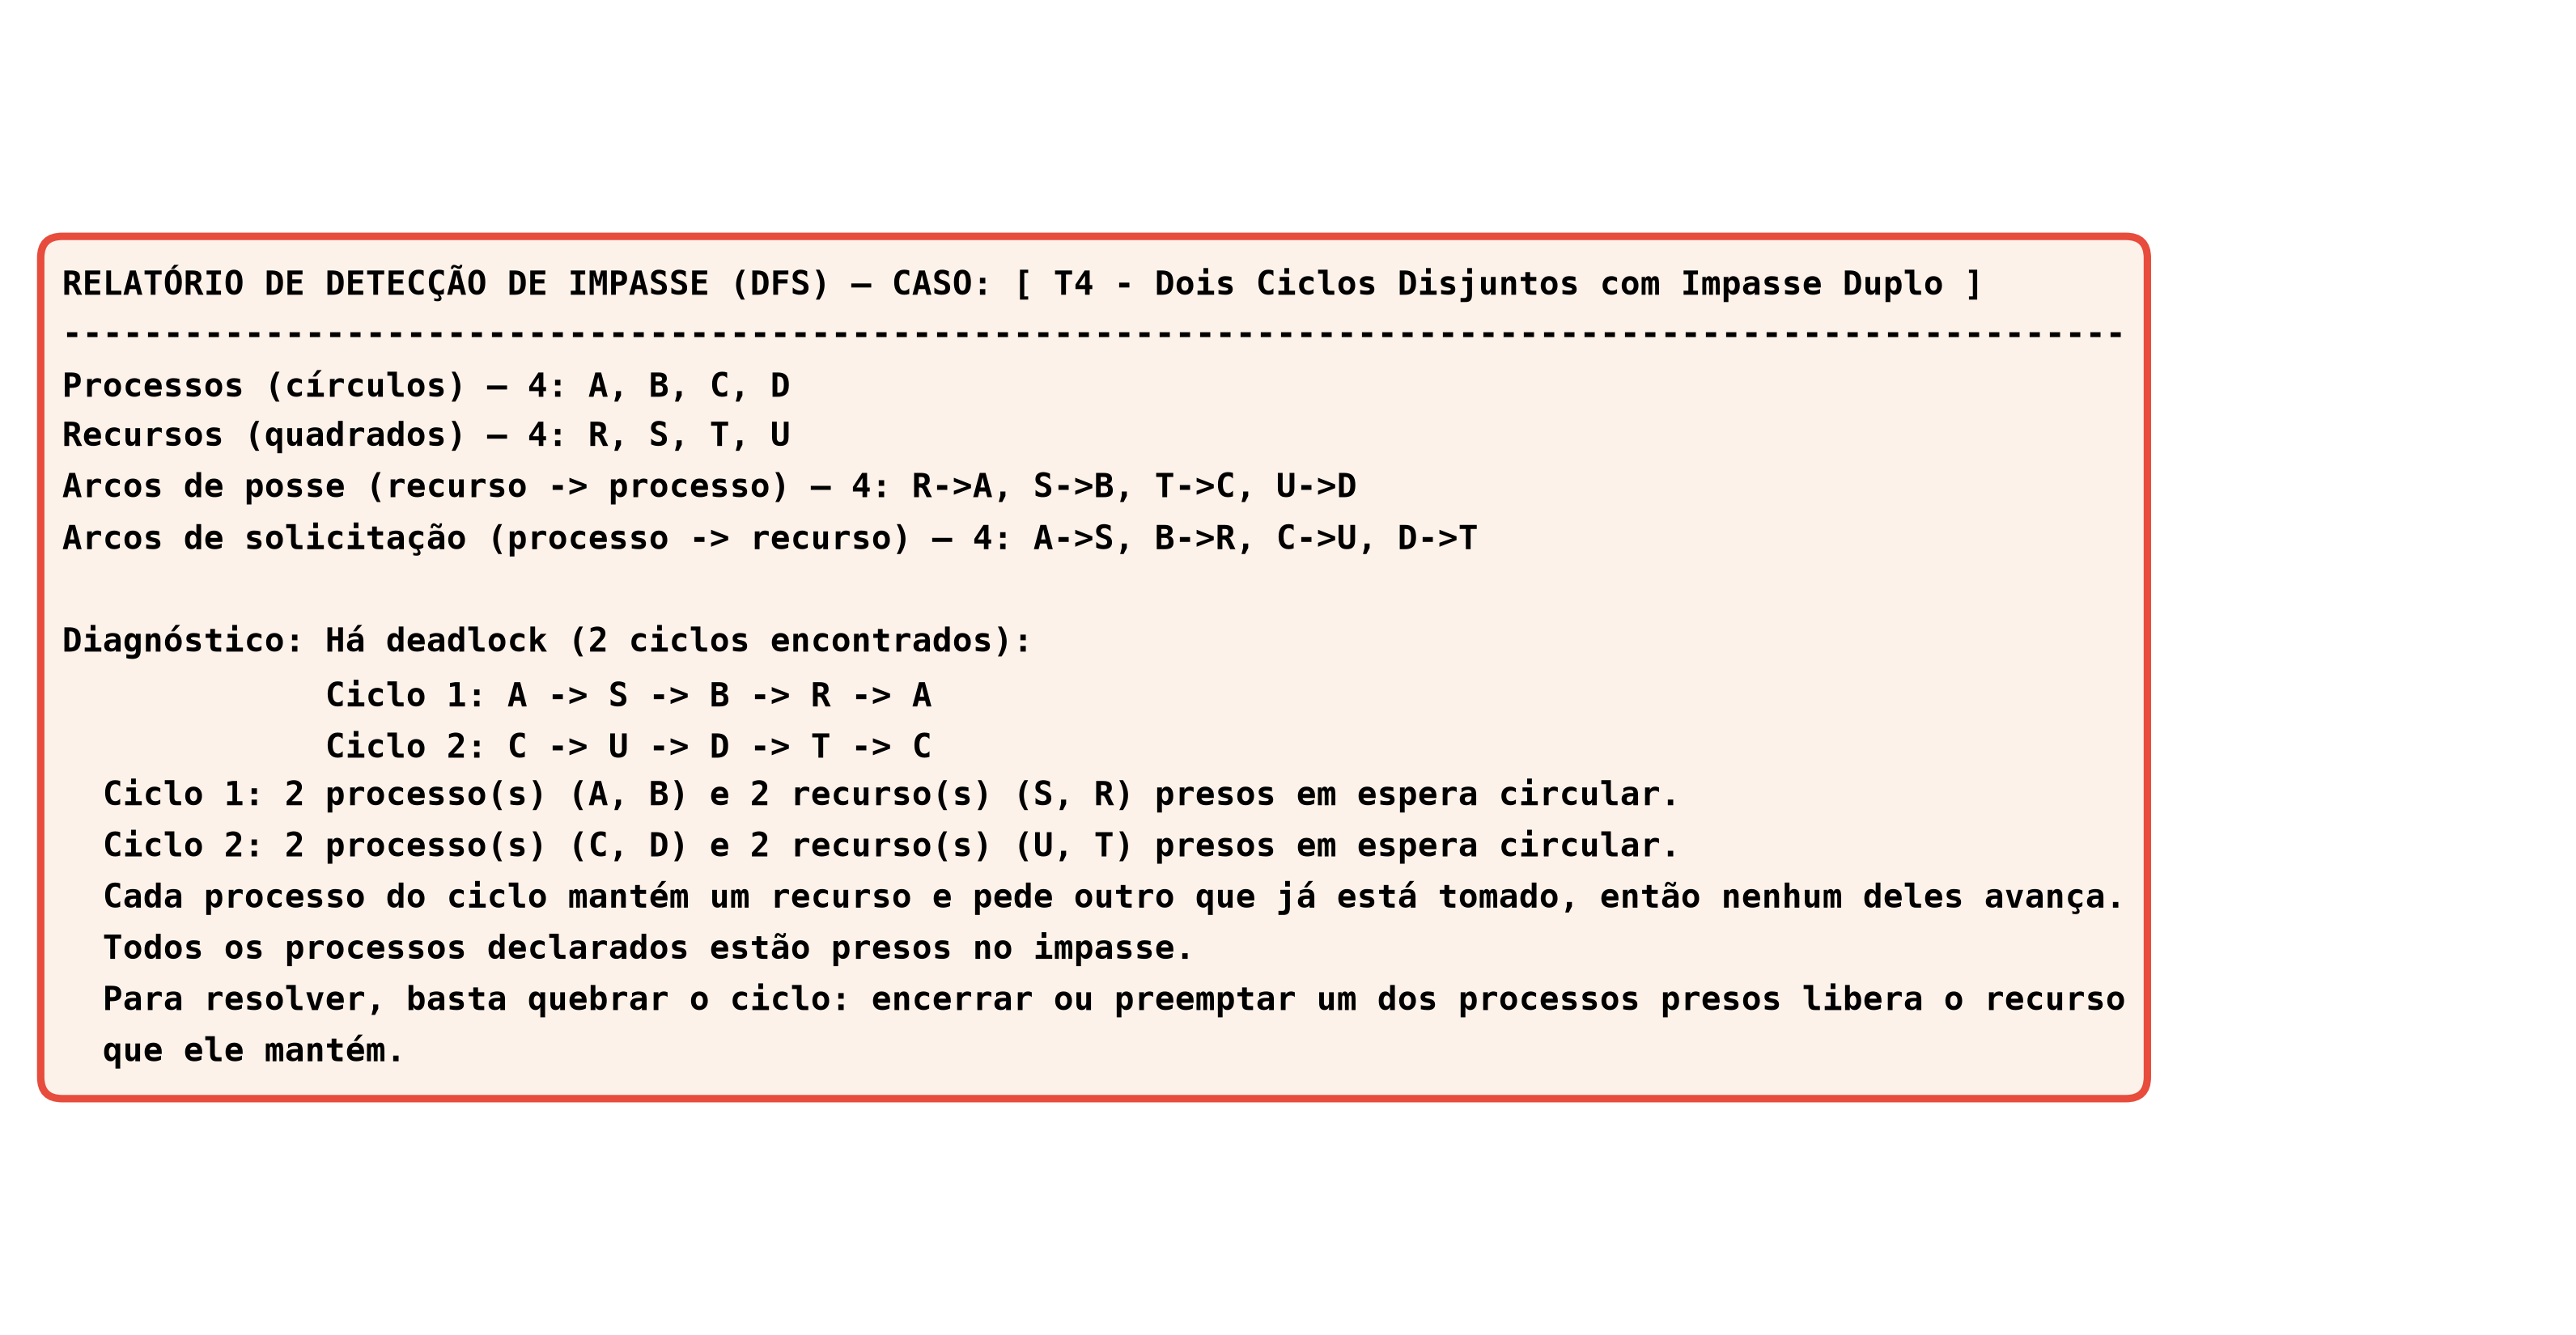

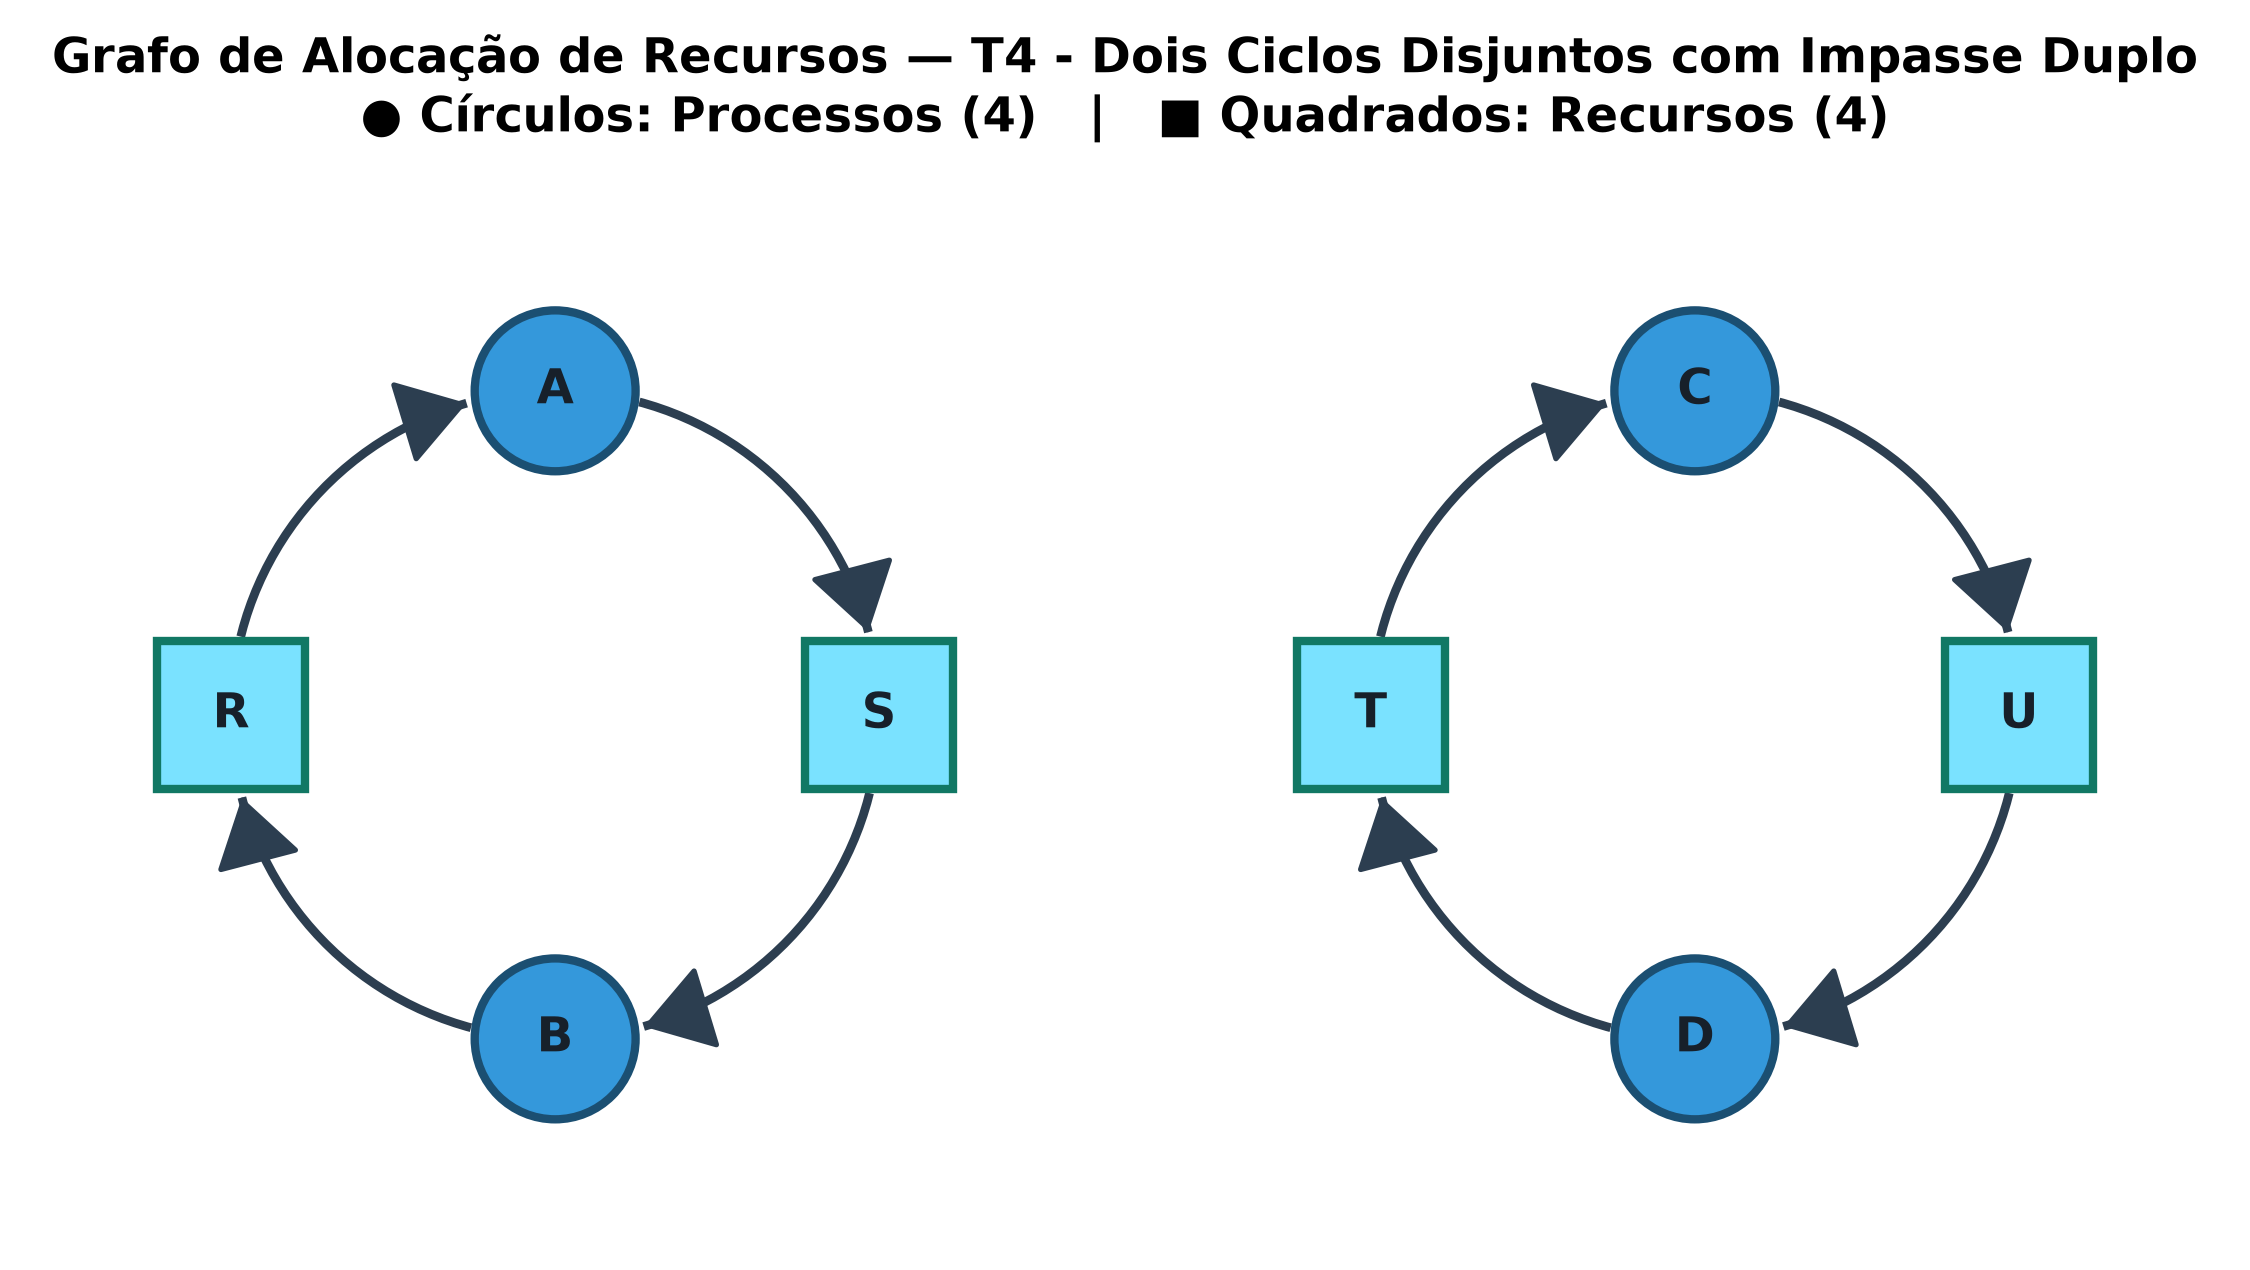

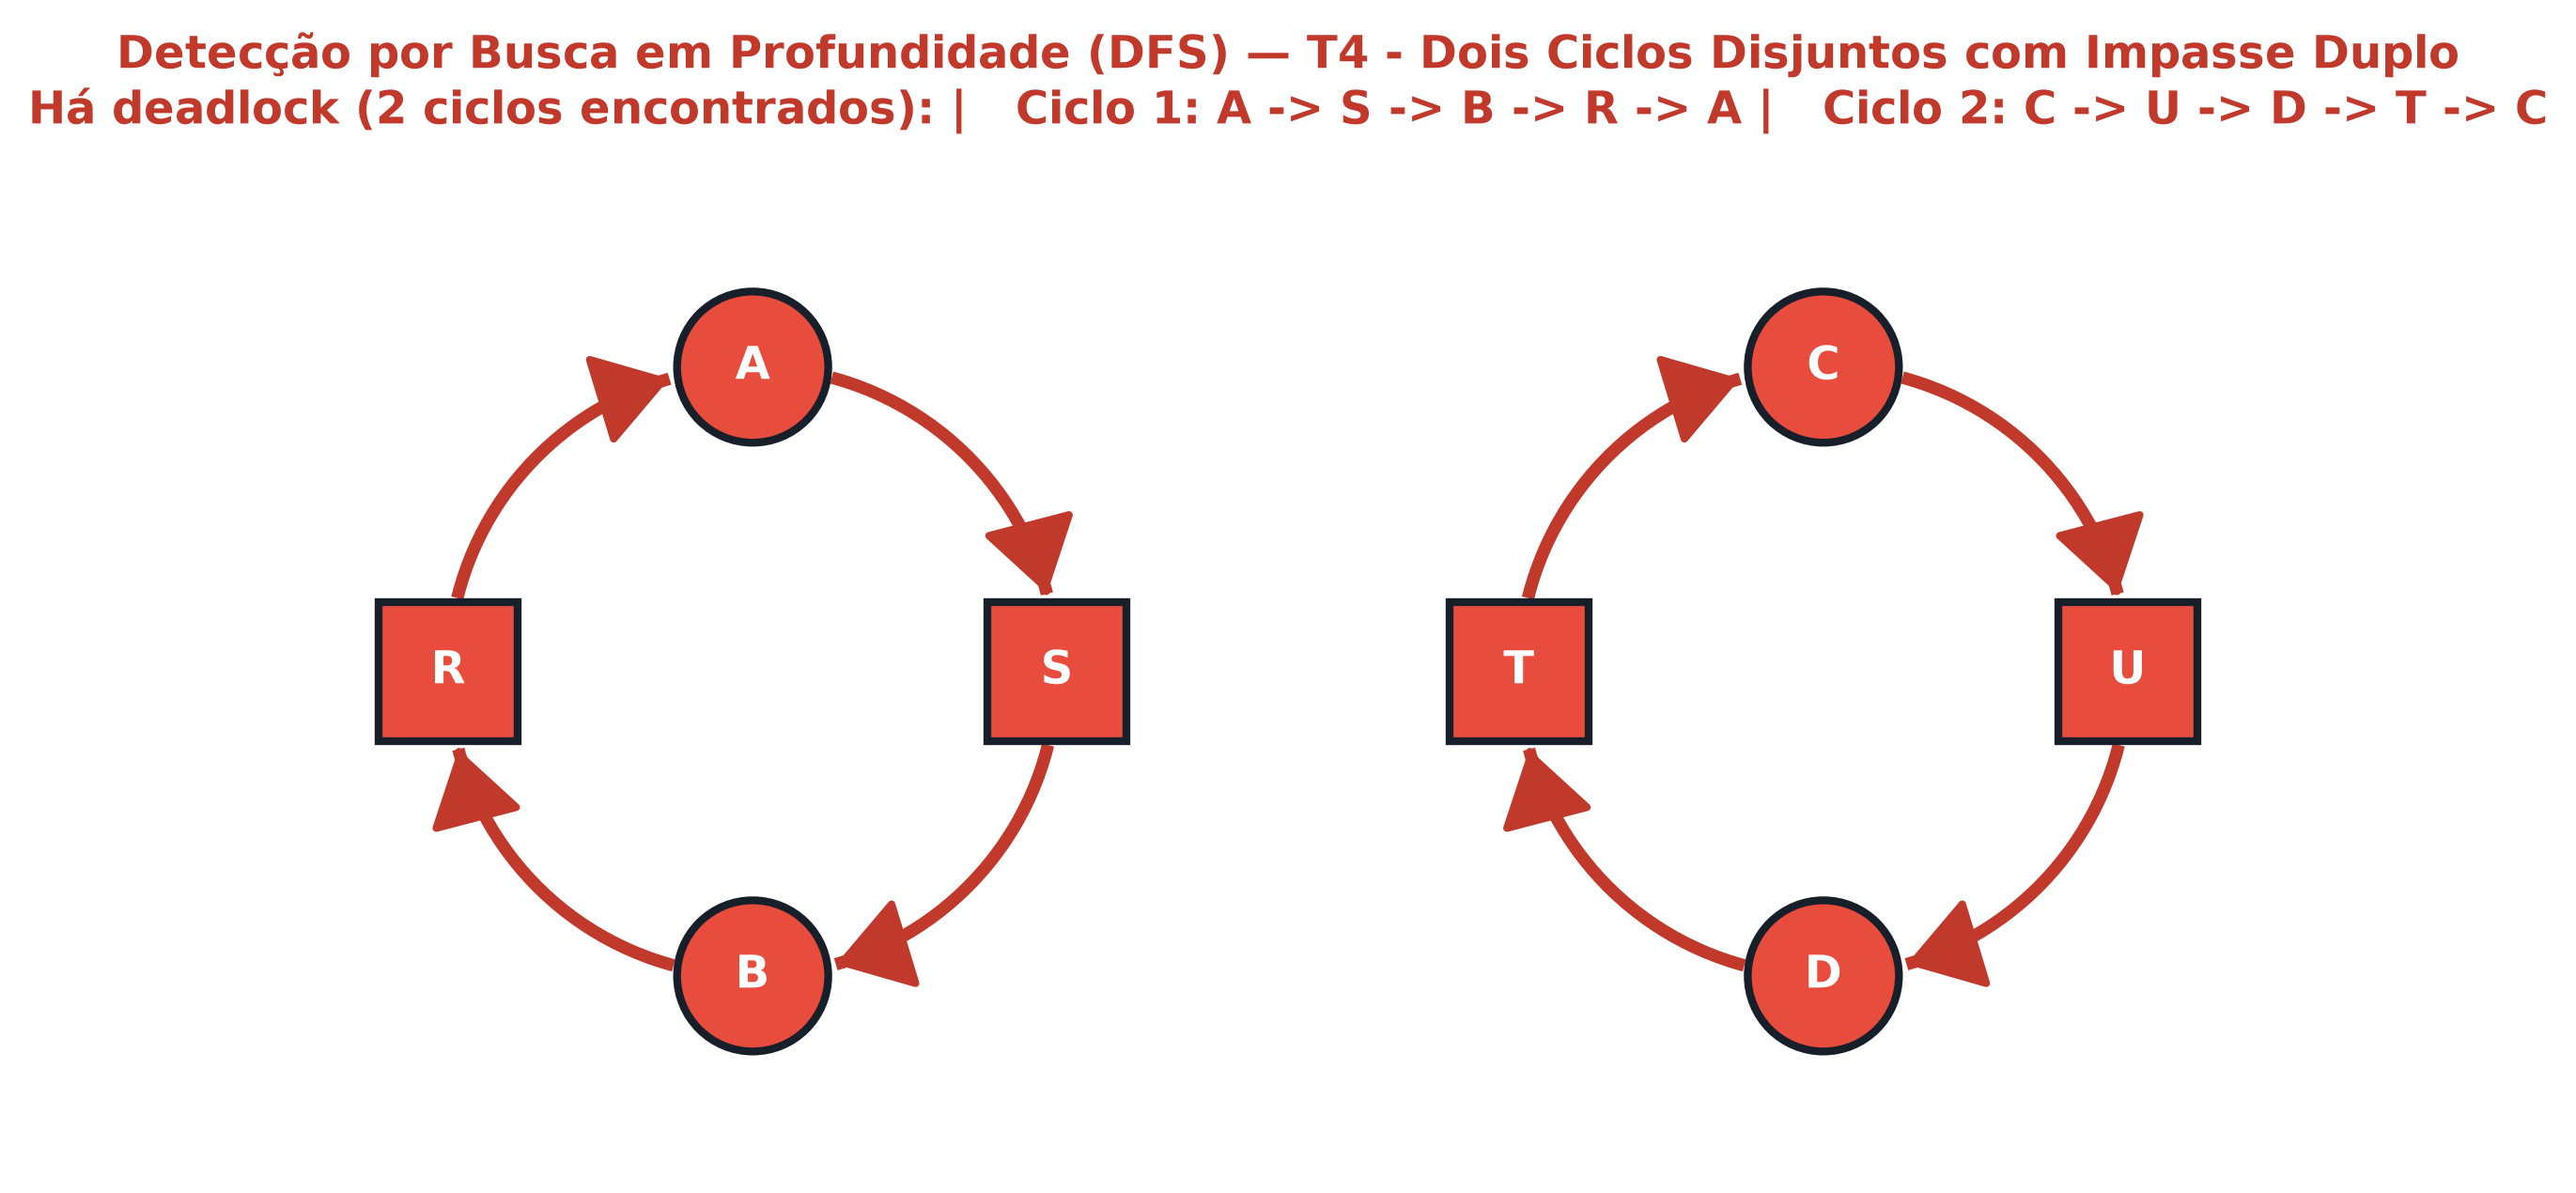


=== T5 - Ciclo com Processo em Espera Fora do Impasse ===
Resultado Oficial: Há deadlock (A -> S -> B -> T -> C -> R -> A)
[Imagens salvas em:]
  - output/figures/T5_ciclo_com_processo_em_espera_fora_do_impasse_cartao.png
  - output/figures/T5_ciclo_com_processo_em_espera_fora_do_impasse_grafo_alocacao.png
  - output/figures/T5_ciclo_com_processo_em_espera_fora_do_impasse_grafo_deteccao_dfs.png


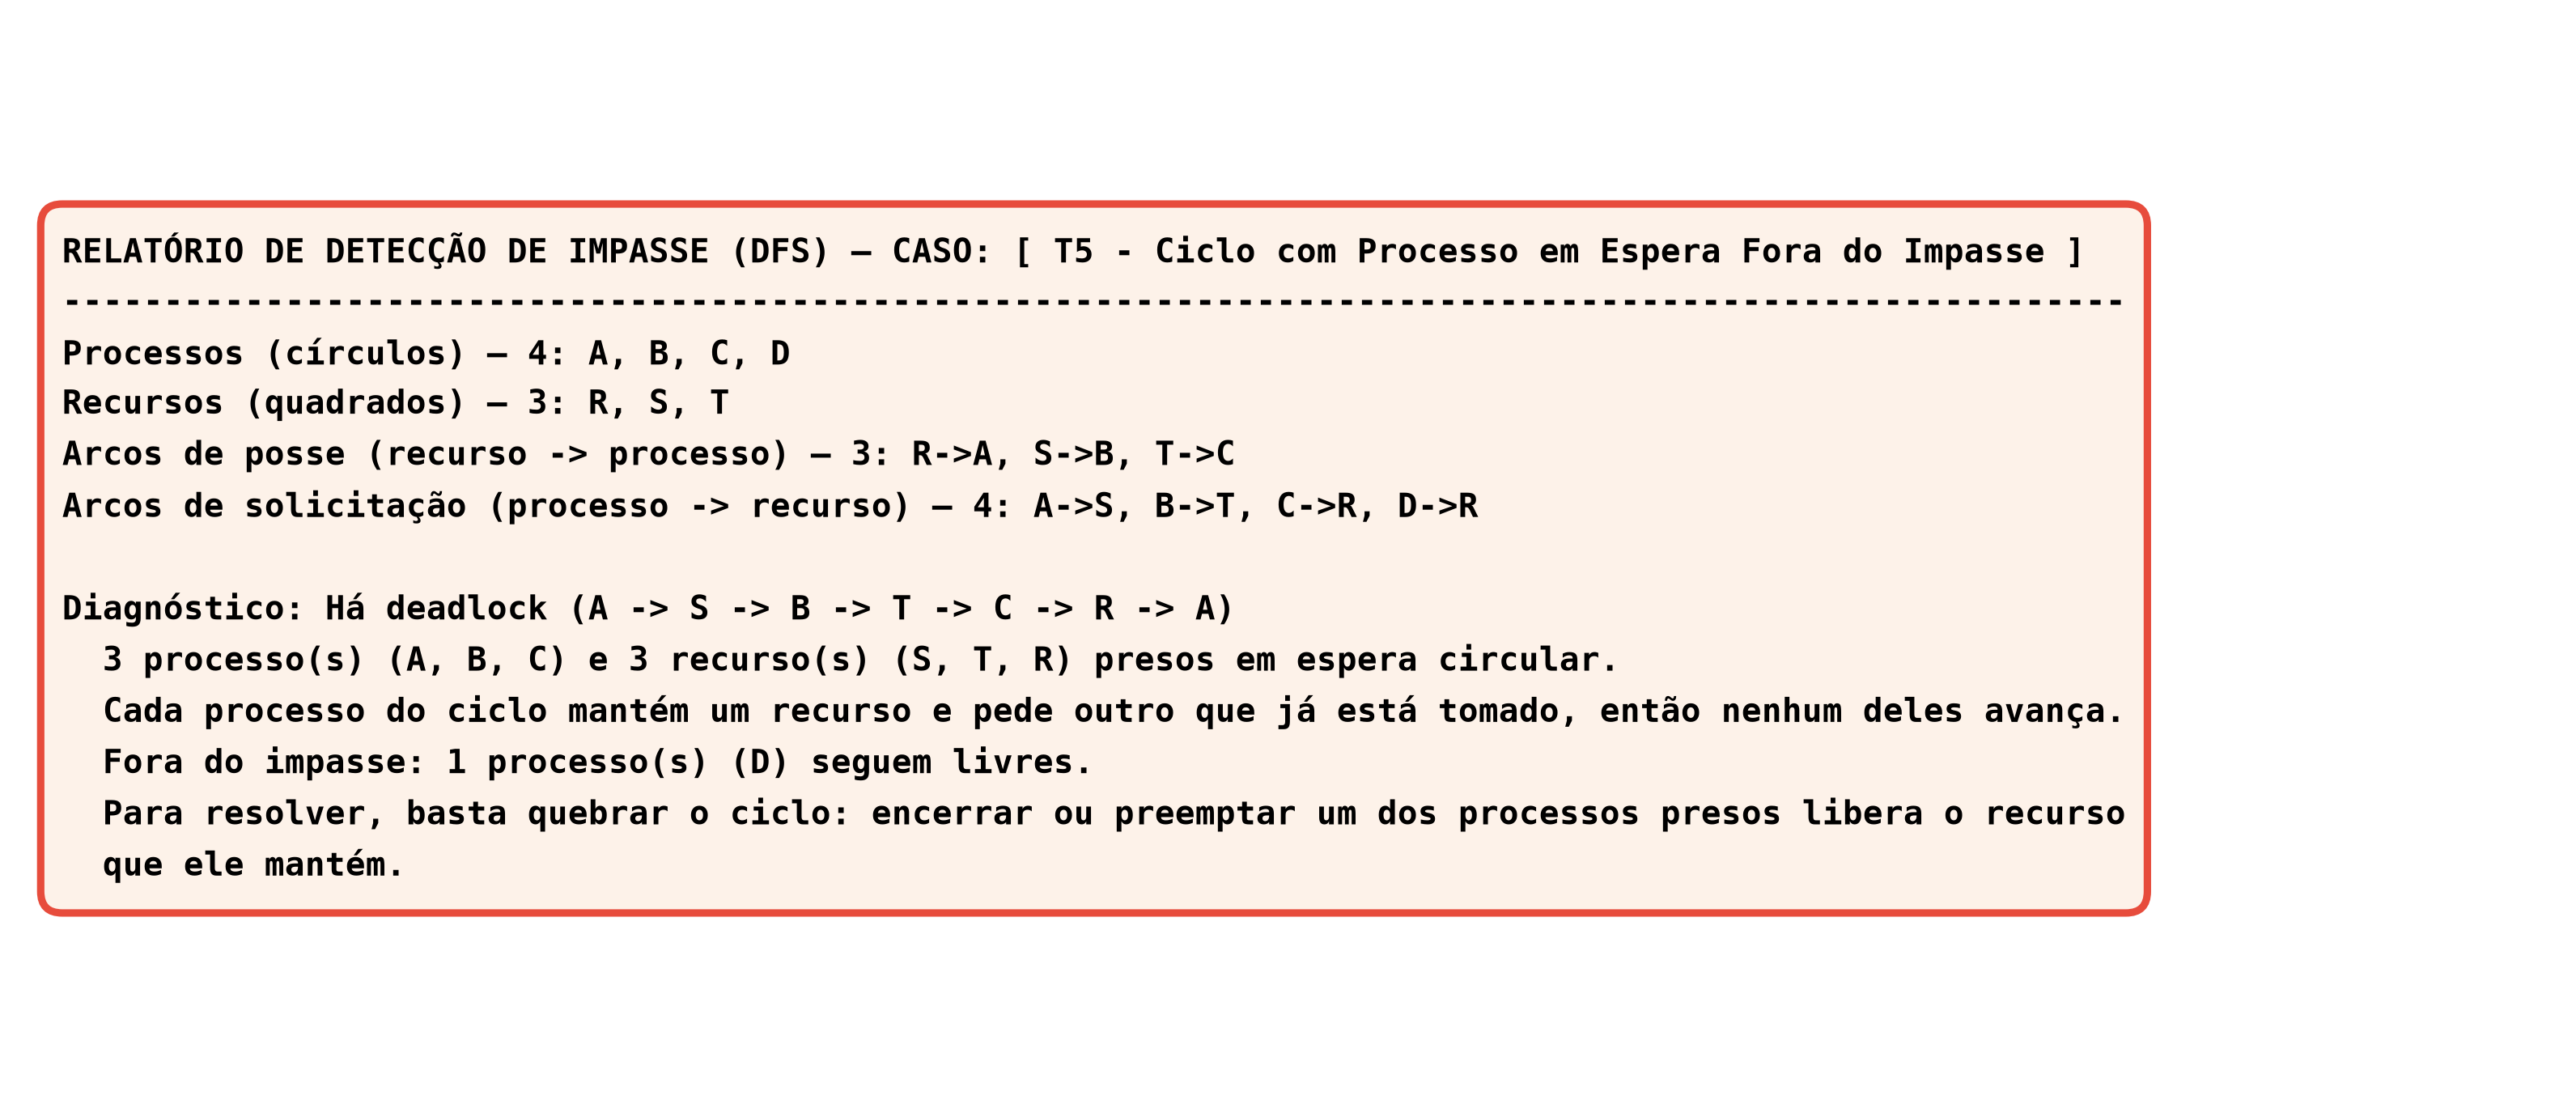

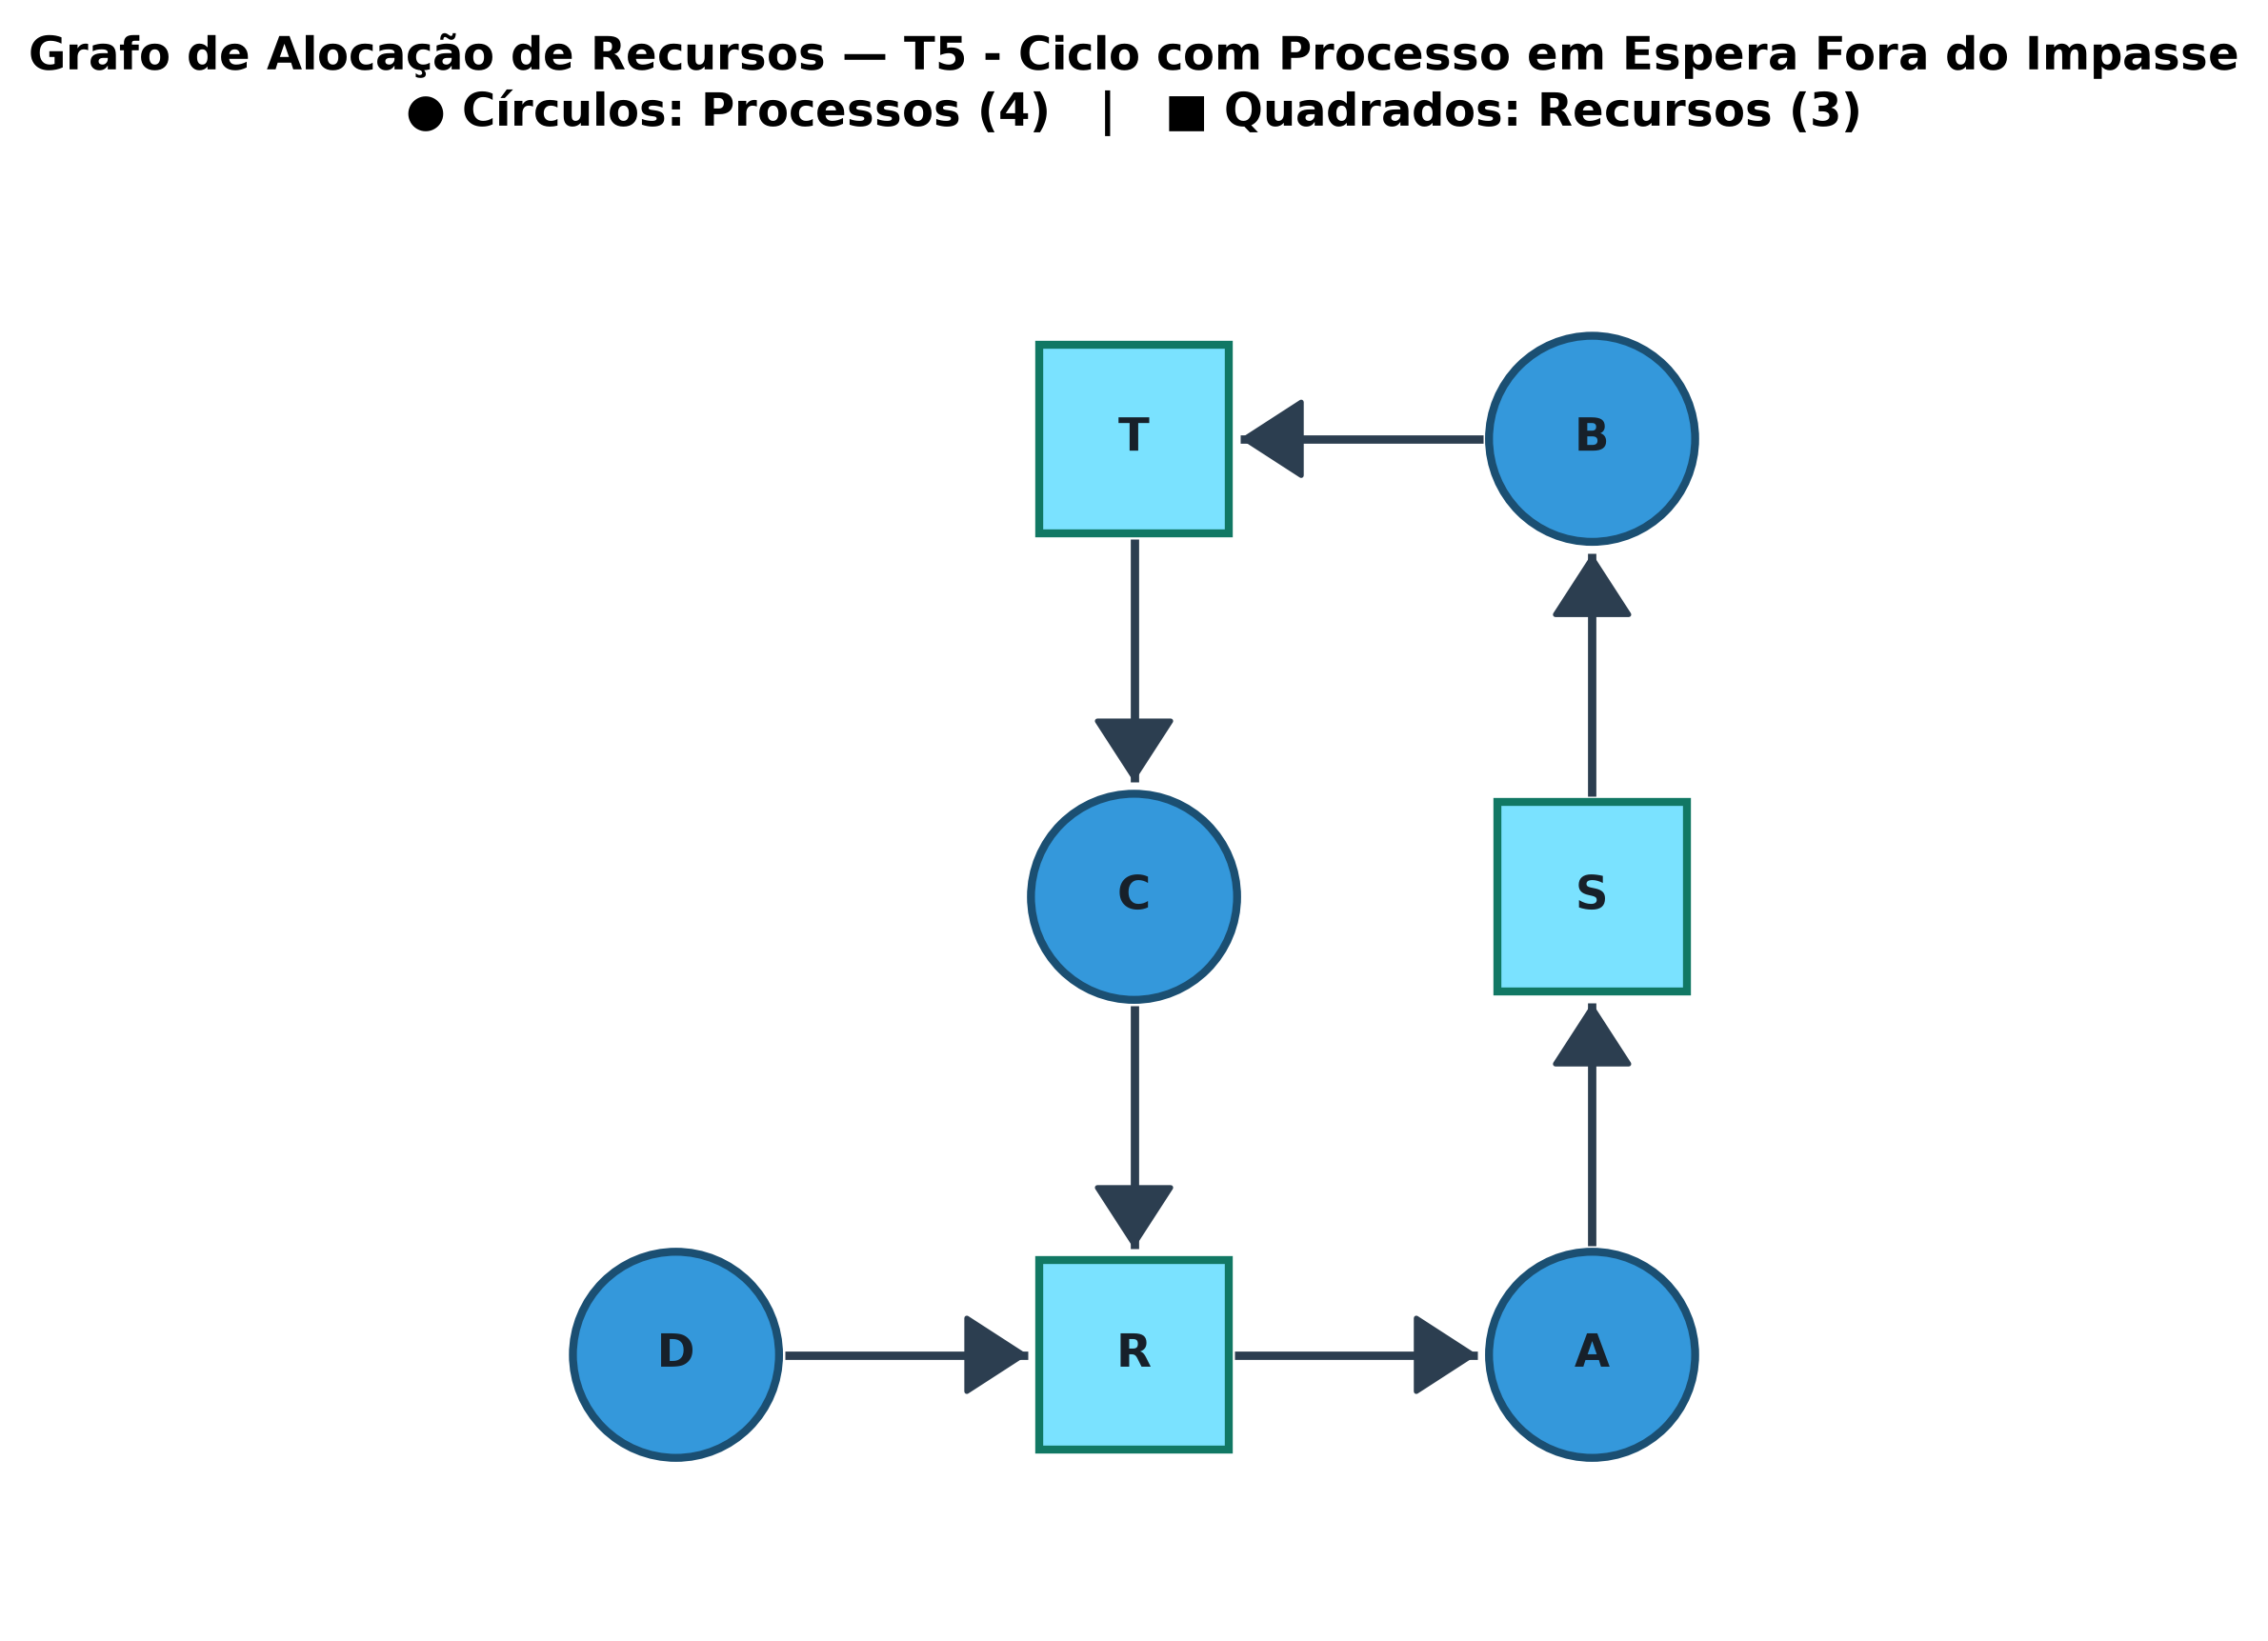

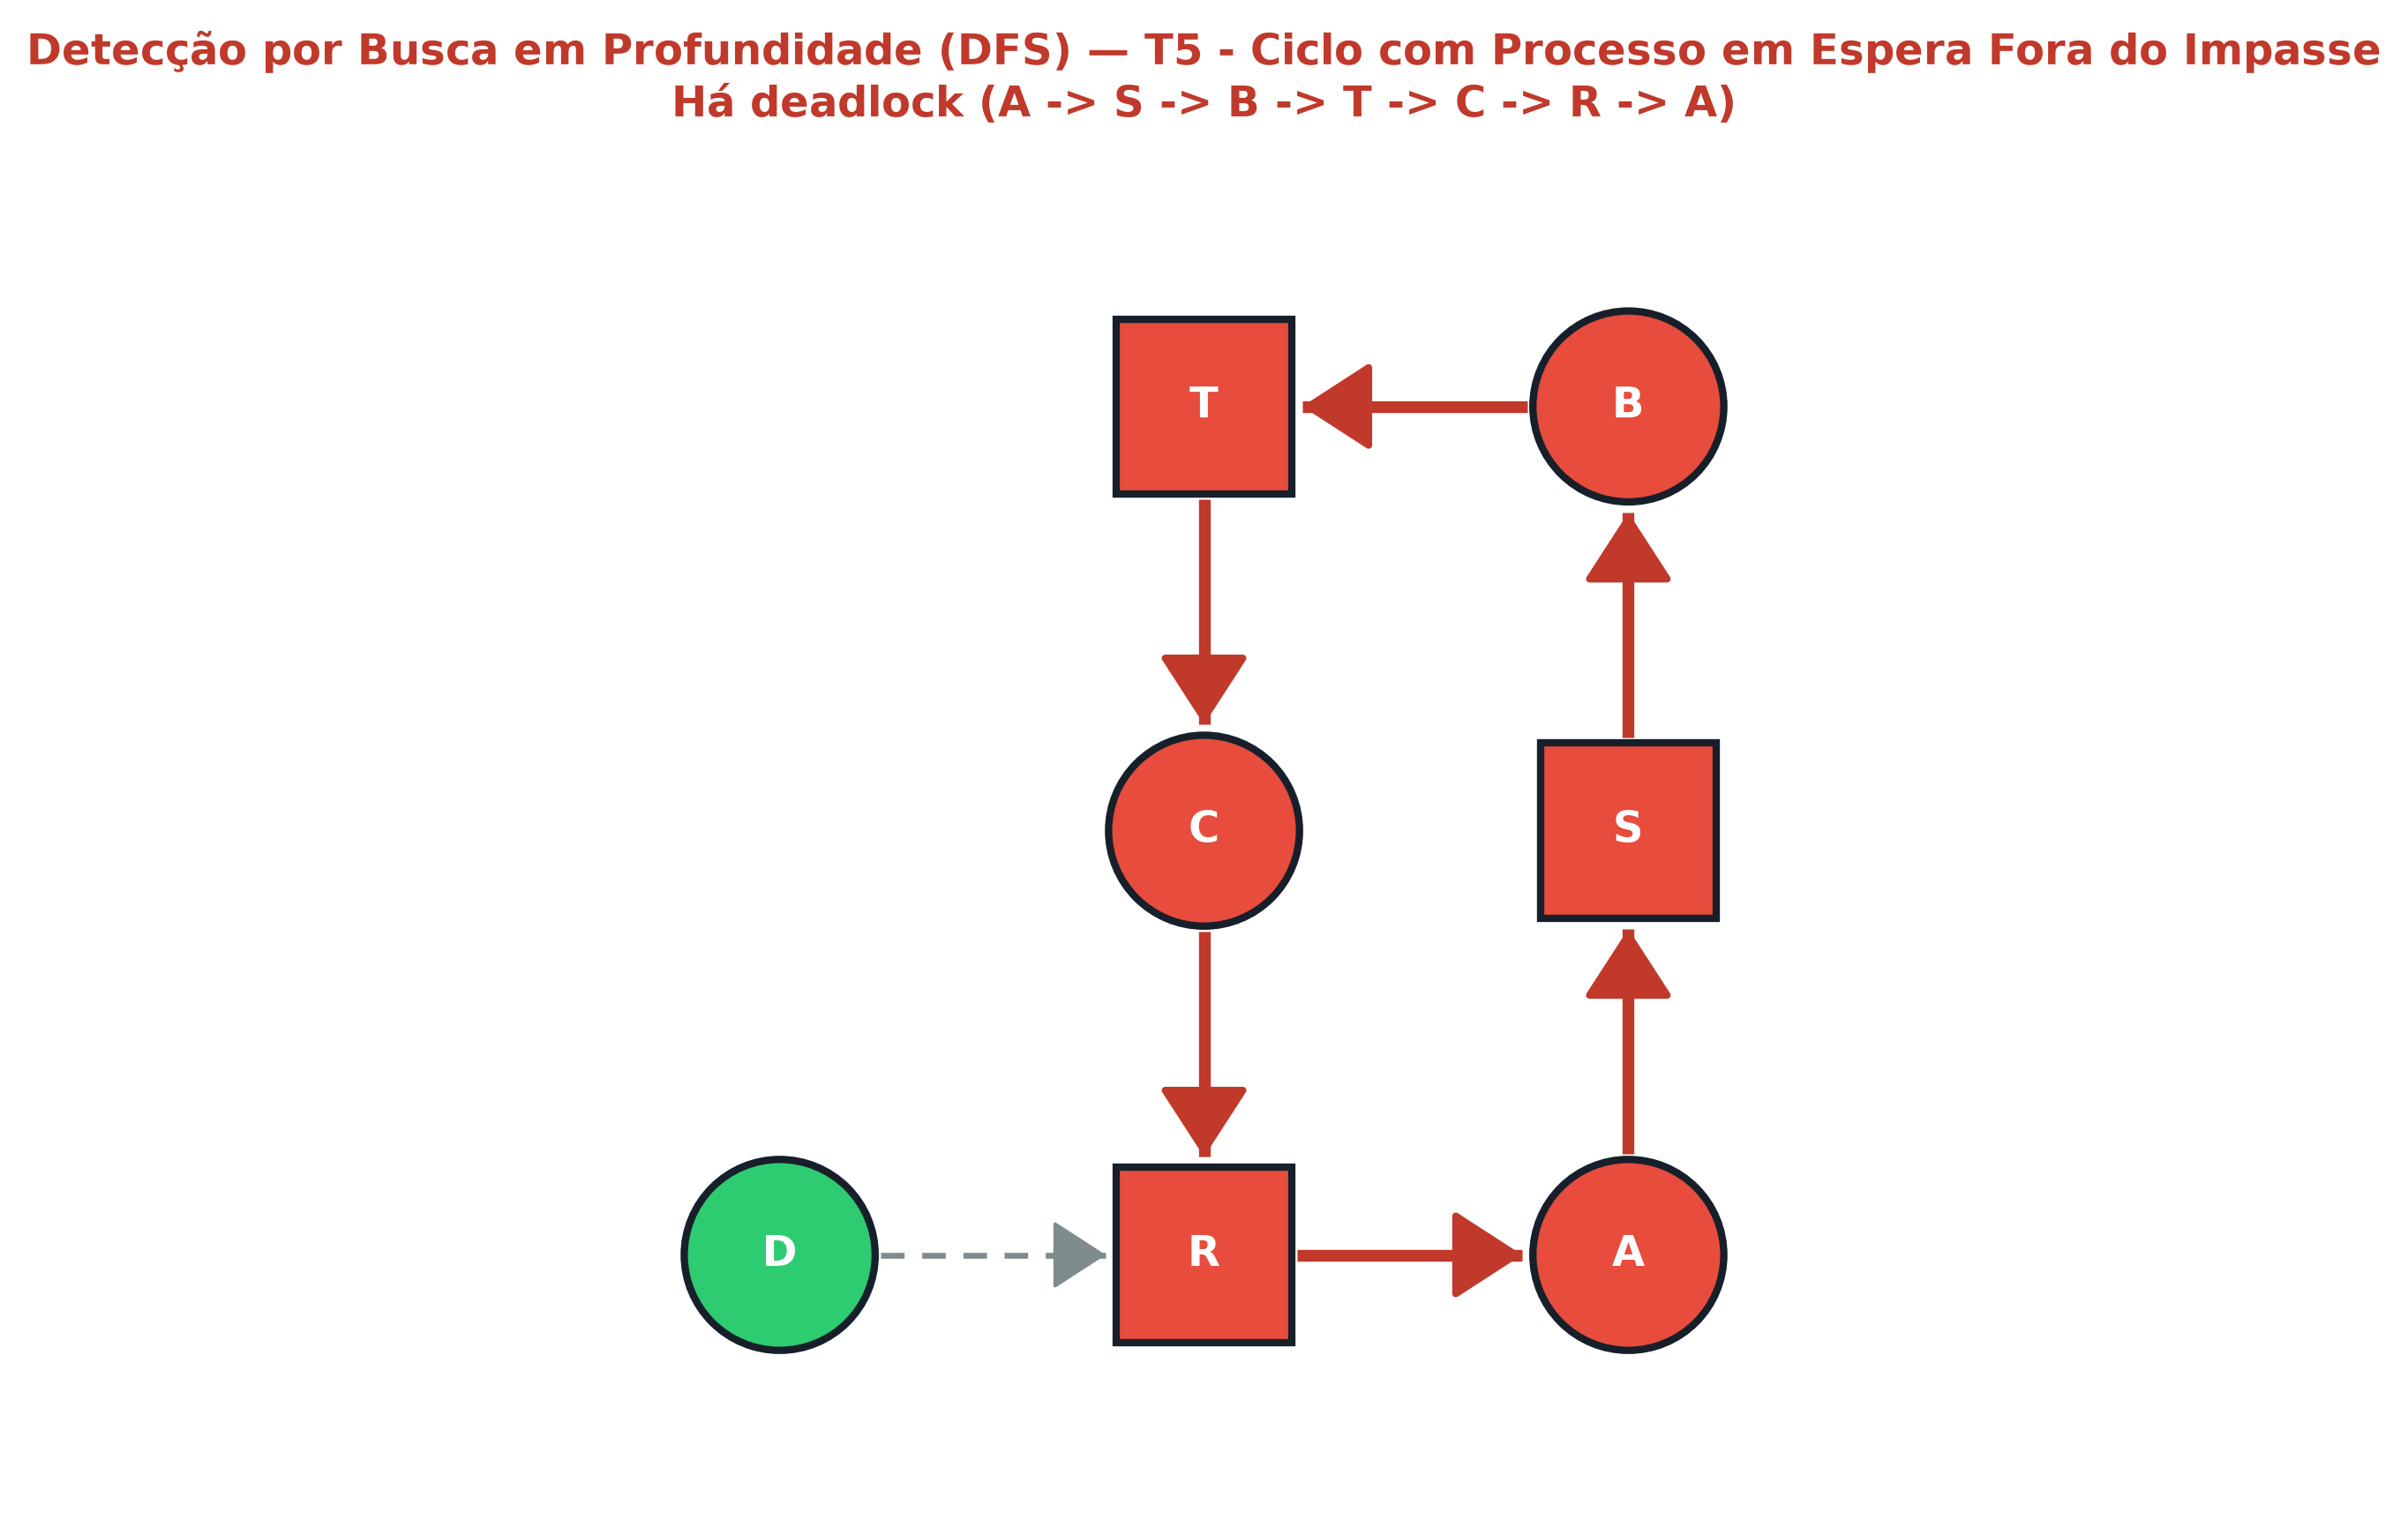


=== T6 - Cadeia Longa de Espera sem Deadlock ===
Resultado Oficial: Sem deadlock
[Imagens salvas em:]
  - output/figures/T6_cadeia_longa_de_espera_sem_deadlock_cartao.png
  - output/figures/T6_cadeia_longa_de_espera_sem_deadlock_grafo_alocacao.png
  - output/figures/T6_cadeia_longa_de_espera_sem_deadlock_grafo_deteccao_dfs.png


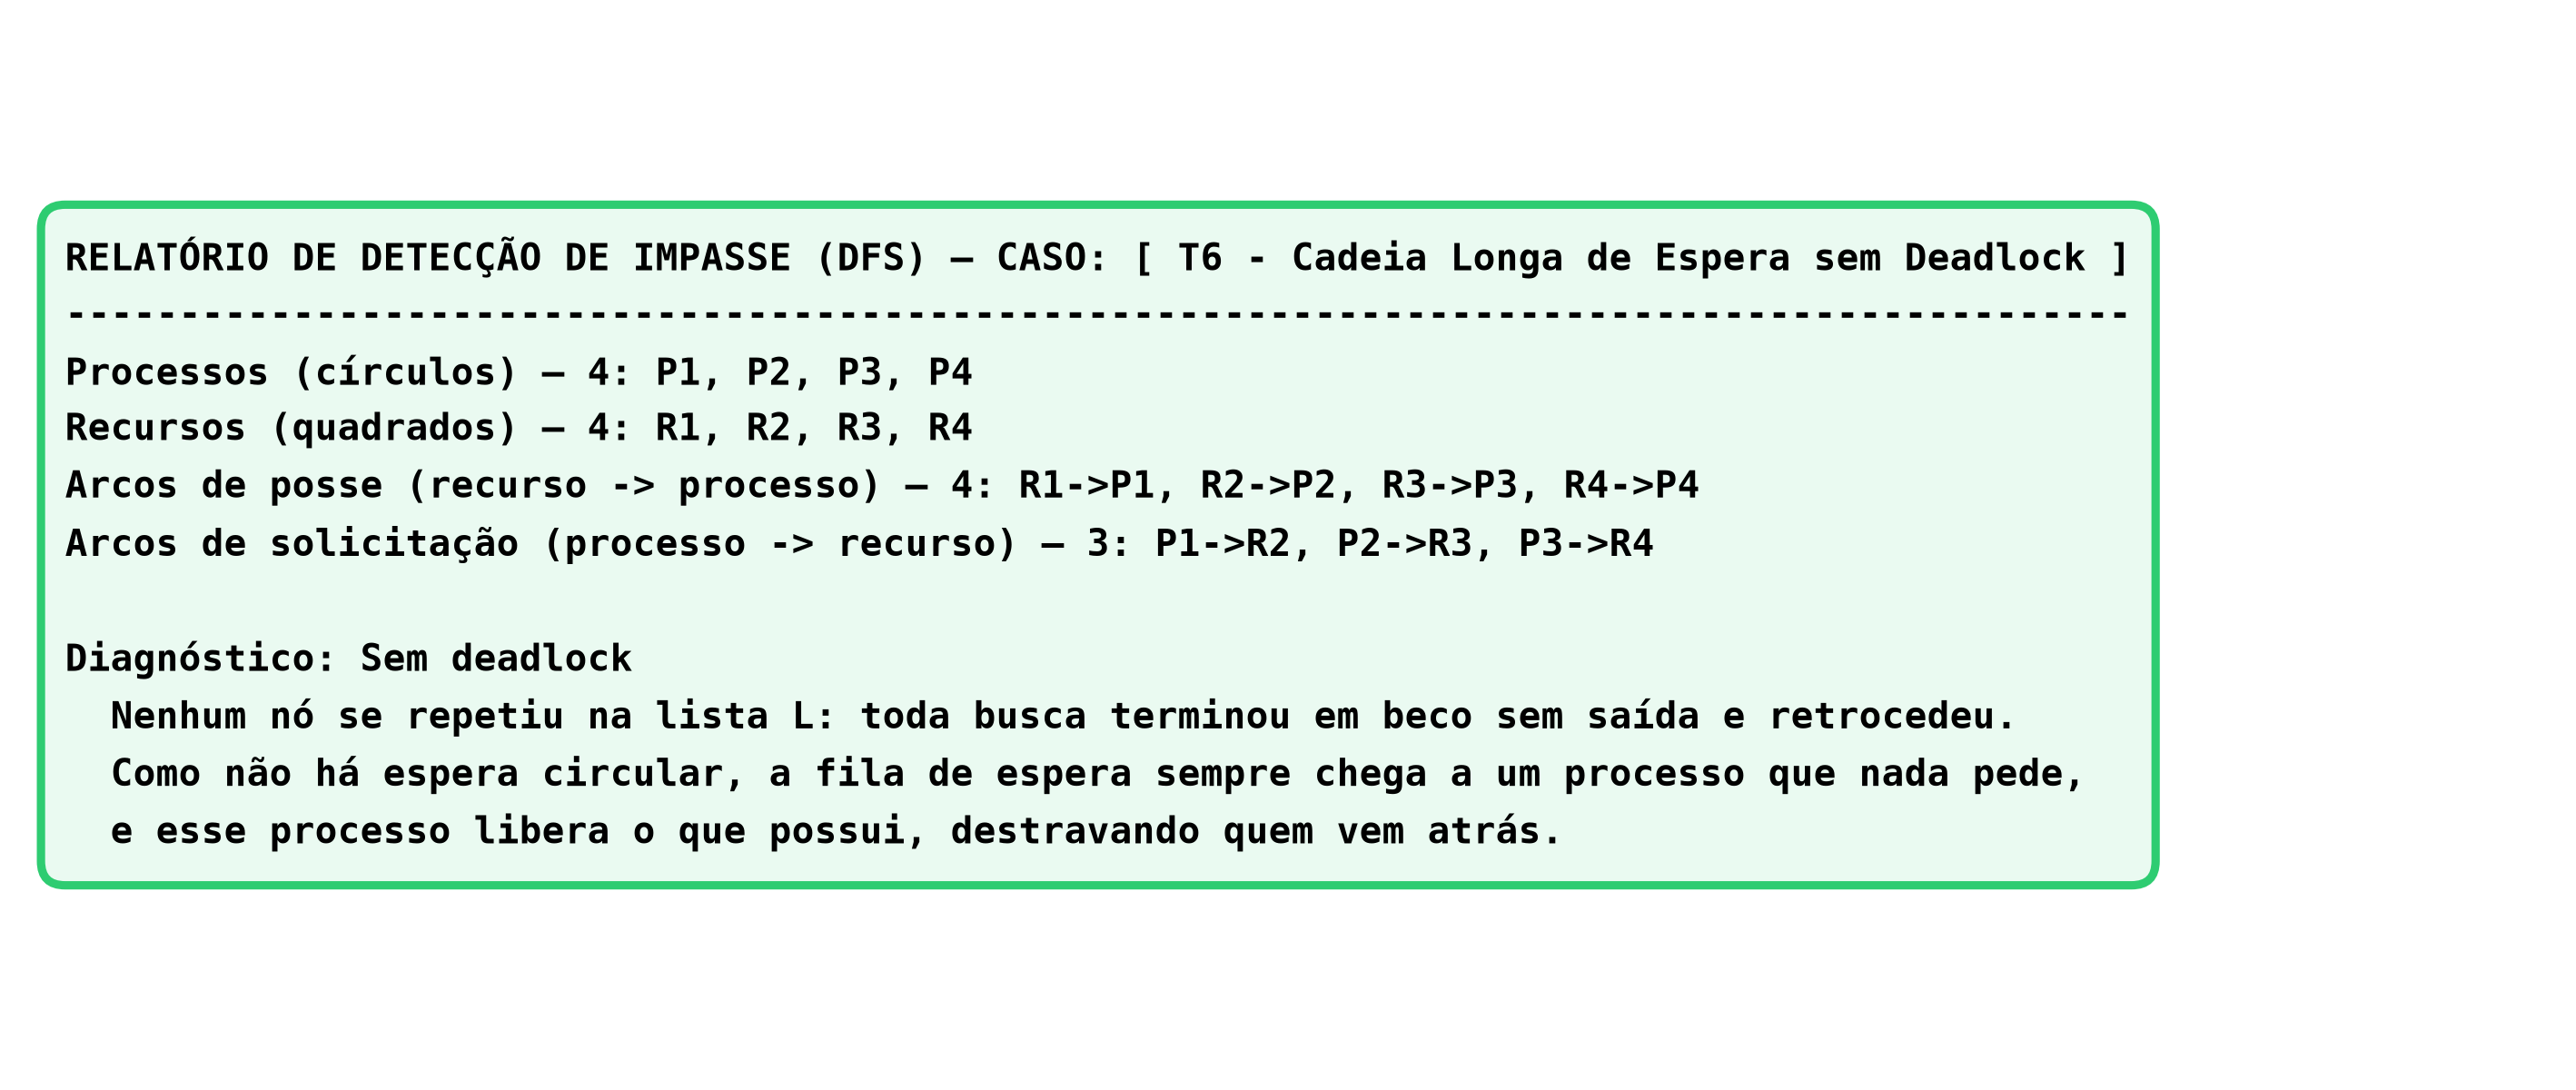

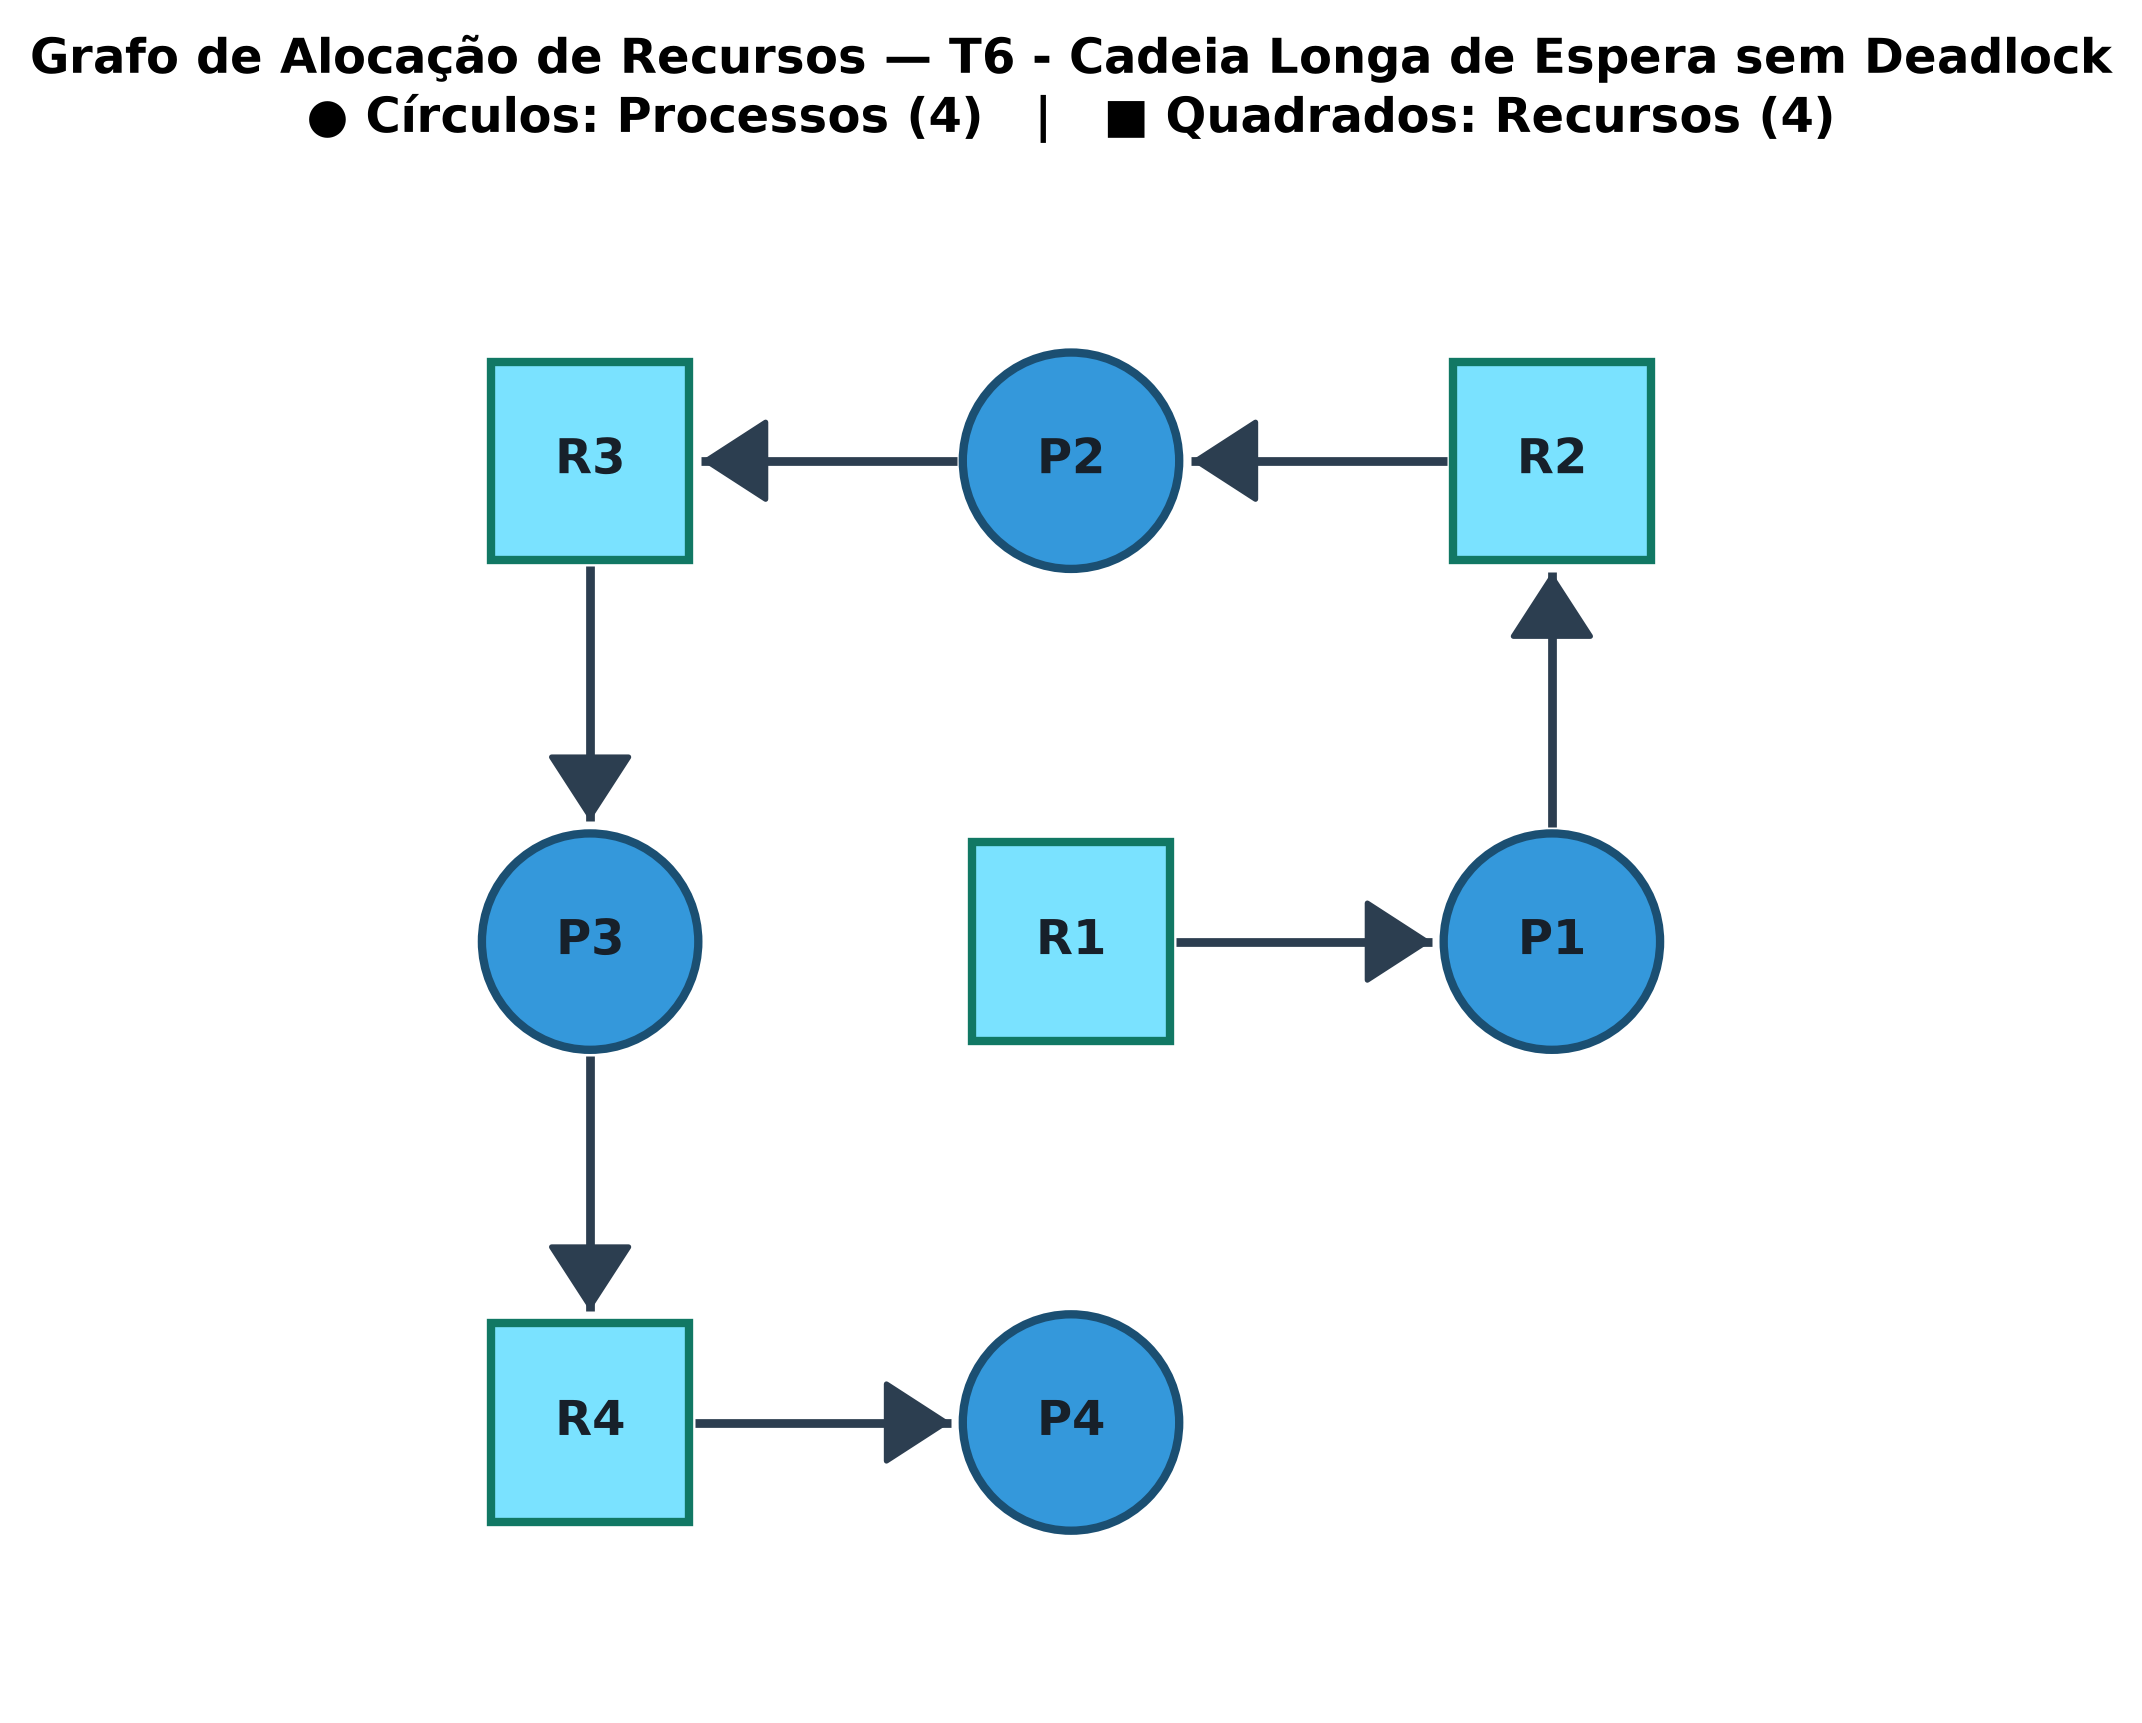

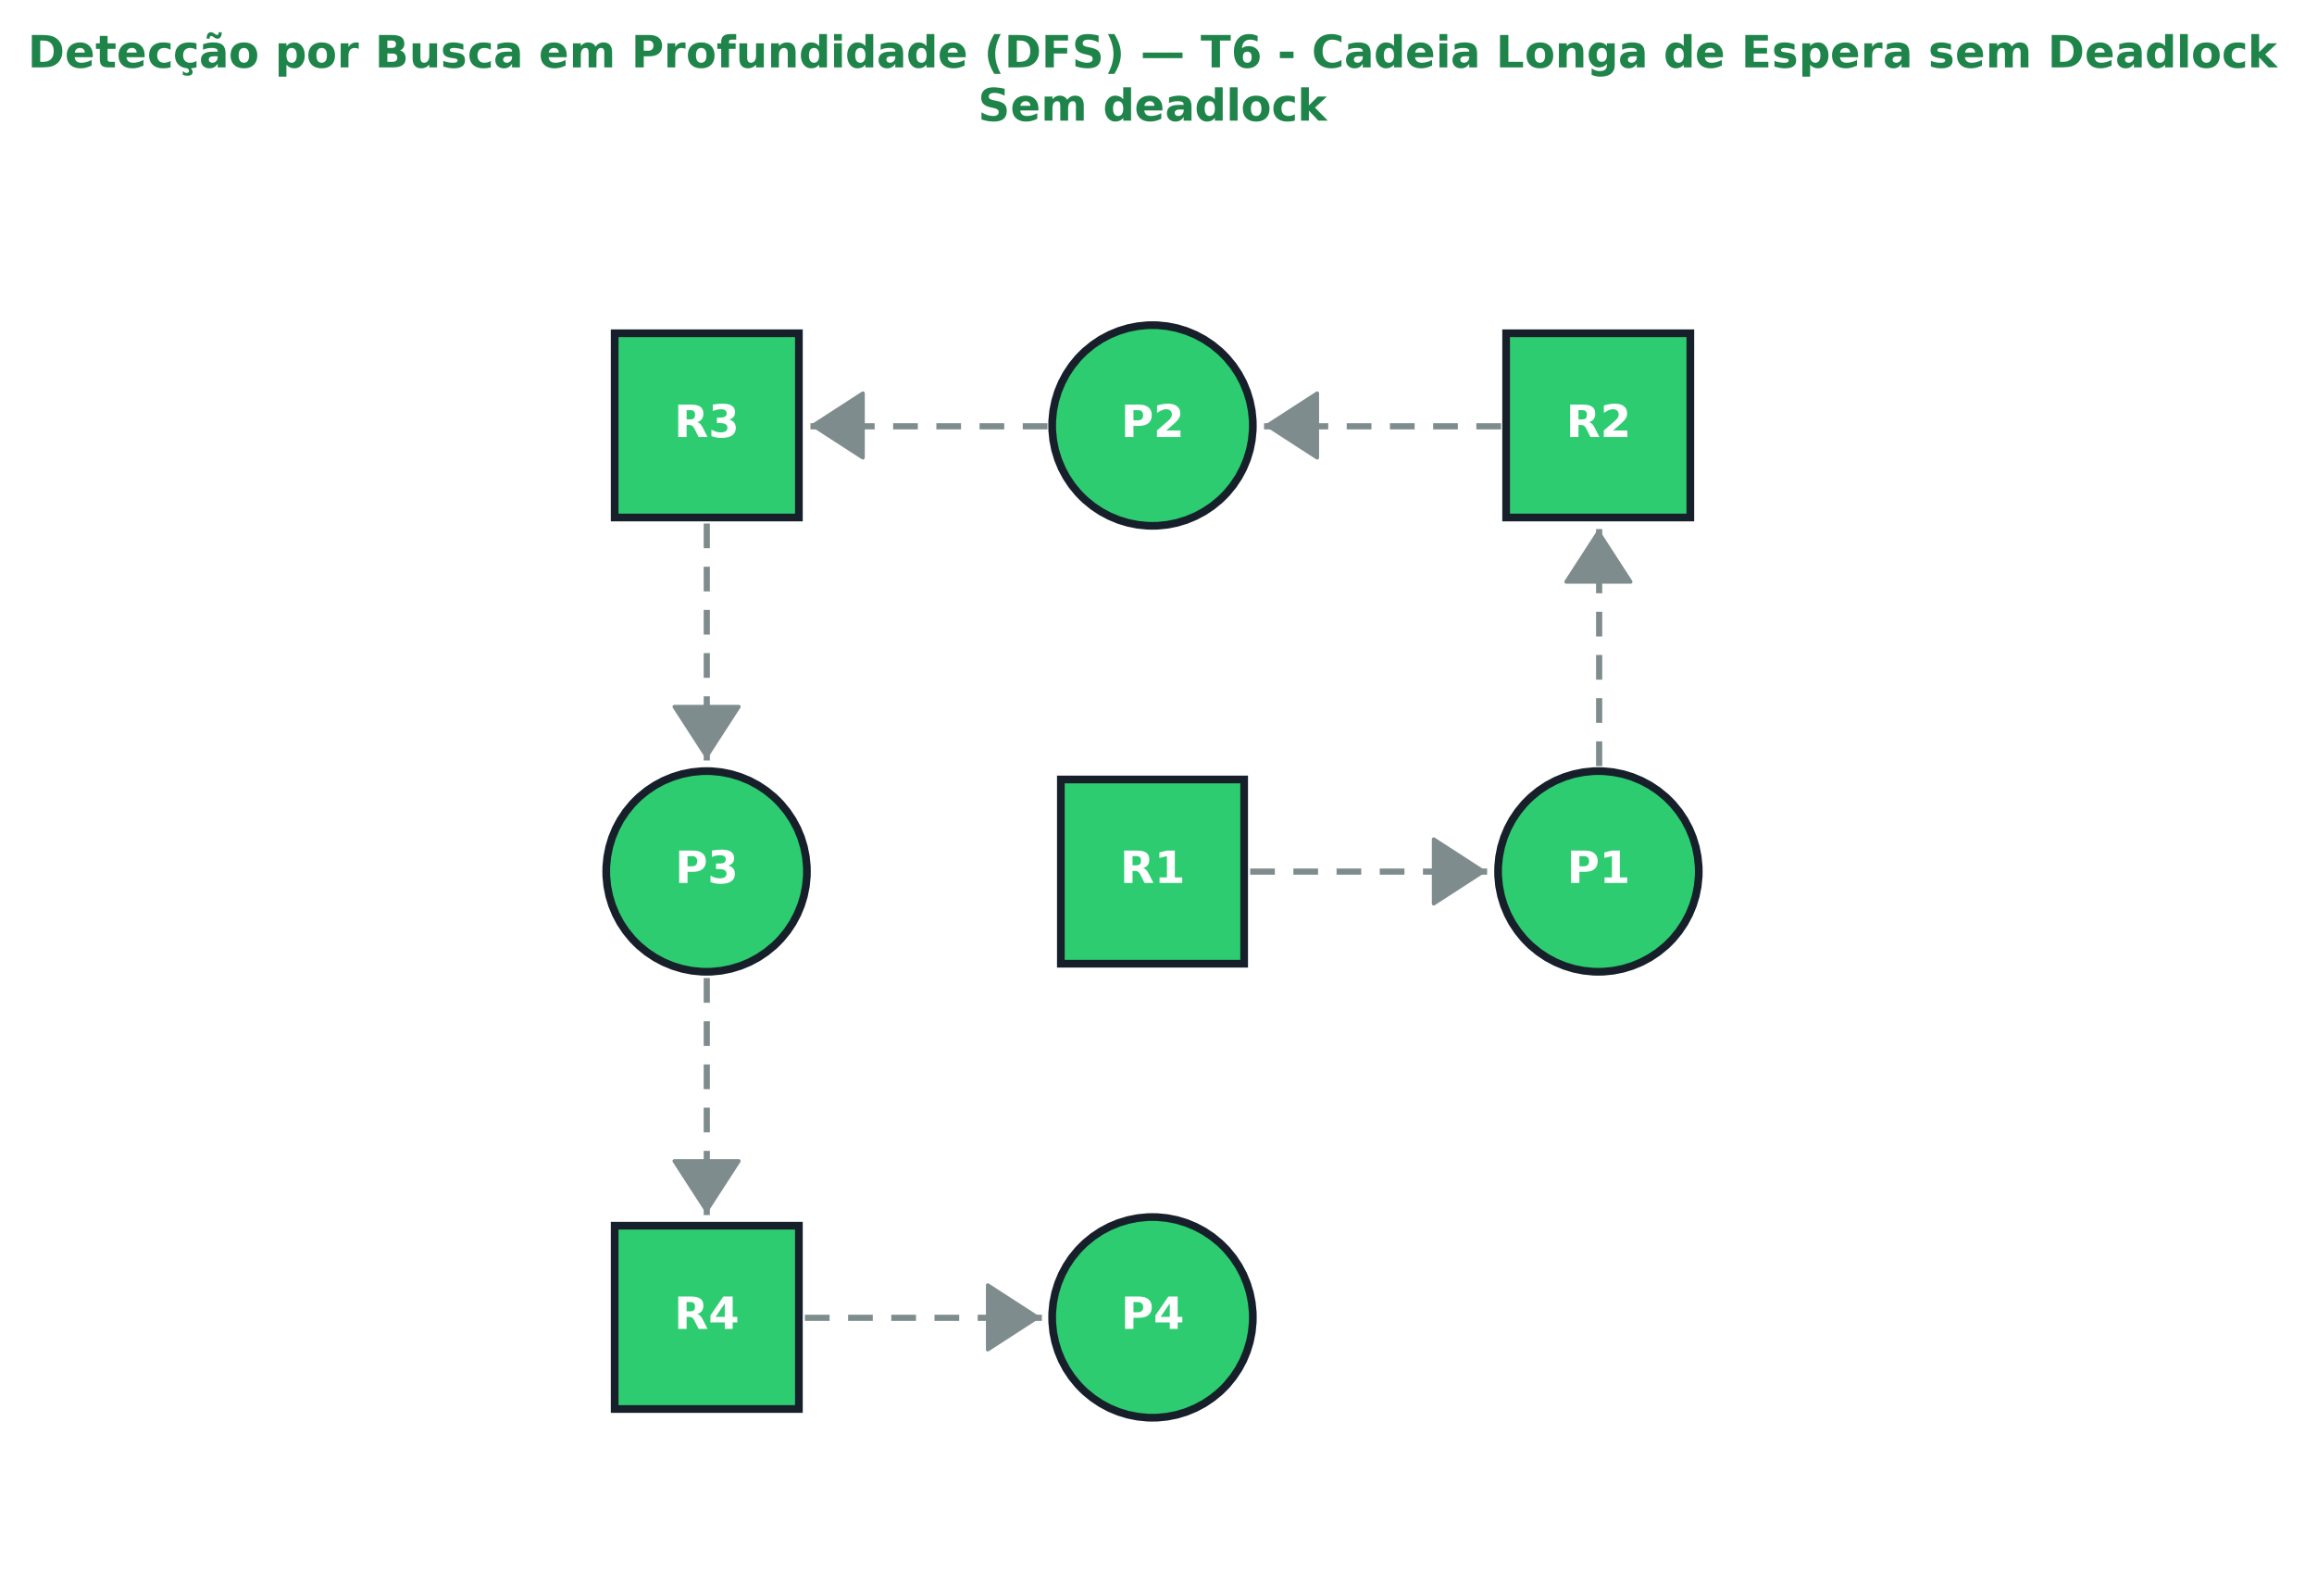


=== T7 - Dois Impasses Simultâneos com Ramo Livre ===
Resultado Oficial: Há deadlock (2 ciclos encontrados):
  Ciclo 1: P1 -> R2 -> P2 -> R1 -> P1
  Ciclo 2: P3 -> R4 -> P4 -> R3 -> P3
[Imagens salvas em:]
  - output/figures/T7_dois_impasses_simultaneos_com_ramo_livre_cartao.png
  - output/figures/T7_dois_impasses_simultaneos_com_ramo_livre_grafo_alocacao.png
  - output/figures/T7_dois_impasses_simultaneos_com_ramo_livre_grafo_deteccao_dfs.png


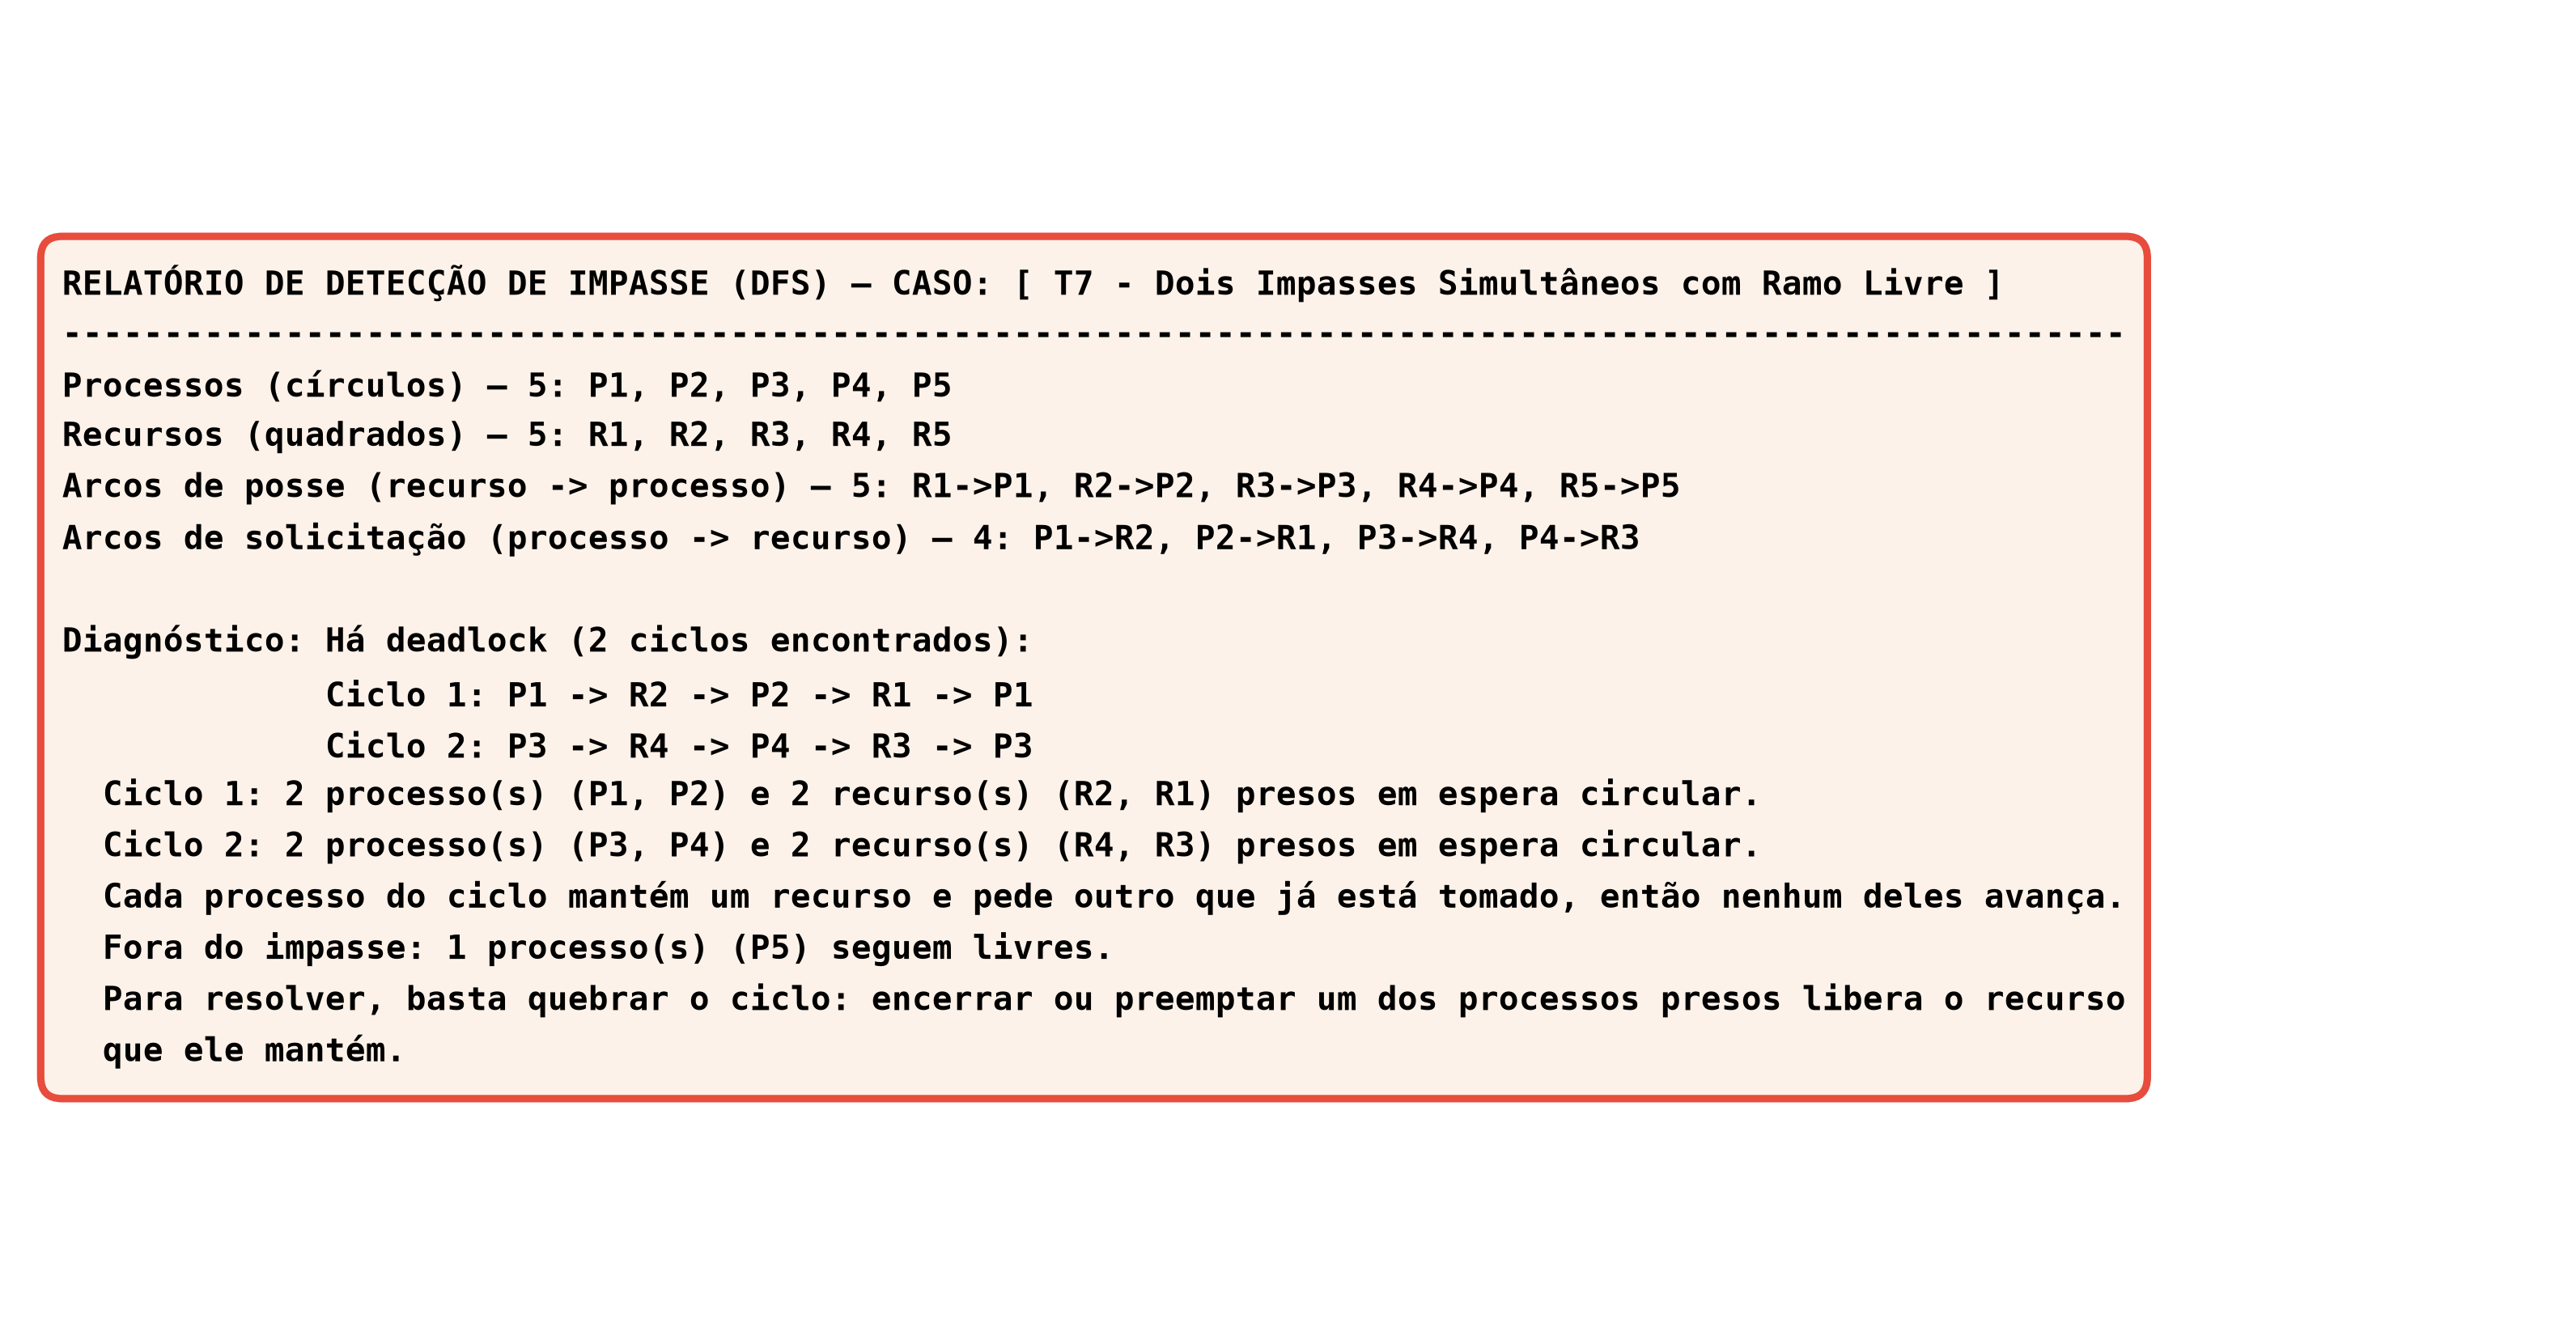

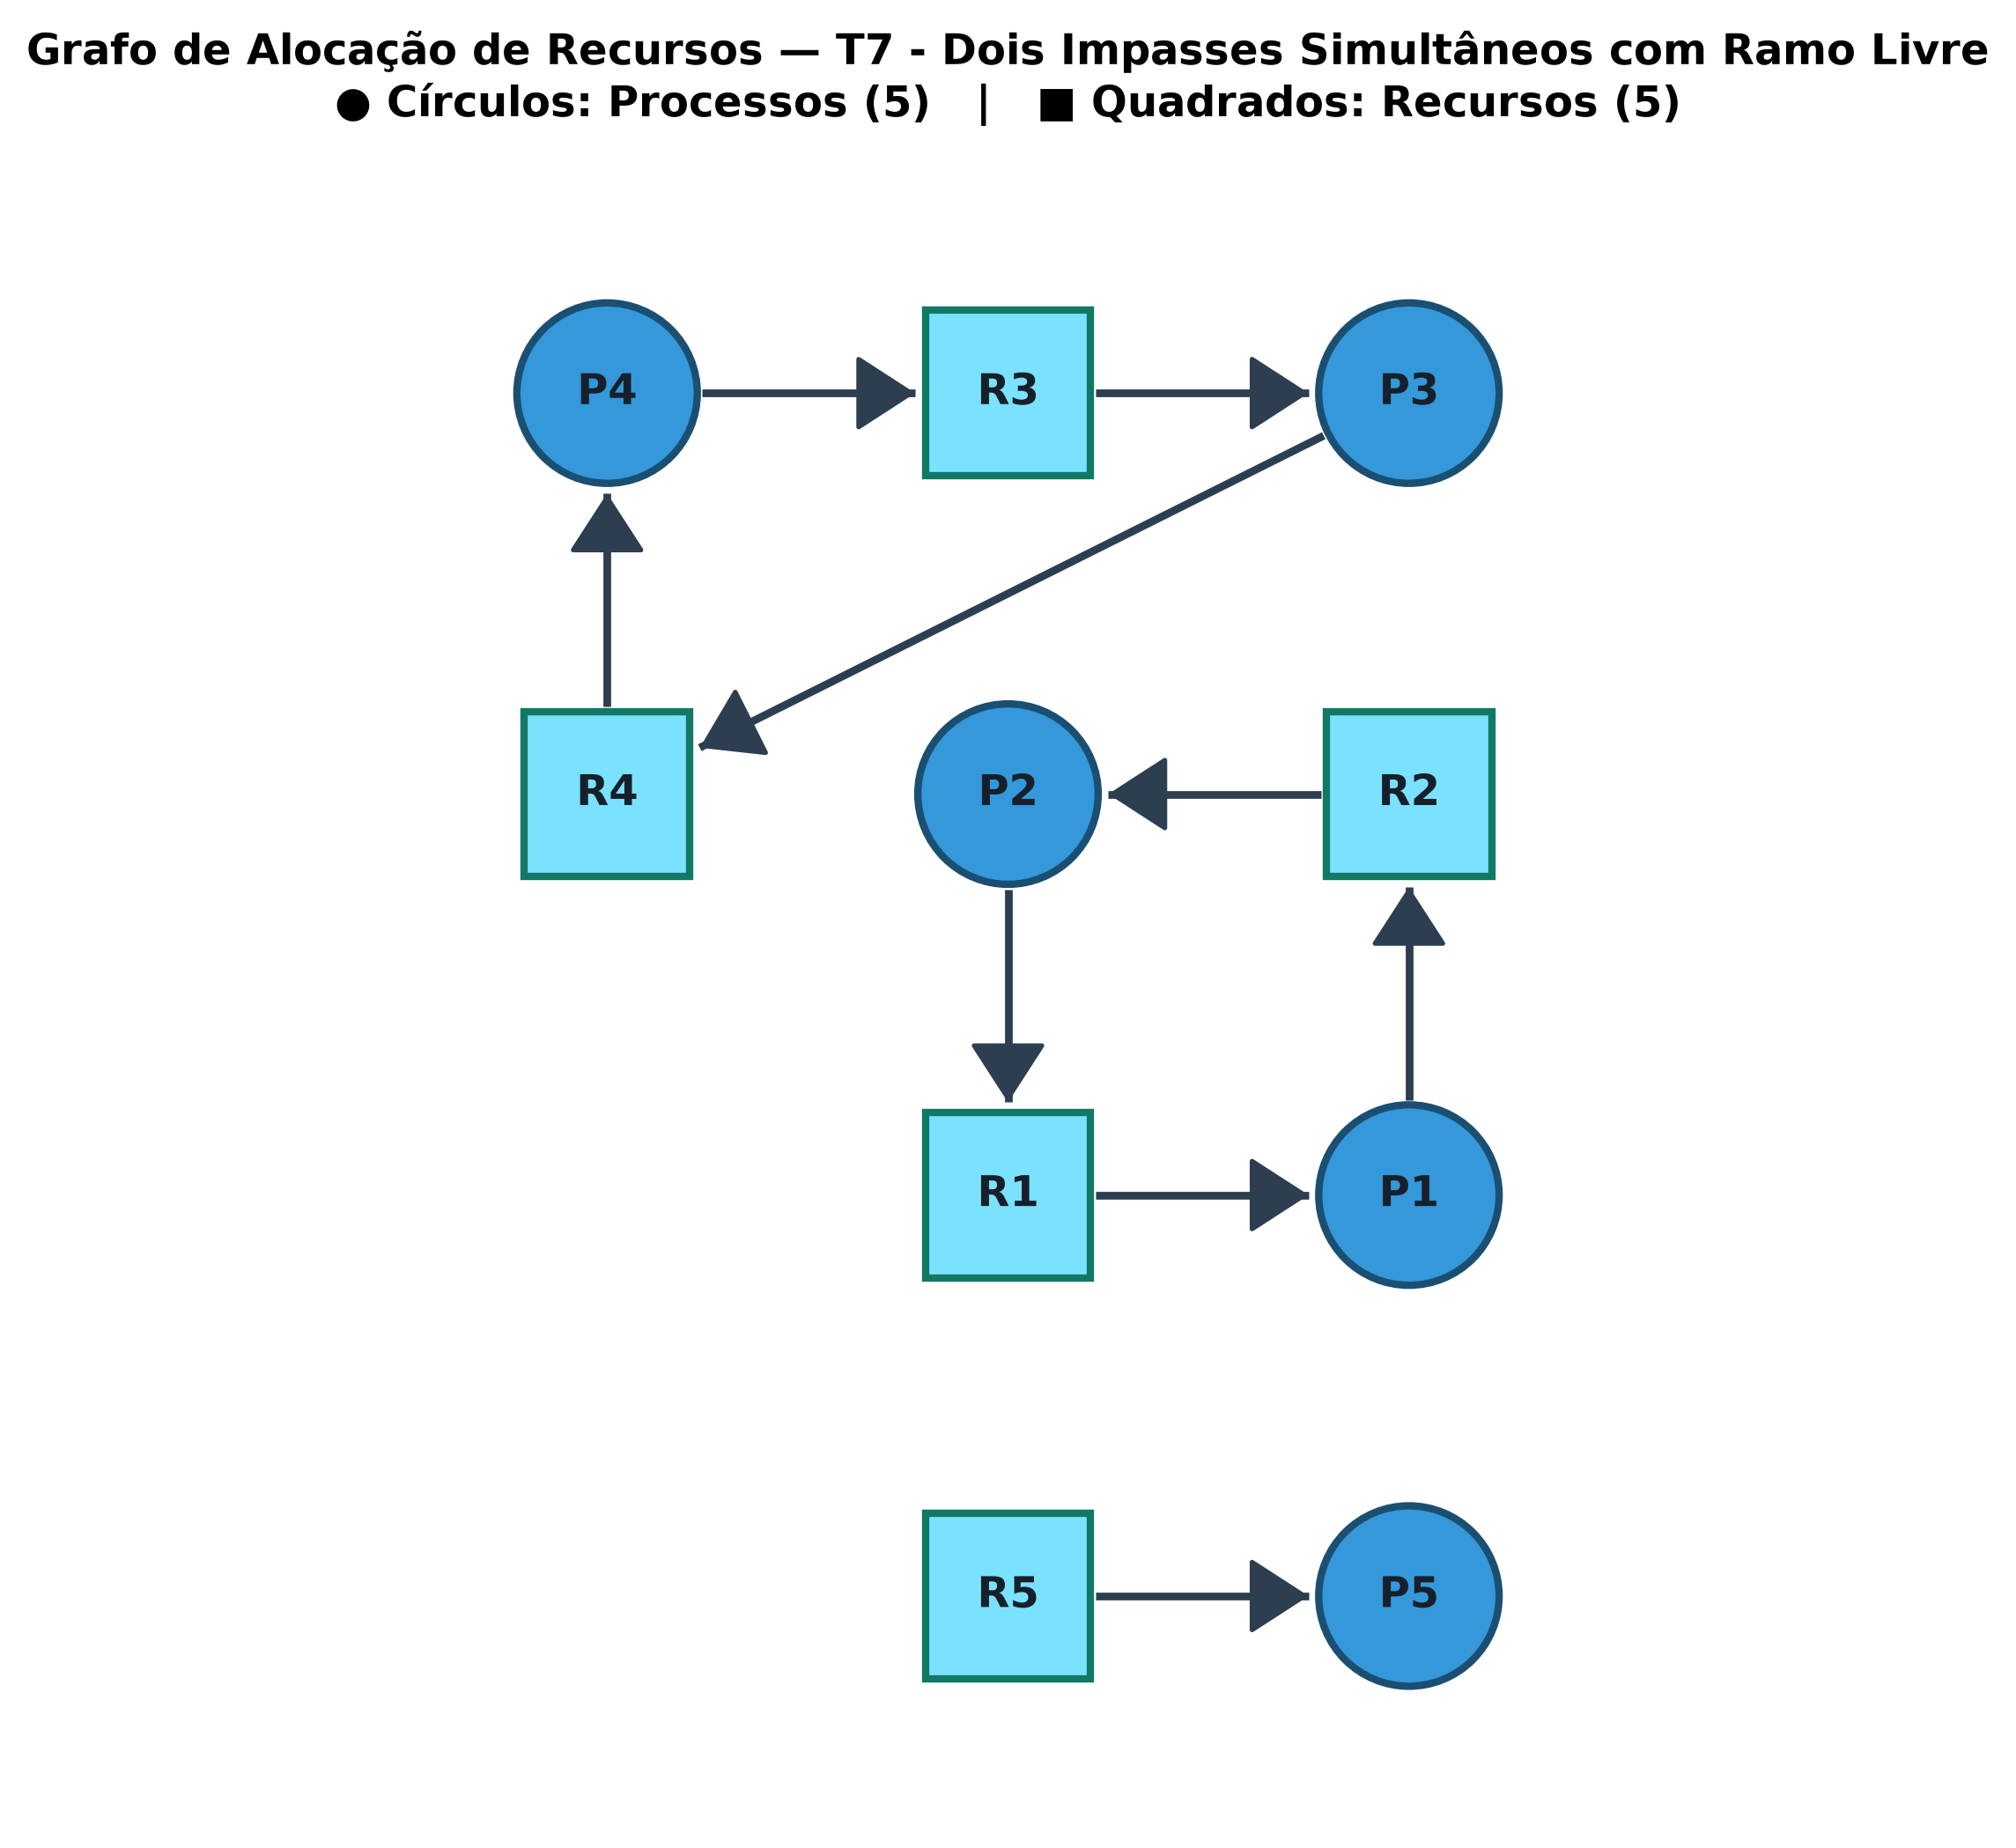

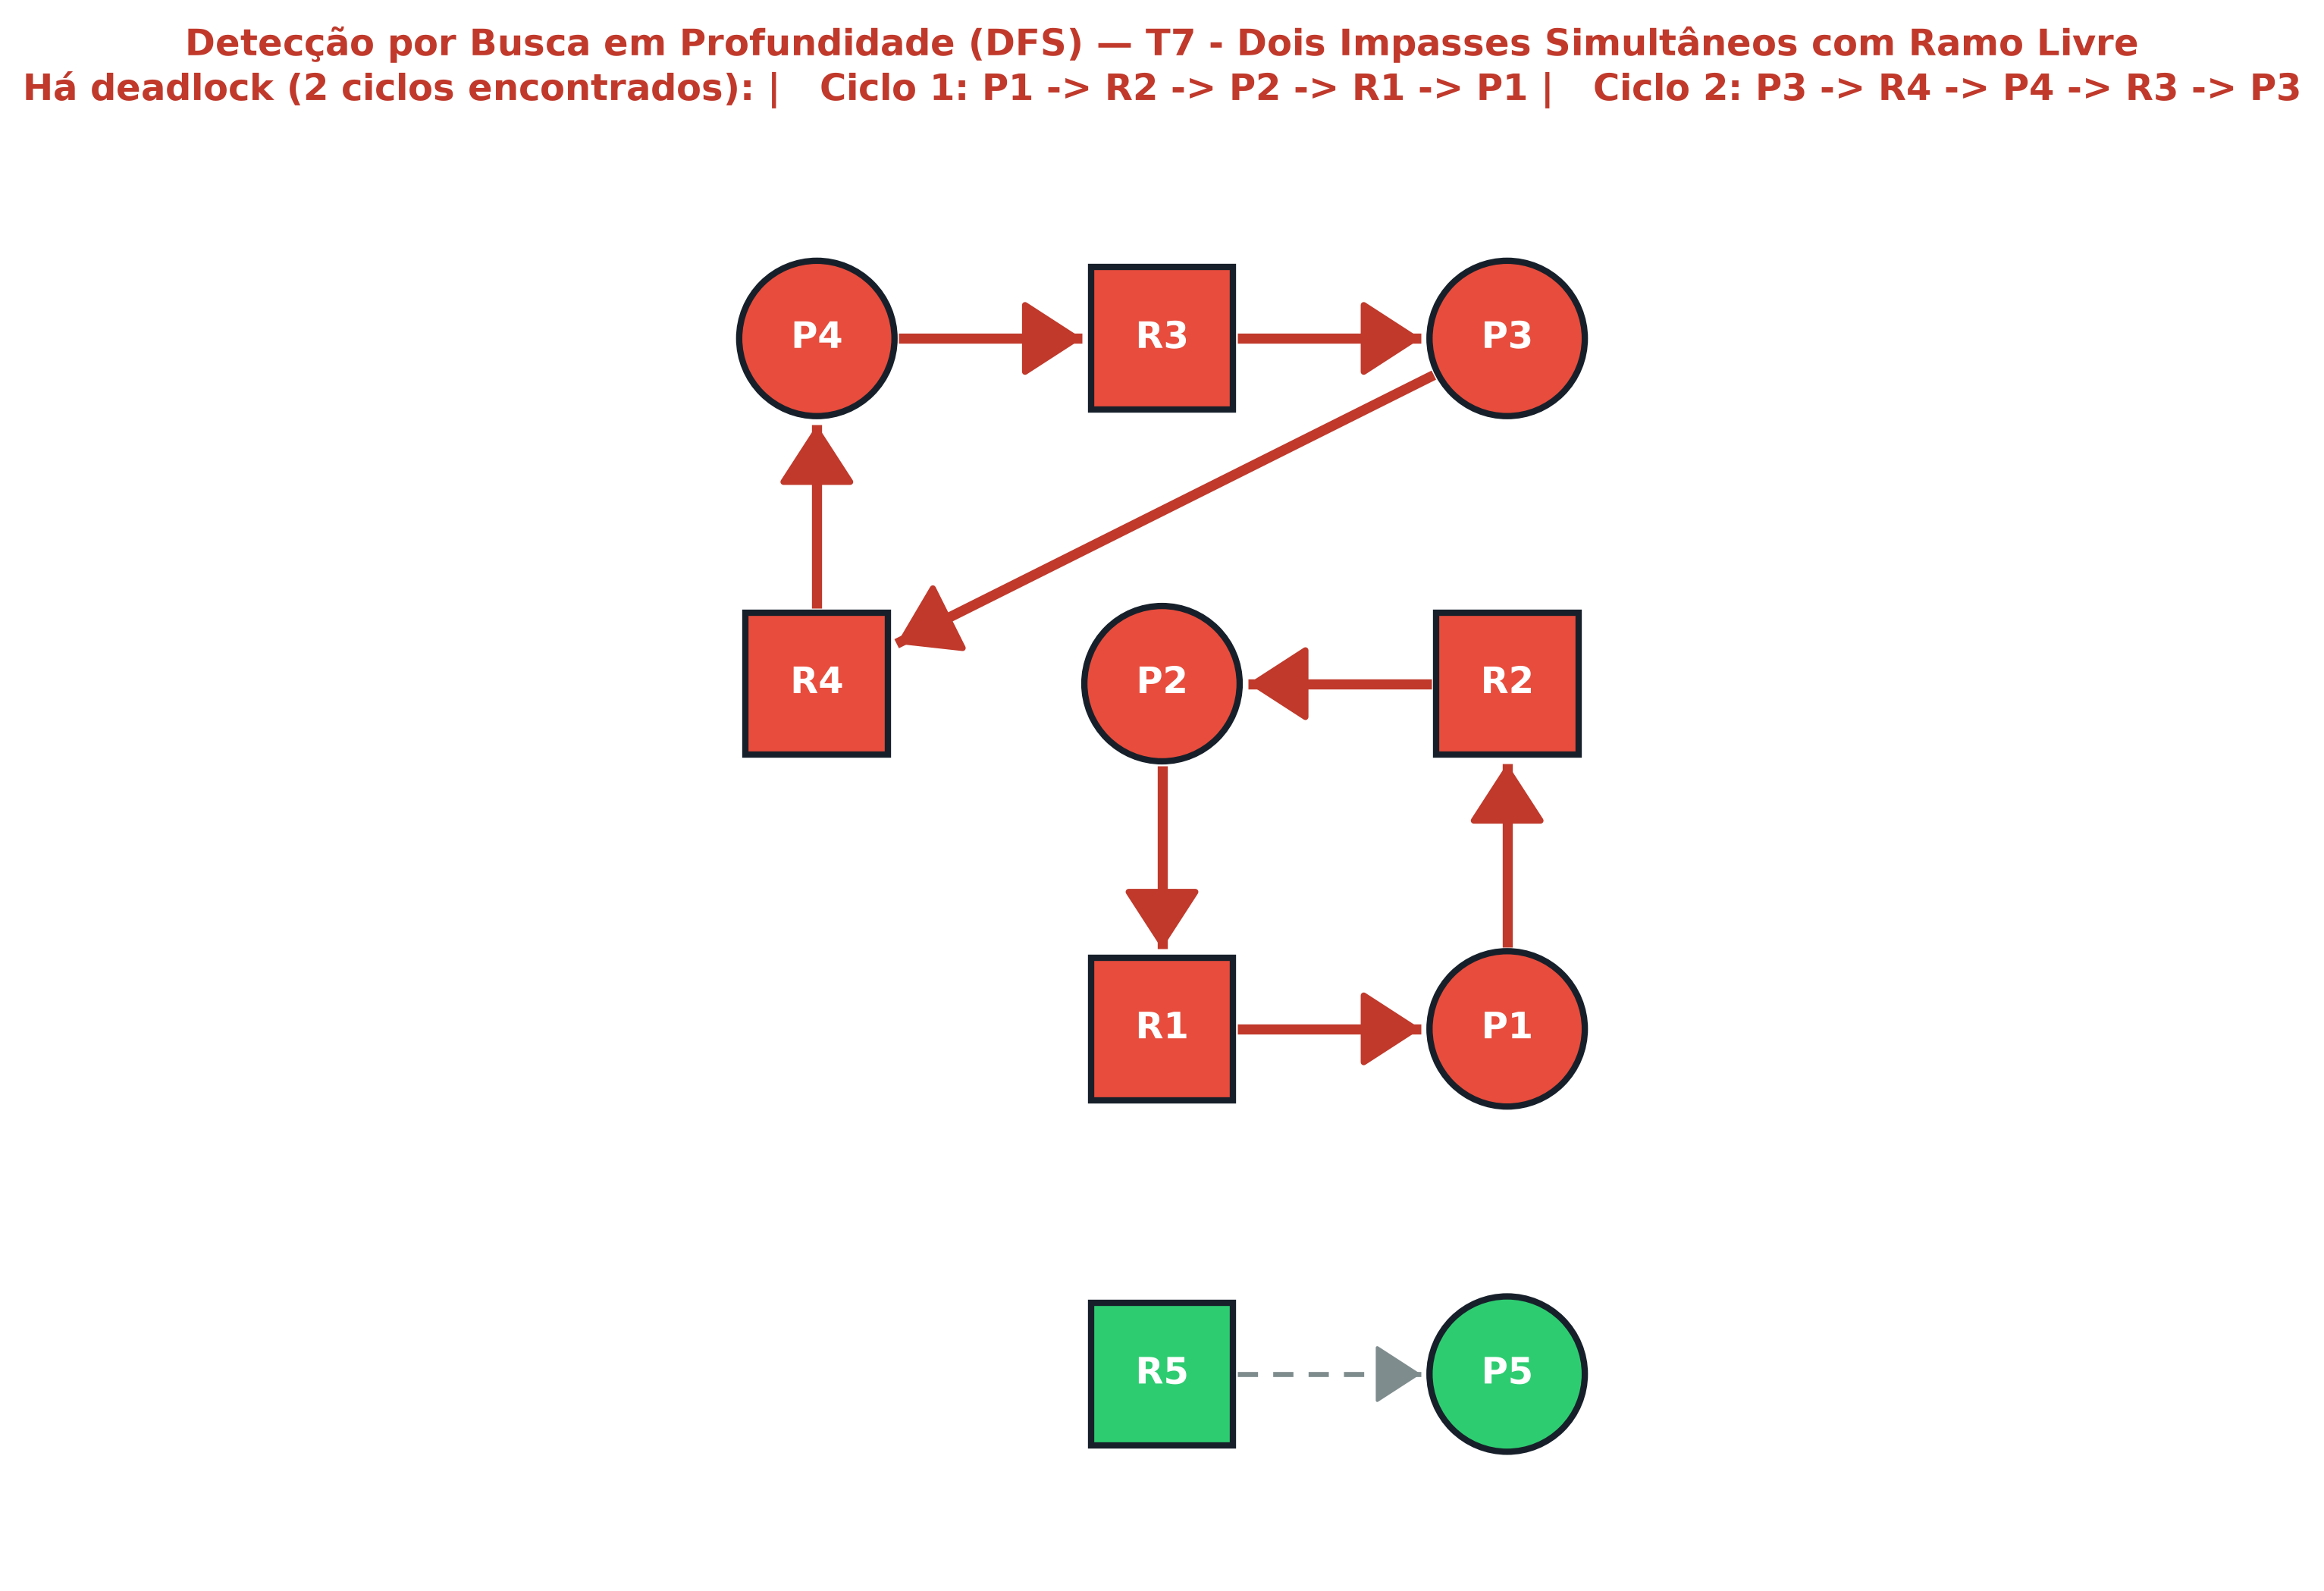

In [6]:
# [PASSO 5.4 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Execução dos casos opcionais em laço.
resultados_opcionais = {}
for caso in CASOS_DE_TESTE_OFICIAIS:
    if caso.obrigatorio:
        continue
    print(f"\n=== {caso.sigla} - {caso.titulo} ===")
    resultados_opcionais[caso.sigla] = executar_analise_completa_caso(
        sigla=caso.sigla,
        titulo=caso.titulo,
        nome_arquivo_txt=caso.arquivo,
        buscar_todos=caso.buscar_todos,
        exibir_rastreamento_dfs=False
    )


<!-- [PASSO 5.5 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta] — Texto da validação final. -->

---

## 9. Validação Automatizada do Gabarito (`src/etapa6_testes_validacao_nauan.py`)

Por fim, `validar_gabarito_caso()` compara a saída de cada caso com o gabarito declarado na Etapa 6, caractere a caractere, e indica se o caso é obrigatório ou opcional. Em seguida, a célula lista as imagens gravadas em `output/figures/` e confere o total: três por caso, ou seja, 21 para os 7 casos.


In [7]:
# [PASSO 5.5 | FASE 5 | branch: fase-5/notebook | commit e push: Pamella Roberta]
# Validação do gabarito e listagem das figuras.
resultados = {"T1": res_T1, "T2": res_T2, "T3": res_T3, **resultados_opcionais}

aprovados = 0
for caso in CASOS_DE_TESTE_OFICIAIS:
    validacao = validar_gabarito_caso(caso.sigla, resultados[caso.sigla]["veredito"], caso.esperado)
    marca = "obrigatório" if caso.obrigatorio else "opcional"
    saida_inline = validacao["saida_obtida"].replace("\n", " | ")
    aprovados += validacao["status"].startswith("APROVADO")
    print(f"[{caso.sigla}] ({marca}) {validacao['status']} | Saída: {saida_inline}")
print(f"\n{aprovados} de {len(CASOS_DE_TESTE_OFICIAIS)} casos aprovados.")

figuras = sorted(f for f in os.listdir(PASTA_FIGURAS) if f.endswith(".png"))
print(f"\nFiguras PNG gravadas em 'output/figures/' ({len(figuras)} de {3 * len(CASOS_DE_TESTE_OFICIAIS)} esperadas):")
for arquivo_png in figuras:
    print(f"  - {arquivo_png}")


[T1] (obrigatório) APROVADO (PASS) | Saída: Há deadlock (D -> T -> E -> V -> G -> U -> D)
[T2] (obrigatório) APROVADO (PASS) | Saída: Há deadlock (D -> T -> E -> V -> Z -> U -> D)
[T3] (obrigatório) APROVADO (PASS) | Saída: Sem deadlock
[T4] (opcional) APROVADO (PASS) | Saída: Há deadlock (2 ciclos encontrados): |   Ciclo 1: A -> S -> B -> R -> A |   Ciclo 2: C -> U -> D -> T -> C
[T5] (opcional) APROVADO (PASS) | Saída: Há deadlock (A -> S -> B -> T -> C -> R -> A)
[T6] (opcional) APROVADO (PASS) | Saída: Sem deadlock
[T7] (opcional) APROVADO (PASS) | Saída: Há deadlock (2 ciclos encontrados): |   Ciclo 1: P1 -> R2 -> P2 -> R1 -> P1 |   Ciclo 2: P3 -> R4 -> P4 -> R3 -> P3

7 de 7 casos aprovados.

Figuras PNG gravadas em 'output/figures/' (21 de 21 esperadas):
  - T1_grafo_da_aula_com_beco_sem_saida_e_ciclo_cartao.png
  - T1_grafo_da_aula_com_beco_sem_saida_e_ciclo_grafo_alocacao.png
  - T1_grafo_da_aula_com_beco_sem_saida_e_ciclo_grafo_deteccao_dfs.png
  - T2_grafo_1_do_enunciado_com